## CI Model

CI long-format trajectory file:
C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab\Continuous AVT v1\individual_data_CI\causal_inference_analyses\trial_level_pcommon_confidence_long.csv

LOADED CI TRAJECTORY DATA
Rows: 1,650,000
Participants: 50
Trials: 5500
analysis_group
fixed_10          300000
fixed_40          300000
fixed_20          300000
fixed_30          300000
sweep_converge    150000
congruent         150000
sweep_diverge     150000
Name: count, dtype: int64

STATIC EQUILIBRIUM MODEL
       static_curve_r2  static_curve_pse_deg  \
count        50.000000             44.000000   
mean          0.816327             22.578734   
std           0.219988              7.419175   
min           0.000000              4.989451   
25%           0.775707             19.719935   
50%           0.901867             24.064064   
75%           0.979929             26.750854   
max           0.999543             35.927889   

       static_curve_pse_extrapolated_deg  
count             

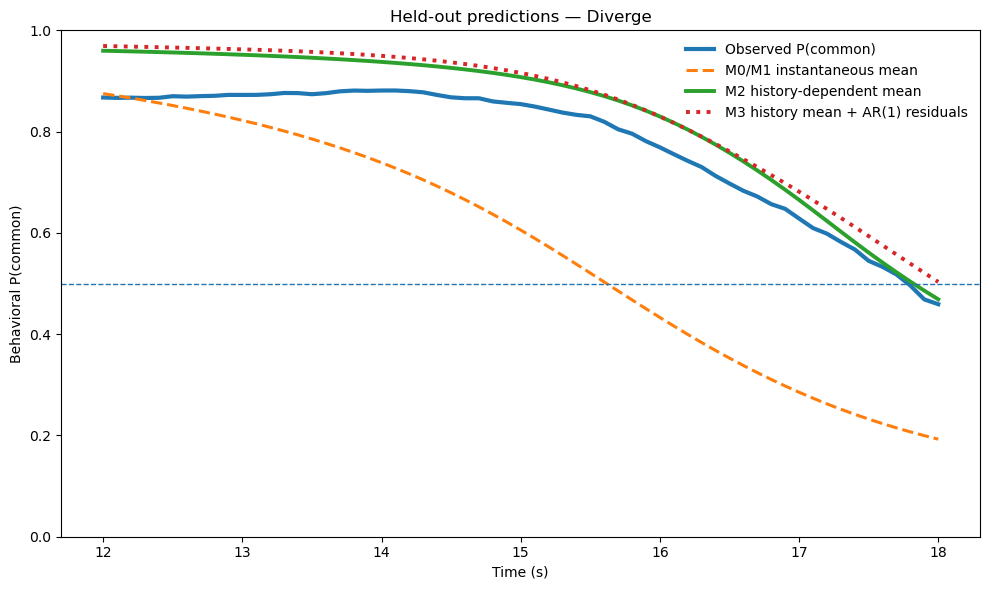

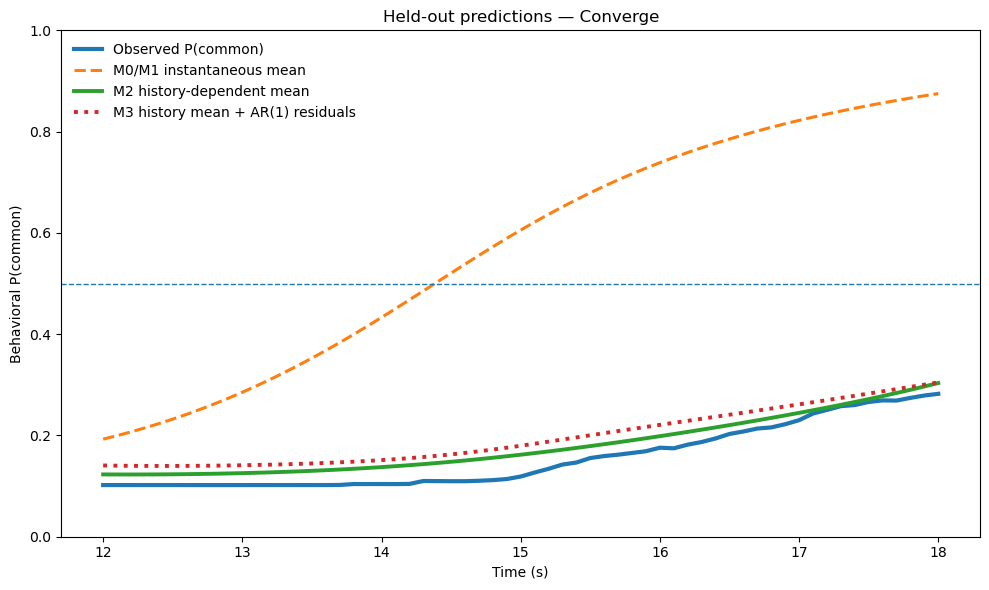

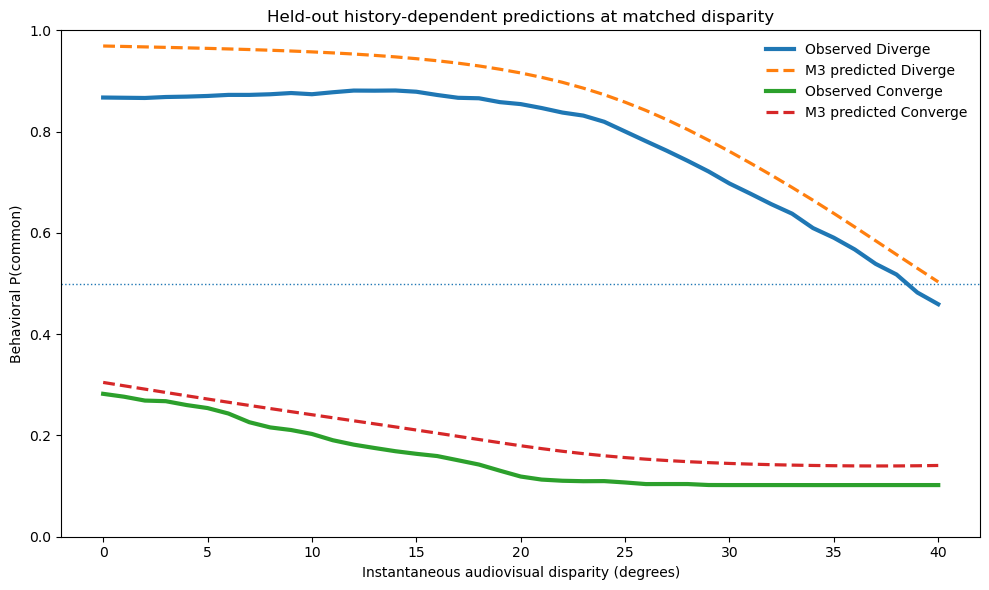

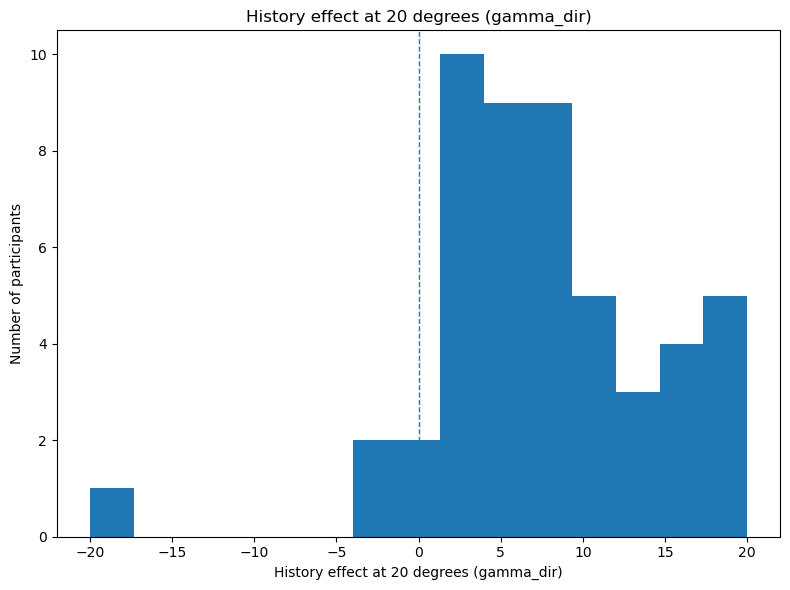

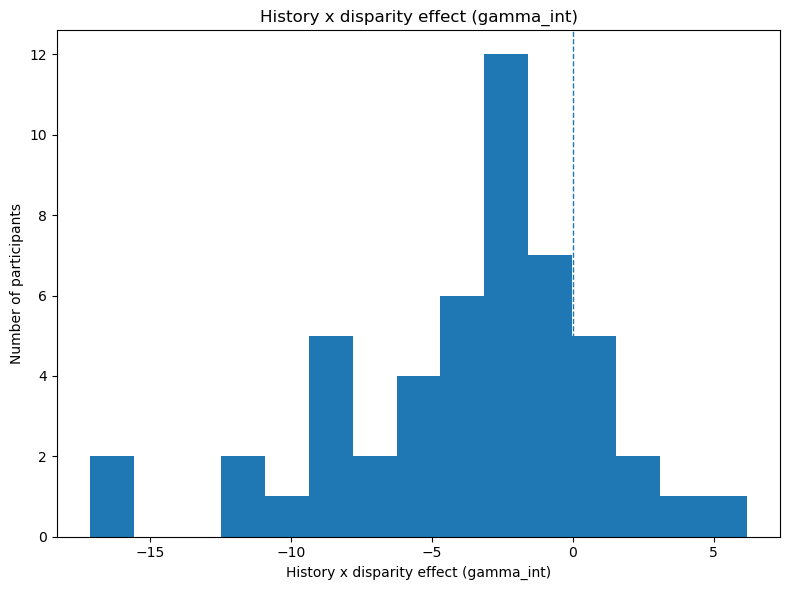

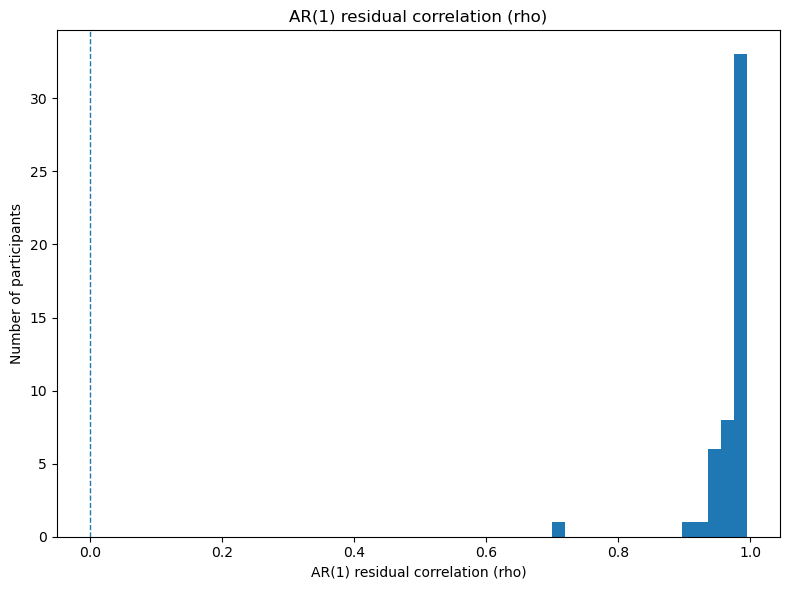

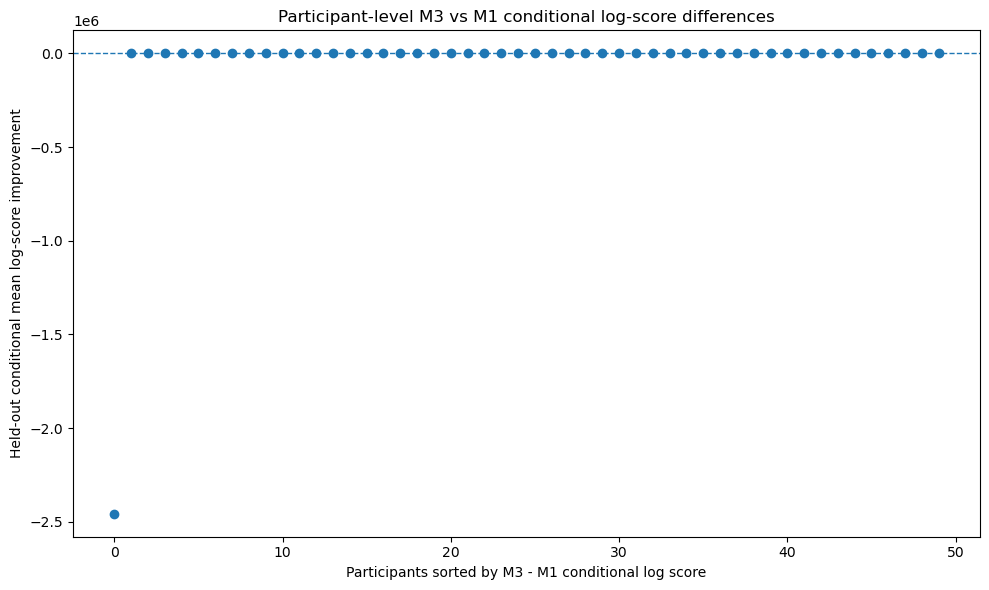

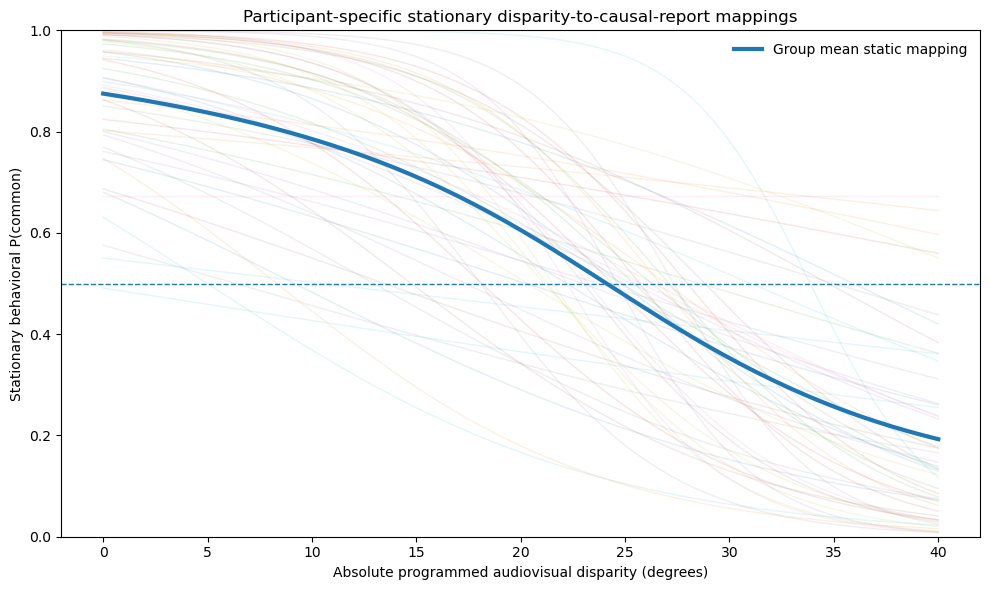


ROBUST HISTORY-DEPENDENT CAUSAL-INFERENCE MODEL

Participants modeled: 50
Whole-trial CV folds: 5
Model sampling: 10.0 Hz

M0: instantaneous stationary mean + IID residuals.
M1: instantaneous stationary mean + conditional AR(1) residual covariance.
M2: history-dependent mean + IID residuals.
M3: history-dependent mean + conditional AR(1) residual covariance.

PRIMARY PREDICTIVE TEST: M3 VS M1
Both models accommodate serial residual correlation; only M3 allows sensory history to alter expected P(common).
Held-out RMSE improvement: M=0.173745, median=0.165900, 95% bootstrap mean CI [0.125808, 0.222383], two-sided permutation p=0.000200, directional permutation p=0.000200, Wilcoxon p=0.000000, participants favoring M3=43/50.
Relative held-out predictive R2 improvement: M=0.426939, median=0.554844, 95% bootstrap mean CI [0.287550, 0.554246], two-sided permutation p=0.000200, directional permutation p=0.000200, Wilcoxon p=0.000002, participants favoring M3=43/50.
Conditional mean log-score

In [15]:
# %% ==========================================================================
# ROBUST HISTORY-DEPENDENT CAUSAL-INFERENCE MODEL WITH AR(1) RESIDUALS
# =============================================================================
#
# This revised pipeline addresses the main diagnostics raised by the first
# history + AR(1) analysis:
#   1) the history term affects the CONDITIONAL MEAN; AR(1) only models residual
#      covariance and can never generate the predicted hysteresis itself;
#   2) AR(1) likelihood is now CONDITIONAL on the first residual in each held-out
#      trial, avoiding instability from the exact stationary first-observation
#      variance when rho is near 1;
#   3) held-out likelihood is reported both as TOTAL conditional log likelihood
#      and as MEAN conditional log score per innovation;
#   4) the primary predictive comparison is M3 vs M1 held-out RMSE / predictive
#      R^2; conditional AR(1) log score is a covariance-aware secondary test;
#   5) rho and gamma bounds are widened and boundary diagnostics are explicit;
#   6) optional whole-trial CV sensitivity analyses test alternate rho and gamma
#      bounds;
#   7) parameter sensitivity and likelihood-outlier diagnostics are saved;
#   8) PSEs outside the observed 0-40 degree range are retained only as
#      extrapolated diagnostics, not treated as valid observed-range PSEs.
#
# MODEL HIERARCHY
# ---------------
# M0: instantaneous stationary mean + IID residuals
# M1: instantaneous stationary mean + conditional AR(1) residual covariance
# M2: history-dependent mean + IID residuals
# M3: history-dependent mean + conditional AR(1) residual covariance
#
# History model:
#   logit(mu_t) = logit[f_i(D_t)] + gamma_dir*H + gamma_int*H*X_t
#   H = +0.5 Diverge, -0.5 Converge
#   X_t = (D_t - 20)/20
#
# PRIMARY TEST
# ------------
# M3 vs M1 on held-out whole sweep trials.
# Both models accommodate serial residual dependence; only M3 allows the
# expected causal report to depend on sensory history.
#
# IMPORTANT INTERPRETATION
# ------------------------
# rho = residual temporal autocorrelation. It is NOT labeled motor persistence.
# A superior M3 demonstrates predictive history dependence after accounting for
# serially correlated residuals; it does not uniquely identify the mechanism.
# =============================================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares, minimize, minimize_scalar
from scipy.special import expit, logit
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

# =============================================================================
# USER SETTINGS
# =============================================================================

RANDOM_SEED = 20260824

DATA_DIR = Path(
    r"C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab"
    r"\Continuous AVT v1\individual_data_CI"
)
CI_ANALYSIS_DIR = DATA_DIR / "causal_inference_analyses"

OUT_DIR = CI_ANALYSIS_DIR / "analysis_models" / "history_ar1_model_robust"
CSV_DIR = OUT_DIR / "csv_outputs"
FIG_DIR = OUT_DIR / "figures"
for directory in [OUT_DIR, CSV_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

LONG_CSV_CANDIDATES = [
    CI_ANALYSIS_DIR / "trial_level_pcommon_confidence_long.csv",
    CI_ANALYSIS_DIR / "trial_level_pcommon_confidence_long_plus_all.csv",
]

SUBJECT_SUMMARY_CANDIDATES = [
    CI_ANALYSIS_DIR
    / "analysis_4_to_10_sweep_thresholds_hysteresis"
    / "analysis_10_subject_level_summary"
    / "subject_summary.csv",
    CI_ANALYSIS_DIR
    / "analysis_4_to_10_sweep_thresholds_hysteresis"
    / "analysis_10_subject_level_summary"
    / "subject_level_threshold_hysteresis_confidence_summary.csv",
]

TRIAL_DURATION_S = 18.0
SWEEP_TRANSITION_S = 12.0
SWEEP_MAX_DISPARITY_DEG = 40.0
SWEEP_DURATION_S = TRIAL_DURATION_S - SWEEP_TRANSITION_S
SWEEP_RATE_DEG_PER_S = SWEEP_MAX_DISPARITY_DEG / SWEEP_DURATION_S

STATIC_MAPPING_START_S = 6.0
STATIC_MAPPING_END_S = 17.5
DYNAMIC_START_S = 12.0
DYNAMIC_END_S = 18.0

MODEL_HZ = 16.61
MODEL_DT_S = 1.0 / MODEL_HZ

N_FOLDS = 5
MIN_SWEEP_TRIALS = 10
MIN_TRAIN_TRIALS = 6

N_BOOT = 5000
N_PERM = 5000
PROB_EPS = 1e-5
NUMERIC_VAR_FLOOR = 1e-12

# Main bounds. These are wider than in the previous pipeline.
RHO_LOWER = -0.995
RHO_UPPER = 0.995
GAMMA_LOWER = -20.0
GAMMA_UPPER = 20.0

# Diagnostics only; they do not alter fitting.
RHO_BOUNDARY_TOL = 0.002
GAMMA_BOUNDARY_TOL = 0.25
SIGMA_DIAGNOSTIC_THRESHOLD = 0.005

INCLUDE_HISTORY_X_DISPARITY = True

# Optional sensitivity analysis. This reruns the PRIMARY M3-vs-M1 CV comparison
# under alternate bounds. It can add runtime; set False if you only want the
# main analysis first.
RUN_FULL_CV_SENSITIVITY = True
SENSITIVITY_SETTINGS = [
    {"label": "rho_0p980_gamma20", "rho_upper": 0.980, "gamma_abs": 20.0},
    {"label": "rho_0p995_gamma10", "rho_upper": 0.995, "gamma_abs": 10.0},
    {"label": "rho_0p995_gamma40", "rho_upper": 0.995, "gamma_abs": 40.0},
    {"label": "rho_0p999_gamma20", "rho_upper": 0.999, "gamma_abs": 20.0},
]

# =============================================================================
# BASIC HELPERS
# =============================================================================

def normalize_subject_id(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    match = re.search(r"pid\s*0*(\d+)", text)
    if match:
        return f"pid{int(match.group(1)):03d}"
    match = re.search(r"(\d+)", text)
    if match:
        return f"pid{int(match.group(1)):03d}"
    return text


def find_existing_file(candidates, label):
    for path in candidates:
        if Path(path).exists():
            print(f"{label}:\n{path}\n")
            return Path(path)
    raise FileNotFoundError(
        f"Could not find {label}.\nChecked:\n"
        + "\n".join(str(path) for path in candidates)
    )


def safe_numeric(series):
    return pd.to_numeric(series, errors="coerce")


def clip_probability(values):
    return np.clip(np.asarray(values, dtype=float), PROB_EPS, 1.0 - PROB_EPS)


def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=RANDOM_SEED):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        boot[i] = np.mean(rng.choice(values, size=len(values), replace=True))
    return float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


def bootstrap_median_ci(values, n_boot=N_BOOT, seed=RANDOM_SEED):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        boot[i] = np.median(rng.choice(values, size=len(values), replace=True))
    return float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


def sign_flip_test(values, n_perm=N_PERM, seed=RANDOM_SEED, alternative="two-sided"):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan
    observed = float(np.mean(values))
    rng = np.random.default_rng(seed)
    null_means = np.empty(n_perm, dtype=float)
    for i in range(n_perm):
        signs = rng.choice([-1.0, 1.0], size=len(values))
        null_means[i] = np.mean(values * signs)
    if alternative == "greater":
        return float((np.sum(null_means >= observed) + 1) / (n_perm + 1))
    if alternative == "less":
        return float((np.sum(null_means <= observed) + 1) / (n_perm + 1))
    return float(
        (np.sum(np.abs(null_means) >= abs(observed)) + 1) / (n_perm + 1)
    )


def bootstrap_corr_ci(x, y, n_boot=N_BOOT, seed=RANDOM_SEED):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < 5:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), size=len(x))
        xb, yb = x[idx], y[idx]
        if np.std(xb) <= 1e-12 or np.std(yb) <= 1e-12:
            continue
        vals.append(np.corrcoef(xb, yb)[0, 1])
    if not vals:
        return np.nan, np.nan
    vals = np.asarray(vals, dtype=float)
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def permutation_corr_test(x, y, n_perm=N_PERM, seed=RANDOM_SEED):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < 5 or np.std(x) <= 1e-12 or np.std(y) <= 1e-12:
        return np.nan
    observed = np.corrcoef(x, y)[0, 1]
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        null[i] = np.corrcoef(x, rng.permutation(y))[0, 1]
    return float((np.sum(np.abs(null) >= abs(observed)) + 1) / (n_perm + 1))


# =============================================================================
# LOAD AND CLEAN CI DATA
# =============================================================================

LONG_CSV = find_existing_file(LONG_CSV_CANDIDATES, "CI long-format trajectory file")
ci = pd.read_csv(LONG_CSV)

required_columns = {"participant_id", "trial_id", "analysis_group", "time_s", "p_common"}
missing_columns = required_columns - set(ci.columns)
if missing_columns:
    raise ValueError(f"CI long-format dataset is missing: {sorted(missing_columns)}")

ci = ci[
    ci["analysis_group"].astype(str).str.lower().ne("all_trials")
].copy()
ci["participant_id"] = ci["participant_id"].apply(normalize_subject_id)
ci["time_s"] = safe_numeric(ci["time_s"])
ci["p_common"] = safe_numeric(ci["p_common"])
ci["analysis_group"] = ci["analysis_group"].astype(str).str.strip().str.lower()
ci = ci.replace([np.inf, -np.inf], np.nan)
ci = ci.dropna(
    subset=["participant_id", "trial_id", "analysis_group", "time_s", "p_common"]
).copy()
ci["p_common"] = ci["p_common"].clip(0.0, 1.0)

print("=" * 90)
print("LOADED CI TRAJECTORY DATA")
print("=" * 90)
print(f"Rows: {len(ci):,}")
print(f"Participants: {ci['participant_id'].nunique()}")
print(f"Trials: {ci['trial_id'].nunique()}")
print(ci["analysis_group"].value_counts())

# =============================================================================
# RECONSTRUCT CURRENT ABSOLUTE AUDIOVISUAL DISPARITY
# =============================================================================

def instantaneous_disparity_deg(analysis_group, time_s):
    ag = str(analysis_group).lower()
    t = float(time_s)

    if ag == "congruent":
        return 0.0

    fixed_lookup = {
        "fixed_10": 10.0,
        "fixed_20": 20.0,
        "fixed_30": 30.0,
        "fixed_40": 40.0,
    }

    if ag in fixed_lookup:
        return fixed_lookup[ag]

    if ag == "sweep_diverge":
        if t <= SWEEP_TRANSITION_S:
            return 0.0
        return float(
            np.clip(
                SWEEP_RATE_DEG_PER_S * (t - SWEEP_TRANSITION_S),
                0.0,
                SWEEP_MAX_DISPARITY_DEG,
            )
        )

    if ag == "sweep_converge":
        if t <= SWEEP_TRANSITION_S:
            return SWEEP_MAX_DISPARITY_DEG
        return float(
            np.clip(
                SWEEP_MAX_DISPARITY_DEG
                - SWEEP_RATE_DEG_PER_S * (t - SWEEP_TRANSITION_S),
                0.0,
                SWEEP_MAX_DISPARITY_DEG,
            )
        )

    return np.nan


ci["abs_disparity_deg"] = [
    instantaneous_disparity_deg(ag, t)
    for ag, t in zip(ci["analysis_group"], ci["time_s"])
]

ci["sweep_direction"] = np.where(
    ci["analysis_group"].eq("sweep_diverge"),
    "Diverge",
    np.where(
        ci["analysis_group"].eq("sweep_converge"),
        "Converge",
        np.nan,
    ),
)

ci.to_csv(
    CSV_DIR / "ci_history_ar1_model_input.csv",
    index=False,
)

# =============================================================================
# STATIC EQUILIBRIUM MAPPING
# =============================================================================

STATIC_GROUPS = [
    "congruent",
    "fixed_10",
    "fixed_20",
    "fixed_30",
    "fixed_40",
]

static_df = ci[
    ci["analysis_group"].isin(STATIC_GROUPS)
    & ci["time_s"].between(
        STATIC_MAPPING_START_S,
        STATIC_MAPPING_END_S,
        inclusive="both",
    )
].copy()

static_subject_curve = (
    static_df
    .groupby(
        ["participant_id", "abs_disparity_deg"],
        as_index=False,
    )
    .agg(
        mean_p_common=("p_common", "mean"),
        sd_p_common=("p_common", "std"),
        n_timepoints=("p_common", "size"),
        n_trials=("trial_id", "nunique"),
    )
)

static_subject_curve.to_csv(
    CSV_DIR / "static_equilibrium_subject_curve.csv",
    index=False,
)


def logistic_equilibrium(disparity, alpha, beta):
    disparity = np.asarray(disparity, dtype=float)
    return expit(alpha - beta * disparity)


def fit_static_curve(data):
    data = (
        data
        .dropna(
            subset=["abs_disparity_deg", "mean_p_common"]
        )
        .sort_values("abs_disparity_deg")
        .copy()
    )

    x = data["abs_disparity_deg"].to_numpy(dtype=float)
    y = data["mean_p_common"].to_numpy(dtype=float)

    if len(x) < 4 or np.unique(x).size < 4:
        return None

    y0 = np.clip(
        y[np.argmin(x)],
        0.01,
        0.99,
    )

    alpha0 = float(logit(y0))
    beta0 = 0.10

    def residuals(params):
        alpha, beta = params
        return y - logistic_equilibrium(x, alpha, beta)

    try:
        fit = least_squares(
            residuals,
            x0=[alpha0, beta0],
            bounds=(
                [-20.0, 0.0],
                [20.0, 2.0],
            ),
        )

        alpha = float(fit.x[0])
        beta = float(fit.x[1])

        pred = logistic_equilibrium(
            x,
            alpha,
            beta,
        )

        sse = float(
            np.sum(
                (y - pred) ** 2
            )
        )

        sst = float(
            np.sum(
                (y - np.mean(y)) ** 2
            )
        )

        r2 = (
            1.0 - sse / sst
            if sst > 0
            else np.nan
        )

        raw_pse = (
            alpha / beta
            if beta > 1e-8
            else np.nan
        )

        valid = bool(
            np.isfinite(raw_pse)
            and 0.0 <= raw_pse <= 40.0
        )

        return {
            "alpha": alpha,
            "beta": beta,
            "static_curve_r2": r2,
            "static_curve_pse_deg": (
                float(raw_pse)
                if valid
                else np.nan
            ),
            "static_curve_pse_extrapolated_deg": raw_pse,
            "pse_in_observed_range": valid,
            "static_curve_fit_success": bool(fit.success),
        }

    except Exception:
        return None


static_fit_rows = []

for participant_id, group in static_subject_curve.groupby(
    "participant_id"
):

    result = fit_static_curve(group)

    if result is None:
        result = {
            "alpha": np.nan,
            "beta": np.nan,
            "static_curve_r2": np.nan,
            "static_curve_pse_deg": np.nan,
            "static_curve_pse_extrapolated_deg": np.nan,
            "pse_in_observed_range": False,
            "static_curve_fit_success": False,
        }

    static_fit_rows.append(
        {
            "participant_id": participant_id,
            **result,
        }
    )


static_fit_df = pd.DataFrame(
    static_fit_rows
)

static_fit_df.to_csv(
    CSV_DIR / "static_equilibrium_model_parameters.csv",
    index=False,
)

static_param_lookup = (
    static_fit_df
    .set_index("participant_id")
    .to_dict(orient="index")
)

print("\n" + "=" * 90)
print("STATIC EQUILIBRIUM MODEL")
print("=" * 90)

print(
    static_fit_df[
        [
            "static_curve_r2",
            "static_curve_pse_deg",
            "static_curve_pse_extrapolated_deg",
        ]
    ].describe()
)

print("\nPSE inside tested 0–40 degree range:")
print(
    static_fit_df[
        "pse_in_observed_range"
    ].value_counts()
)


def f_static(participant_id, disparity):

    disparity = np.asarray(
        disparity,
        dtype=float,
    )

    pars = static_param_lookup.get(
        participant_id
    )

    if pars is None:
        return np.full_like(
            disparity,
            np.nan,
            dtype=float,
        )

    alpha = pars.get(
        "alpha",
        np.nan,
    )

    beta = pars.get(
        "beta",
        np.nan,
    )

    if (
        not np.isfinite(alpha)
        or not np.isfinite(beta)
    ):
        return np.full_like(
            disparity,
            np.nan,
            dtype=float,
        )

    return logistic_equilibrium(
        disparity,
        alpha,
        beta,
    )

# =============================================================================
# PREPARE SWEEP TRIALS AT MODEL_HZ
# =============================================================================

SWEEP_GROUPS = [
    "sweep_diverge",
    "sweep_converge",
]

DYNAMIC_GRID = np.arange(
    DYNAMIC_START_S,
    DYNAMIC_END_S + MODEL_DT_S / 2.0,
    MODEL_DT_S,
)


def interpolate_trial(
    trial_df,
    grid,
    value_col="p_common",
):

    group = (
        trial_df
        .dropna(
            subset=[
                "time_s",
                value_col,
            ]
        )
        .sort_values("time_s")
        .copy()
    )

    if len(group) < 2:
        return None

    time = group[
        "time_s"
    ].to_numpy(dtype=float)

    values = group[
        value_col
    ].to_numpy(dtype=float)

    unique_time, unique_idx = np.unique(
        time,
        return_index=True,
    )

    values = values[
        unique_idx
    ]

    if len(unique_time) < 2:
        return None

    return np.interp(
        grid,
        unique_time,
        values,
    )


def sweep_disparity_on_grid(
    analysis_group,
    grid,
):

    if analysis_group == "sweep_diverge":

        disparity = (
            SWEEP_RATE_DEG_PER_S
            * (
                grid
                - SWEEP_TRANSITION_S
            )
        )

    elif analysis_group == "sweep_converge":

        disparity = (
            SWEEP_MAX_DISPARITY_DEG
            - SWEEP_RATE_DEG_PER_S
            * (
                grid
                - SWEEP_TRANSITION_S
            )
        )

    else:
        return np.full(
            len(grid),
            np.nan,
        )

    return np.clip(
        disparity,
        0.0,
        SWEEP_MAX_DISPARITY_DEG,
    )


def prepare_sweep_trial(
    participant_id,
    trial_df,
):

    groups = (
        trial_df[
            "analysis_group"
        ]
        .dropna()
        .unique()
    )

    if len(groups) != 1:
        return None

    analysis_group = str(
        groups[0]
    )

    if analysis_group not in SWEEP_GROUPS:
        return None

    observed = interpolate_trial(
        trial_df,
        DYNAMIC_GRID,
        "p_common",
    )

    if observed is None:
        return None

    disparity = sweep_disparity_on_grid(
        analysis_group,
        DYNAMIC_GRID,
    )

    equilibrium = f_static(
        participant_id,
        disparity,
    )

    if not np.all(
        np.isfinite(
            equilibrium
        )
    ):
        return None

    direction = (
        "Diverge"
        if analysis_group
        == "sweep_diverge"
        else "Converge"
    )

    history_code = (
        0.5
        if direction
        == "Diverge"
        else -0.5
    )

    disparity_scaled = (
        disparity
        - 20.0
    ) / 20.0

    return {
        "participant_id": participant_id,
        "trial_id": trial_df[
            "trial_id"
        ].iloc[0],
        "analysis_group": analysis_group,
        "direction": direction,
        "history_code": history_code,
        "time_s": DYNAMIC_GRID.copy(),
        "disparity_deg": disparity.copy(),
        "disparity_scaled": disparity_scaled.copy(),
        "observed": observed.copy(),
        "equilibrium": equilibrium.copy(),
    }


prepared_trials = []

sweep_raw = ci[
    ci[
        "analysis_group"
    ].isin(
        SWEEP_GROUPS
    )
].copy()

for (
    participant_id,
    trial_id,
), trial in sweep_raw.groupby(
    [
        "participant_id",
        "trial_id",
    ]
):

    prepared = prepare_sweep_trial(
        participant_id,
        trial,
    )

    if prepared is not None:
        prepared_trials.append(
            prepared
        )

print("\n" + "=" * 90)
print("PREPARED SWEEP DATA")
print("=" * 90)
print(
    f"Prepared sweep trials: "
    f"{len(prepared_trials):,}"
)
print(
    "Participants:",
    len(
        {
            x["participant_id"]
            for x
            in prepared_trials
        }
    ),
)

# =============================================================================
# MEAN MODELS
# =============================================================================

def predict_instantaneous(
    trial,
):
    return np.asarray(
        trial["equilibrium"],
        dtype=float,
    ).copy()


def predict_history_mean(
    trial,
    gamma_dir,
    gamma_int=0.0,
):

    baseline = clip_probability(
        trial[
            "equilibrium"
        ]
    )

    eta = logit(
        baseline
    )

    h = float(
        trial[
            "history_code"
        ]
    )

    eta_history = (
        eta
        + gamma_dir
        * h
    )

    if INCLUDE_HISTORY_X_DISPARITY:

        eta_history = (
            eta_history
            + gamma_int
            * h
            * np.asarray(
                trial[
                    "disparity_scaled"
                ],
                dtype=float,
            )
        )

    return expit(
        eta_history
    )


def get_trial_residuals(
    trials,
    model_name,
    gamma_dir=0.0,
    gamma_int=0.0,
):

    residual_sequences = []

    for trial in trials:

        observed = np.asarray(
            trial[
                "observed"
            ],
            dtype=float,
        )

        if model_name == "instantaneous":

            predicted = predict_instantaneous(
                trial
            )

        elif model_name == "history":

            predicted = predict_history_mean(
                trial,
                gamma_dir,
                gamma_int,
            )

        else:
            raise ValueError(
                f"Unknown model_name: "
                f"{model_name}"
            )

        mask = (
            np.isfinite(
                observed
            )
            & np.isfinite(
                predicted
            )
        )

        residual = (
            observed[
                mask
            ]
            - predicted[
                mask
            ]
        )

        if len(residual) >= 2:
            residual_sequences.append(
                residual
            )

    return residual_sequences

# =============================================================================
# IID GAUSSIAN RESIDUAL MODEL
# =============================================================================

def fit_iid_error(
    residual_sequences,
):

    if not residual_sequences:
        return {
            "sigma": np.nan,
            "loglik": -np.inf,
            "n_obs": 0,
        }

    residual = np.concatenate(
        residual_sequences
    )

    residual = residual[
        np.isfinite(
            residual
        )
    ]

    if len(residual) < 2:
        return {
            "sigma": np.nan,
            "loglik": -np.inf,
            "n_obs": len(residual),
        }

    sigma2 = max(
        float(
            np.mean(
                residual ** 2
            )
        ),
        NUMERIC_VAR_FLOOR,
    )

    sigma = float(
        np.sqrt(
            sigma2
        )
    )

    n = len(
        residual
    )

    ll = (
        -0.5
        * n
        * (
            np.log(
                2.0
                * np.pi
                * sigma2
            )
            + 1.0
        )
    )

    return {
        "sigma": sigma,
        "loglik": float(ll),
        "n_obs": int(n),
    }


def iid_loglik_test(
    residual_sequences,
    sigma,
):

    sigma2 = max(
        float(sigma) ** 2,
        NUMERIC_VAR_FLOOR,
    )

    total_ll = 0.0
    total_n = 0

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(
                residual
            )
        ]

        if len(residual) == 0:
            continue

        total_ll += (
            -0.5
            * (
                len(residual)
                * np.log(
                    2.0
                    * np.pi
                    * sigma2
                )
                + np.sum(
                    residual ** 2
                )
                / sigma2
            )
        )

        total_n += len(
            residual
        )

    mean_score = (
        total_ll
        / total_n
        if total_n > 0
        else np.nan
    )

    return (
        float(total_ll),
        int(total_n),
        float(mean_score),
    )

# =============================================================================
# CONDITIONAL AR(1) RESIDUAL COVARIANCE MODEL
# =============================================================================
#
# We condition on the first residual in each trial and evaluate only
# innovations e_t - rho e_(t-1), t >= 2. This removes the unstable exact
# stationary first-observation variance term when rho approaches 1.
# =============================================================================

def ar1_profile_nll_given_rho(
    residual_sequences,
    rho,
    rho_lower,
    rho_upper,
):

    rho = float(
        np.clip(
            rho,
            rho_lower,
            rho_upper,
        )
    )

    innovation_ss = 0.0
    n_innov = 0

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(
                residual
            )
        ]

        if len(residual) < 2:
            continue

        innovations = (
            residual[
                1:
            ]
            - rho
            * residual[
                :-1
            ]
        )

        innovation_ss += float(
            np.sum(
                innovations ** 2
            )
        )

        n_innov += len(
            innovations
        )

    if n_innov <= 0:
        return np.inf

    sigma2 = max(
        innovation_ss
        / n_innov,
        NUMERIC_VAR_FLOOR,
    )

    return float(
        0.5
        * n_innov
        * (
            np.log(
                2.0
                * np.pi
                * sigma2
            )
            + 1.0
        )
    )


def fit_ar1_error(
    residual_sequences,
    rho_lower=RHO_LOWER,
    rho_upper=RHO_UPPER,
):

    if not residual_sequences:

        return {
            "rho": np.nan,
            "sigma": np.nan,
            "loglik": -np.inf,
            "mean_logscore": np.nan,
            "n_innovations": 0,
            "success": False,
            "rho_at_lower_bound": False,
            "rho_at_upper_bound": False,
            "sigma_below_diagnostic_threshold": False,
        }

    result = minimize_scalar(
        lambda rho:
            ar1_profile_nll_given_rho(
                residual_sequences,
                rho,
                rho_lower,
                rho_upper,
            ),
        bounds=(
            rho_lower,
            rho_upper,
        ),
        method="bounded",
        options={
            "xatol": 1e-7
        },
    )

    rho = float(
        result.x
    )

    innovation_ss = 0.0
    n_innov = 0

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(
                residual
            )
        ]

        if len(residual) < 2:
            continue

        innovations = (
            residual[
                1:
            ]
            - rho
            * residual[
                :-1
            ]
        )

        innovation_ss += float(
            np.sum(
                innovations ** 2
            )
        )

        n_innov += len(
            innovations
        )

    sigma2 = (
        max(
            innovation_ss
            / n_innov,
            NUMERIC_VAR_FLOOR,
        )
        if n_innov > 0
        else np.nan
    )

    sigma = (
        float(
            np.sqrt(
                sigma2
            )
        )
        if np.isfinite(
            sigma2
        )
        else np.nan
    )

    ll = float(
        -result.fun
    )

    mean_logscore = (
        ll
        / n_innov
        if n_innov > 0
        else np.nan
    )

    return {
        "rho": rho,
        "sigma": sigma,
        "loglik": ll,
        "mean_logscore": mean_logscore,
        "n_innovations": int(n_innov),
        "success": bool(result.success),
        "rho_at_lower_bound": bool(
            abs(
                rho
                - rho_lower
            )
            <= RHO_BOUNDARY_TOL
        ),
        "rho_at_upper_bound": bool(
            abs(
                rho_upper
                - rho
            )
            <= RHO_BOUNDARY_TOL
        ),
        "sigma_below_diagnostic_threshold": bool(
            np.isfinite(
                sigma
            )
            and sigma
            < SIGMA_DIAGNOSTIC_THRESHOLD
        ),
    }


def ar1_loglik_test(
    residual_sequences,
    rho,
    sigma,
    rho_lower=RHO_LOWER,
    rho_upper=RHO_UPPER,
):

    rho = float(
        np.clip(
            rho,
            rho_lower,
            rho_upper,
        )
    )

    sigma2 = max(
        float(sigma) ** 2,
        NUMERIC_VAR_FLOOR,
    )

    total_ll = 0.0
    total_n = 0
    trial_scores = []

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(
                residual
            )
        ]

        if len(residual) < 2:
            continue

        innovations = (
            residual[
                1:
            ]
            - rho
            * residual[
                :-1
            ]
        )

        ll_trial = (
            -0.5
            * (
                len(
                    innovations
                )
                * np.log(
                    2.0
                    * np.pi
                    * sigma2
                )
                + np.sum(
                    innovations ** 2
                )
                / sigma2
            )
        )

        total_ll += float(
            ll_trial
        )

        total_n += len(
            innovations
        )

        trial_scores.append(
            float(
                ll_trial
                / len(
                    innovations
                )
            )
        )

    mean_score = (
        total_ll
        / total_n
        if total_n > 0
        else np.nan
    )

    median_trial_score = (
        np.median(
            trial_scores
        )
        if trial_scores
        else np.nan
    )

    return (
        float(total_ll),
        int(total_n),
        float(mean_score),
        float(median_trial_score),
    )


def lag1_correlation_from_sequences(
    residual_sequences,
):

    x_all = []
    y_all = []

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(
                residual
            )
        ]

        if len(residual) < 3:
            continue

        x_all.append(
            residual[
                :-1
            ]
        )

        y_all.append(
            residual[
                1:
            ]
        )

    if not x_all:
        return np.nan

    x = np.concatenate(
        x_all
    )

    y = np.concatenate(
        y_all
    )

    if (
        np.std(x) <= 1e-12
        or np.std(y) <= 1e-12
    ):
        return np.nan

    return float(
        np.corrcoef(
            x,
            y,
        )[0, 1]
    )


def innovation_lag1_correlation(
    residual_sequences,
    rho,
):

    innovations_all = []

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(
                residual
            )
        ]

        if len(residual) < 3:
            continue

        innovations = (
            residual[
                1:
            ]
            - rho
            * residual[
                :-1
            ]
        )

        if len(innovations) >= 2:
            innovations_all.append(
                innovations
            )

    if not innovations_all:
        return np.nan

    x_parts = []
    y_parts = []

    for innovations in innovations_all:

        if len(innovations) >= 2:

            x_parts.append(
                innovations[
                    :-1
                ]
            )

            y_parts.append(
                innovations[
                    1:
                ]
            )

    if not x_parts:
        return np.nan

    x = np.concatenate(
        x_parts
    )

    y = np.concatenate(
        y_parts
    )

    if (
        np.std(x) <= 1e-12
        or np.std(y) <= 1e-12
    ):
        return np.nan

    return float(
        np.corrcoef(
            x,
            y,
        )[0, 1]
    )

# =============================================================================
# HISTORY COEFFICIENT FITTING
# =============================================================================

def _gamma_bounds(
    gamma_abs,
):

    if INCLUDE_HISTORY_X_DISPARITY:

        return [
            (
                -gamma_abs,
                gamma_abs,
            ),
            (
                -gamma_abs,
                gamma_abs,
            ),
        ]

    return [
        (
            -gamma_abs,
            gamma_abs,
        )
    ]


def history_objective_iid(
    params,
    trials,
):

    gamma_dir = float(
        params[0]
    )

    gamma_int = (
        float(
            params[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    return -fit_iid_error(
        residuals
    )["loglik"]


def history_objective_ar1(
    params,
    trials,
    rho_lower,
    rho_upper,
):

    gamma_dir = float(
        params[0]
    )

    gamma_int = (
        float(
            params[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    return -fit_ar1_error(
        residuals,
        rho_lower,
        rho_upper,
    )["loglik"]


def fit_history_iid(
    trials,
    gamma_abs=max(
        abs(
            GAMMA_LOWER
        ),
        abs(
            GAMMA_UPPER
        ),
    ),
):

    x0 = np.zeros(
        2
        if INCLUDE_HISTORY_X_DISPARITY
        else 1
    )

    result = minimize(
        history_objective_iid,
        x0=x0,
        args=(
            trials,
        ),
        method="L-BFGS-B",
        bounds=_gamma_bounds(
            gamma_abs
        ),
    )

    gamma_dir = float(
        result.x[0]
    )

    gamma_int = (
        float(
            result.x[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    error_fit = fit_iid_error(
        residuals
    )

    return {
        "gamma_dir": gamma_dir,
        "gamma_int": gamma_int,
        "sigma": error_fit["sigma"],
        "train_loglik": error_fit["loglik"],
        "success": bool(
            result.success
        ),
        "gamma_dir_at_bound": bool(
            abs(
                abs(
                    gamma_dir
                )
                - gamma_abs
            )
            <= GAMMA_BOUNDARY_TOL
        ),
        "gamma_int_at_bound": bool(
            INCLUDE_HISTORY_X_DISPARITY
            and abs(
                abs(
                    gamma_int
                )
                - gamma_abs
            )
            <= GAMMA_BOUNDARY_TOL
        ),
    }


def fit_history_ar1(
    trials,
    rho_lower=RHO_LOWER,
    rho_upper=RHO_UPPER,
    gamma_abs=max(
        abs(
            GAMMA_LOWER
        ),
        abs(
            GAMMA_UPPER
        ),
    ),
):

    x0 = np.zeros(
        2
        if INCLUDE_HISTORY_X_DISPARITY
        else 1
    )

    result = minimize(
        history_objective_ar1,
        x0=x0,
        args=(
            trials,
            rho_lower,
            rho_upper,
        ),
        method="L-BFGS-B",
        bounds=_gamma_bounds(
            gamma_abs
        ),
    )

    gamma_dir = float(
        result.x[0]
    )

    gamma_int = (
        float(
            result.x[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    error_fit = fit_ar1_error(
        residuals,
        rho_lower,
        rho_upper,
    )

    return {
        "gamma_dir": gamma_dir,
        "gamma_int": gamma_int,
        "rho": error_fit["rho"],
        "sigma": error_fit["sigma"],
        "train_loglik": error_fit["loglik"],
        "mean_train_logscore": error_fit["mean_logscore"],
        "n_innovations": error_fit["n_innovations"],
        "success": bool(
            result.success
            and error_fit[
                "success"
            ]
        ),
        "gamma_dir_at_bound": bool(
            abs(
                abs(
                    gamma_dir
                )
                - gamma_abs
            )
            <= GAMMA_BOUNDARY_TOL
        ),
        "gamma_int_at_bound": bool(
            INCLUDE_HISTORY_X_DISPARITY
            and abs(
                abs(
                    gamma_int
                )
                - gamma_abs
            )
            <= GAMMA_BOUNDARY_TOL
        ),
        "rho_at_lower_bound": error_fit[
            "rho_at_lower_bound"
        ],
        "rho_at_upper_bound": error_fit[
            "rho_at_upper_bound"
        ],
        "sigma_below_diagnostic_threshold": error_fit[
            "sigma_below_diagnostic_threshold"
        ],
        "residual_lag1_before_ar1":
            lag1_correlation_from_sequences(
                residuals
            ),
        "innovation_lag1_after_ar1":
            innovation_lag1_correlation(
                residuals,
                error_fit[
                    "rho"
                ],
            ),
    }

# =============================================================================
# WHOLE-TRIAL CROSS-VALIDATION
# =============================================================================

def make_trial_folds(
    trials,
    n_folds,
    seed,
):

    rng = np.random.default_rng(
        seed
    )

    folds = [
        []
        for _
        in range(
            n_folds
        )
    ]

    for direction in [
        "Diverge",
        "Converge",
    ]:

        direction_trials = [
            trial
            for trial
            in trials
            if trial[
                "direction"
            ] == direction
        ]

        indices = np.arange(
            len(
                direction_trials
            )
        )

        rng.shuffle(
            indices
        )

        for j, idx in enumerate(
            indices
        ):

            folds[
                j
                % n_folds
            ].append(
                direction_trials[
                    idx
                ]
            )

    return folds


def compute_prediction_metrics(
    observed,
    predicted,
):

    observed = np.asarray(
        observed,
        dtype=float,
    )

    predicted = np.asarray(
        predicted,
        dtype=float,
    )

    mask = (
        np.isfinite(
            observed
        )
        & np.isfinite(
            predicted
        )
    )

    observed = observed[
        mask
    ]

    predicted = predicted[
        mask
    ]

    n = len(
        observed
    )

    if n < 2:

        return {
            "n": n,
            "sse": np.nan,
            "rmse": np.nan,
            "mae": np.nan,
            "predictive_r2": np.nan,
            "pearson_r": np.nan,
        }

    residual = (
        observed
        - predicted
    )

    sse = float(
        np.sum(
            residual ** 2
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                residual ** 2
            )
        )
    )

    mae = float(
        np.mean(
            np.abs(
                residual
            )
        )
    )

    sst = float(
        np.sum(
            (
                observed
                - np.mean(
                    observed
                )
            ) ** 2
        )
    )

    predictive_r2 = (
        1.0
        - sse
        / sst
        if sst > 0
        else np.nan
    )

    pearson_r = (
        float(
            np.corrcoef(
                observed,
                predicted,
            )[0, 1]
        )
        if (
            np.std(
                observed
            ) > 0
            and np.std(
                predicted
            ) > 0
        )
        else np.nan
    )

    return {
        "n": n,
        "sse": sse,
        "rmse": rmse,
        "mae": mae,
        "predictive_r2": predictive_r2,
        "pearson_r": pearson_r,
    }


participants = sorted(
    {
        trial[
            "participant_id"
        ]
        for trial
        in prepared_trials
    }
)

cv_fold_rows = []
heldout_rows = []
subject_rows = []
full_fit_rows = []

for subject_index, participant_id in enumerate(
    participants
):

    subject_trials = [
        trial
        for trial
        in prepared_trials
        if trial[
            "participant_id"
        ] == participant_id
    ]

    if len(
        subject_trials
    ) < MIN_SWEEP_TRIALS:

        print(
            f"Skipping "
            f"{participant_id}: "
            f"only "
            f"{len(subject_trials)} "
            f"sweep trials."
        )

        continue

    effective_folds = min(
        N_FOLDS,
        len(
            subject_trials
        ),
    )

    folds = make_trial_folds(
        subject_trials,
        effective_folds,
        RANDOM_SEED
        + subject_index,
    )

    pooled_observed = []

    pooled_predictions = {
        model_name: []
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    pooled_loglik = {
        model_name: 0.0
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    pooled_logscore_weighted_n = {
        model_name: 0
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    fold_gamma_dir_M2 = []
    fold_gamma_int_M2 = []

    fold_gamma_dir_M3 = []
    fold_gamma_int_M3 = []

    fold_rho_M1 = []
    fold_rho_M3 = []

    for fold_index in range(
        effective_folds
    ):

        test_trials = folds[
            fold_index
        ]

        train_trials = [
            trial
            for other_fold
            in range(
                effective_folds
            )
            if other_fold
            != fold_index
            for trial
            in folds[
                other_fold
            ]
        ]

        if (
            len(
                test_trials
            ) == 0
            or len(
                train_trials
            )
            < MIN_TRAIN_TRIALS
        ):
            continue

        # M0 / M1 share the same instantaneous conditional mean.
        train_resid_M0 = get_trial_residuals(
            train_trials,
            "instantaneous",
        )

        fit_M0_error = fit_iid_error(
            train_resid_M0
        )

        fit_M1_error = fit_ar1_error(
            train_resid_M0,
            RHO_LOWER,
            RHO_UPPER,
        )

        # M2 / M3 history-dependent means.
        fit_M2 = fit_history_iid(
            train_trials
        )

        fit_M3 = fit_history_ar1(
            train_trials
        )

        fold_gamma_dir_M2.append(
            fit_M2[
                "gamma_dir"
            ]
        )

        fold_gamma_int_M2.append(
            fit_M2[
                "gamma_int"
            ]
        )

        fold_gamma_dir_M3.append(
            fit_M3[
                "gamma_dir"
            ]
        )

        fold_gamma_int_M3.append(
            fit_M3[
                "gamma_int"
            ]
        )

        fold_rho_M1.append(
            fit_M1_error[
                "rho"
            ]
        )

        fold_rho_M3.append(
            fit_M3[
                "rho"
            ]
        )

        fold_observed = []

        fold_predictions = {
            model_name: []
            for model_name
            in [
                "M0",
                "M1",
                "M2",
                "M3",
            ]
        }

        fold_residuals = {
            model_name: []
            for model_name
            in [
                "M0",
                "M1",
                "M2",
                "M3",
            ]
        }

        for trial in test_trials:

            observed = np.asarray(
                trial[
                    "observed"
                ],
                dtype=float,
            )

            pred_instantaneous = predict_instantaneous(
                trial
            )

            pred_history_M2 = predict_history_mean(
                trial,
                fit_M2[
                    "gamma_dir"
                ],
                fit_M2[
                    "gamma_int"
                ],
            )

            pred_history_M3 = predict_history_mean(
                trial,
                fit_M3[
                    "gamma_dir"
                ],
                fit_M3[
                    "gamma_int"
                ],
            )

            predictions = {
                "M0": pred_instantaneous.copy(),
                "M1": pred_instantaneous.copy(),
                "M2": pred_history_M2.copy(),
                "M3": pred_history_M3.copy(),
            }

            fold_observed.extend(
                observed
            )

            pooled_observed.extend(
                observed
            )

            for (
                model_name,
                prediction,
            ) in predictions.items():

                fold_predictions[
                    model_name
                ].extend(
                    prediction
                )

                pooled_predictions[
                    model_name
                ].extend(
                    prediction
                )

                fold_residuals[
                    model_name
                ].append(
                    observed
                    - prediction
                )

            for idx in range(
                len(
                    trial[
                        "time_s"
                    ]
                )
            ):

                heldout_rows.append(
                    {
                        "participant_id":
                            participant_id,
                        "fold":
                            fold_index
                            + 1,
                        "trial_id":
                            trial[
                                "trial_id"
                            ],
                        "direction":
                            trial[
                                "direction"
                            ],
                        "time_s":
                            trial[
                                "time_s"
                            ][idx],
                        "disparity_deg":
                            trial[
                                "disparity_deg"
                            ][idx],
                        "observed_p_common":
                            observed[idx],
                        "equilibrium_p_common":
                            pred_instantaneous[idx],
                        "pred_M0":
                            predictions[
                                "M0"
                            ][idx],
                        "pred_M1":
                            predictions[
                                "M1"
                            ][idx],
                        "pred_M2":
                            predictions[
                                "M2"
                            ][idx],
                        "pred_M3":
                            predictions[
                                "M3"
                            ][idx],
                        "gamma_dir_M2_train":
                            fit_M2[
                                "gamma_dir"
                            ],
                        "gamma_int_M2_train":
                            fit_M2[
                                "gamma_int"
                            ],
                        "gamma_dir_M3_train":
                            fit_M3[
                                "gamma_dir"
                            ],
                        "gamma_int_M3_train":
                            fit_M3[
                                "gamma_int"
                            ],
                        "rho_M1_train":
                            fit_M1_error[
                                "rho"
                            ],
                        "rho_M3_train":
                            fit_M3[
                                "rho"
                            ],
                        "sigma_M1_train":
                            fit_M1_error[
                                "sigma"
                            ],
                        "sigma_M3_train":
                            fit_M3[
                                "sigma"
                            ],
                    }
                )

        (
            ll_M0,
            n_M0,
            score_M0,
        ) = iid_loglik_test(
            fold_residuals[
                "M0"
            ],
            fit_M0_error[
                "sigma"
            ],
        )

        (
            ll_M1,
            n_M1,
            score_M1,
            medscore_M1,
        ) = ar1_loglik_test(
            fold_residuals[
                "M1"
            ],
            fit_M1_error[
                "rho"
            ],
            fit_M1_error[
                "sigma"
            ],
            RHO_LOWER,
            RHO_UPPER,
        )

        (
            ll_M2,
            n_M2,
            score_M2,
        ) = iid_loglik_test(
            fold_residuals[
                "M2"
            ],
            fit_M2[
                "sigma"
            ],
        )

        (
            ll_M3,
            n_M3,
            score_M3,
            medscore_M3,
        ) = ar1_loglik_test(
            fold_residuals[
                "M3"
            ],
            fit_M3[
                "rho"
            ],
            fit_M3[
                "sigma"
            ],
            RHO_LOWER,
            RHO_UPPER,
        )

        fold_ll = {
            "M0": ll_M0,
            "M1": ll_M1,
            "M2": ll_M2,
            "M3": ll_M3,
        }

        fold_nscore = {
            "M0": n_M0,
            "M1": n_M1,
            "M2": n_M2,
            "M3": n_M3,
        }

        fold_meanscore = {
            "M0": score_M0,
            "M1": score_M1,
            "M2": score_M2,
            "M3": score_M3,
        }

        for model_name in pooled_loglik:

            pooled_loglik[
                model_name
            ] += fold_ll[
                model_name
            ]

            pooled_logscore_weighted_n[
                model_name
            ] += fold_nscore[
                model_name
            ]

        fold_observed_array = np.asarray(
            fold_observed,
            dtype=float,
        )

        for model_name in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]:

            metrics = compute_prediction_metrics(
                fold_observed_array,
                np.asarray(
                    fold_predictions[
                        model_name
                    ],
                    dtype=float,
                ),
            )

            cv_fold_rows.append(
                {
                    "participant_id":
                        participant_id,
                    "fold":
                        fold_index
                        + 1,
                    "model":
                        model_name,
                    "n_train_trials":
                        len(
                            train_trials
                        ),
                    "n_test_trials":
                        len(
                            test_trials
                        ),
                    "gamma_dir_M2_train":
                        fit_M2[
                            "gamma_dir"
                        ],
                    "gamma_int_M2_train":
                        fit_M2[
                            "gamma_int"
                        ],
                    "gamma_dir_M3_train":
                        fit_M3[
                            "gamma_dir"
                        ],
                    "gamma_int_M3_train":
                        fit_M3[
                            "gamma_int"
                        ],
                    "rho_M1_train":
                        fit_M1_error[
                            "rho"
                        ],
                    "rho_M3_train":
                        fit_M3[
                            "rho"
                        ],
                    "sigma_M1_train":
                        fit_M1_error[
                            "sigma"
                        ],
                    "sigma_M3_train":
                        fit_M3[
                            "sigma"
                        ],
                    "rho_M1_at_upper_bound":
                        fit_M1_error[
                            "rho_at_upper_bound"
                        ],
                    "rho_M3_at_upper_bound":
                        fit_M3[
                            "rho_at_upper_bound"
                        ],
                    "gamma_dir_M3_at_bound":
                        fit_M3[
                            "gamma_dir_at_bound"
                        ],
                    "gamma_int_M3_at_bound":
                        fit_M3[
                            "gamma_int_at_bound"
                        ],
                    "heldout_conditional_loglik":
                        fold_ll[
                            model_name
                        ],
                    "heldout_mean_logscore":
                        fold_meanscore[
                            model_name
                        ],
                    "heldout_n_score_terms":
                        fold_nscore[
                            model_name
                        ],
                    "heldout_median_trial_logscore": (
                        medscore_M1
                        if model_name
                        == "M1"
                        else medscore_M3
                        if model_name
                        == "M3"
                        else np.nan
                    ),
                    **metrics,
                }
            )

    pooled_observed_array = np.asarray(
        pooled_observed,
        dtype=float,
    )

    participant_metrics = {
        model_name:
            compute_prediction_metrics(
                pooled_observed_array,
                np.asarray(
                    pooled_predictions[
                        model_name
                    ],
                    dtype=float,
                ),
            )
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    mean_logscore = {
        model_name: (
            pooled_loglik[
                model_name
            ]
            / pooled_logscore_weighted_n[
                model_name
            ]
            if pooled_logscore_weighted_n[
                model_name
            ] > 0
            else np.nan
        )
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    sse_M0 = participant_metrics[
        "M0"
    ]["sse"]

    sse_M1 = participant_metrics[
        "M1"
    ]["sse"]

    sse_M2 = participant_metrics[
        "M2"
    ]["sse"]

    sse_M3 = participant_metrics[
        "M3"
    ]["sse"]

    rmse_M0 = participant_metrics[
        "M0"
    ]["rmse"]

    rmse_M1 = participant_metrics[
        "M1"
    ]["rmse"]

    rmse_M2 = participant_metrics[
        "M2"
    ]["rmse"]

    rmse_M3 = participant_metrics[
        "M3"
    ]["rmse"]

    delta_r2_M2_vs_M0 = (
        1.0
        - sse_M2
        / sse_M0
        if sse_M0 > 0
        else np.nan
    )

    delta_r2_M3_vs_M1 = (
        1.0
        - sse_M3
        / sse_M1
        if sse_M1 > 0
        else np.nan
    )

    subject_rows.append(
        {
            "participant_id":
                participant_id,
            "n_sweep_trials":
                len(
                    subject_trials
                ),
            "n_cv_folds":
                effective_folds,
            "mean_cv_gamma_dir_M2":
                np.nanmean(
                    fold_gamma_dir_M2
                ),
            "mean_cv_gamma_int_M2":
                np.nanmean(
                    fold_gamma_int_M2
                ),
            "mean_cv_gamma_dir_M3":
                np.nanmean(
                    fold_gamma_dir_M3
                ),
            "mean_cv_gamma_int_M3":
                np.nanmean(
                    fold_gamma_int_M3
                ),
            "mean_cv_rho_M1":
                np.nanmean(
                    fold_rho_M1
                ),
            "mean_cv_rho_M3":
                np.nanmean(
                    fold_rho_M3
                ),
            **{
                f"{model_name}_rmse":
                    participant_metrics[
                        model_name
                    ]["rmse"]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },
            **{
                f"{model_name}_predictive_r2":
                    participant_metrics[
                        model_name
                    ]["predictive_r2"]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },
            **{
                f"{model_name}_pearson_r":
                    participant_metrics[
                        model_name
                    ]["pearson_r"]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },
            **{
                f"{model_name}_conditional_loglik":
                    pooled_loglik[
                        model_name
                    ]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },
            **{
                f"{model_name}_mean_logscore":
                    mean_logscore[
                        model_name
                    ]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },
            "delta_rmse_M2_vs_M0":
                rmse_M0
                - rmse_M2,
            "delta_rmse_M3_vs_M1":
                rmse_M1
                - rmse_M3,
            "delta_predictive_r2_M2_vs_M0":
                delta_r2_M2_vs_M0,
            "delta_predictive_r2_M3_vs_M1":
                delta_r2_M3_vs_M1,
            "delta_conditional_loglik_M2_vs_M0":
                pooled_loglik[
                    "M2"
                ]
                - pooled_loglik[
                    "M0"
                ],
            "delta_conditional_loglik_M3_vs_M1":
                pooled_loglik[
                    "M3"
                ]
                - pooled_loglik[
                    "M1"
                ],
            "delta_mean_logscore_M2_vs_M0":
                mean_logscore[
                    "M2"
                ]
                - mean_logscore[
                    "M0"
                ],
            "delta_mean_logscore_M3_vs_M1":
                mean_logscore[
                    "M3"
                ]
                - mean_logscore[
                    "M1"
                ],
            "delta_mean_logscore_M1_vs_M0":
                mean_logscore[
                    "M1"
                ]
                - mean_logscore[
                    "M0"
                ],
            "delta_mean_logscore_M3_vs_M2":
                mean_logscore[
                    "M3"
                ]
                - mean_logscore[
                    "M2"
                ],
        }
    )

    # Full-data descriptive fits + diagnostics.
    full_M2 = fit_history_iid(
        subject_trials
    )

    full_M3 = fit_history_ar1(
        subject_trials
    )

    instantaneous_residuals = get_trial_residuals(
        subject_trials,
        "instantaneous",
    )

    full_M1 = fit_ar1_error(
        instantaneous_residuals,
        RHO_LOWER,
        RHO_UPPER,
    )

    full_fit_rows.append(
        {
            "participant_id":
                participant_id,
            "gamma_dir_M2_full":
                full_M2[
                    "gamma_dir"
                ],
            "gamma_int_M2_full":
                full_M2[
                    "gamma_int"
                ],
            "gamma_dir_M3_full":
                full_M3[
                    "gamma_dir"
                ],
            "gamma_int_M3_full":
                full_M3[
                    "gamma_int"
                ],
            "rho_M1_full":
                full_M1[
                    "rho"
                ],
            "rho_M3_full":
                full_M3[
                    "rho"
                ],
            "sigma_M1_full":
                full_M1[
                    "sigma"
                ],
            "sigma_M3_full":
                full_M3[
                    "sigma"
                ],
            "M2_fit_success":
                full_M2[
                    "success"
                ],
            "M3_fit_success":
                full_M3[
                    "success"
                ],
            "gamma_dir_M2_at_bound":
                full_M2[
                    "gamma_dir_at_bound"
                ],
            "gamma_int_M2_at_bound":
                full_M2[
                    "gamma_int_at_bound"
                ],
            "gamma_dir_M3_at_bound":
                full_M3[
                    "gamma_dir_at_bound"
                ],
            "gamma_int_M3_at_bound":
                full_M3[
                    "gamma_int_at_bound"
                ],
            "rho_M1_at_upper_bound":
                full_M1[
                    "rho_at_upper_bound"
                ],
            "rho_M3_at_upper_bound":
                full_M3[
                    "rho_at_upper_bound"
                ],
            "rho_M1_at_lower_bound":
                full_M1[
                    "rho_at_lower_bound"
                ],
            "rho_M3_at_lower_bound":
                full_M3[
                    "rho_at_lower_bound"
                ],
            "sigma_M1_small":
                full_M1[
                    "sigma_below_diagnostic_threshold"
                ],
            "sigma_M3_small":
                full_M3[
                    "sigma_below_diagnostic_threshold"
                ],
            "M3_residual_lag1_before_ar1":
                full_M3[
                    "residual_lag1_before_ar1"
                ],
            "M3_innovation_lag1_after_ar1":
                full_M3[
                    "innovation_lag1_after_ar1"
                ],
        }
    )

    print(
        f"Finished {participant_id}: "
        f"ΔRMSE(M3-M1)="
        f"{rmse_M1-rmse_M3:.4f}, "
        f"ΔmeanLogScore="
        f"{mean_logscore['M3']-mean_logscore['M1']:.4f}, "
        f"γdir="
        f"{full_M3['gamma_dir']:.3f}, "
        f"γint="
        f"{full_M3['gamma_int']:.3f}, "
        f"rho="
        f"{full_M3['rho']:.4f}"
    )

# =============================================================================
# SAVE PRIMARY CV RESULTS
# =============================================================================

cv_fold_df = pd.DataFrame(
    cv_fold_rows
)

heldout_prediction_df = pd.DataFrame(
    heldout_rows
)

subject_cv_df = pd.DataFrame(
    subject_rows
)

full_fit_df = pd.DataFrame(
    full_fit_rows
)

cv_fold_df.to_csv(
    CSV_DIR / "whole_trial_cv_fold_metrics.csv",
    index=False,
)

heldout_prediction_df.to_csv(
    CSV_DIR / "whole_trial_heldout_predictions.csv",
    index=False,
)

subject_cv_df.to_csv(
    CSV_DIR / "subject_level_cv_model_comparison.csv",
    index=False,
)

full_fit_df.to_csv(
    CSV_DIR / "subject_level_history_ar1_parameters_full_fit.csv",
    index=False,
)

# =============================================================================
# GROUP MODEL COMPARISONS
# =============================================================================

comparison_definitions = [
    (
        "M2_vs_M0_RMSE",
        "delta_rmse_M2_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M1_RMSE_PRIMARY",
        "delta_rmse_M3_vs_M1",
        "greater",
    ),
    (
        "M2_vs_M0_relative_predictive_R2",
        "delta_predictive_r2_M2_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M1_relative_predictive_R2_PRIMARY",
        "delta_predictive_r2_M3_vs_M1",
        "greater",
    ),
    (
        "M2_vs_M0_mean_logscore_SECONDARY",
        "delta_mean_logscore_M2_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M1_mean_logscore_SECONDARY",
        "delta_mean_logscore_M3_vs_M1",
        "greater",
    ),
    (
        "M1_vs_M0_AR1_mean_logscore",
        "delta_mean_logscore_M1_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M2_AR1_mean_logscore",
        "delta_mean_logscore_M3_vs_M2",
        "greater",
    ),
]

group_test_rows = []

for comparison_index, (
    label,
    column,
    direction,
) in enumerate(
    comparison_definitions
):

    values = (
        subject_cv_df[
            column
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .dropna()
        .to_numpy(
            dtype=float
        )
    )

    if len(values) < 2:
        continue

    mean_value = float(
        np.mean(
            values
        )
    )

    median_value = float(
        np.median(
            values
        )
    )

    sd_value = float(
        np.std(
            values,
            ddof=1,
        )
    )

    t_value, parametric_p = stats.ttest_1samp(
        values,
        0.0,
    )

    ci_low, ci_high = bootstrap_mean_ci(
        values,
        seed=RANDOM_SEED
        + comparison_index,
    )

    med_low, med_high = bootstrap_median_ci(
        values,
        seed=RANDOM_SEED
        + 1000
        + comparison_index,
    )

    permutation_p_two_sided = sign_flip_test(
        values,
        alternative="two-sided",
        seed=RANDOM_SEED
        + 100
        + comparison_index,
    )

    permutation_p_directional = sign_flip_test(
        values,
        alternative=direction,
        seed=RANDOM_SEED
        + 200
        + comparison_index,
    )

    try:
        wilcoxon = stats.wilcoxon(
            values,
            zero_method="wilcox",
            alternative="two-sided",
        )

        wilcoxon_stat = float(
            wilcoxon.statistic
        )

        wilcoxon_p = float(
            wilcoxon.pvalue
        )

    except Exception:
        wilcoxon_stat = np.nan
        wilcoxon_p = np.nan

    group_test_rows.append(
        {
            "comparison":
                label,
            "metric":
                column,
            "n":
                len(
                    values
                ),
            "mean":
                mean_value,
            "sd":
                sd_value,
            "median":
                median_value,
            "bootstrap_mean_ci_low":
                ci_low,
            "bootstrap_mean_ci_high":
                ci_high,
            "bootstrap_median_ci_low":
                med_low,
            "bootstrap_median_ci_high":
                med_high,
            "t":
                float(
                    t_value
                ),
            "parametric_p_two_sided":
                float(
                    parametric_p
                ),
            "permutation_p_two_sided":
                permutation_p_two_sided,
            "permutation_p_directional":
                permutation_p_directional,
            "wilcoxon_statistic":
                wilcoxon_stat,
            "wilcoxon_p_two_sided":
                wilcoxon_p,
            "n_positive":
                int(
                    np.sum(
                        values > 0
                    )
                ),
            "n_negative":
                int(
                    np.sum(
                        values < 0
                    )
                ),
            "n_zero":
                int(
                    np.sum(
                        values == 0
                    )
                ),
        }
    )

group_test_df = pd.DataFrame(
    group_test_rows
)

group_test_df.to_csv(
    CSV_DIR / "group_model_comparison_tests.csv",
    index=False,
)

print("\n" + "=" * 90)
print("GROUP MODEL COMPARISONS")
print("=" * 90)
print(
    group_test_df.to_string(
        index=False
    )
)

# =============================================================================
# MODEL PERFORMANCE SUMMARY
# =============================================================================

performance_rows = []

for model_name in [
    "M0",
    "M1",
    "M2",
    "M3",
]:

    rmse = subject_cv_df[
        f"{model_name}_rmse"
    ].to_numpy(dtype=float)

    r2 = subject_cv_df[
        f"{model_name}_predictive_r2"
    ].to_numpy(dtype=float)

    corr = subject_cv_df[
        f"{model_name}_pearson_r"
    ].to_numpy(dtype=float)

    score = subject_cv_df[
        f"{model_name}_mean_logscore"
    ].to_numpy(dtype=float)

    rmse_ci = bootstrap_mean_ci(
        rmse,
        seed=RANDOM_SEED
        + 3000
        + len(
            performance_rows
        ),
    )

    r2_ci = bootstrap_mean_ci(
        r2,
        seed=RANDOM_SEED
        + 3100
        + len(
            performance_rows
        ),
    )

    score_ci = bootstrap_mean_ci(
        score,
        seed=RANDOM_SEED
        + 3200
        + len(
            performance_rows
        ),
    )

    performance_rows.append(
        {
            "model":
                model_name,
            "n":
                int(
                    np.sum(
                        np.isfinite(
                            rmse
                        )
                    )
                ),
            "mean_rmse":
                float(
                    np.nanmean(
                        rmse
                    )
                ),
            "rmse_ci_low":
                rmse_ci[0],
            "rmse_ci_high":
                rmse_ci[1],
            "mean_predictive_r2":
                float(
                    np.nanmean(
                        r2
                    )
                ),
            "predictive_r2_ci_low":
                r2_ci[0],
            "predictive_r2_ci_high":
                r2_ci[1],
            "mean_prediction_r":
                float(
                    np.nanmean(
                        corr
                    )
                ),
            "mean_conditional_logscore":
                float(
                    np.nanmean(
                        score
                    )
                ),
            "conditional_logscore_ci_low":
                score_ci[0],
            "conditional_logscore_ci_high":
                score_ci[1],
        }
    )

model_performance_df = pd.DataFrame(
    performance_rows
)

model_performance_df.to_csv(
    CSV_DIR / "group_model_performance_summary.csv",
    index=False,
)

# =============================================================================
# PARAMETER SUMMARY + BOUNDARY DIAGNOSTICS
# =============================================================================

parameter_columns = [
    "gamma_dir_M2_full",
    "gamma_int_M2_full",
    "gamma_dir_M3_full",
    "gamma_int_M3_full",
    "rho_M1_full",
    "rho_M3_full",
]

parameter_summary_rows = []

for i, column in enumerate(
    parameter_columns
):

    values = (
        full_fit_df[
            column
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .dropna()
        .to_numpy(
            dtype=float
        )
    )

    if len(values) == 0:
        continue

    ci_low, ci_high = bootstrap_mean_ci(
        values,
        seed=RANDOM_SEED
        + 4000
        + i,
    )

    parameter_summary_rows.append(
        {
            "parameter":
                column,
            "n":
                len(
                    values
                ),
            "mean":
                float(
                    np.mean(
                        values
                    )
                ),
            "sd":
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                )
                if len(
                    values
                ) > 1
                else np.nan,
            "median":
                float(
                    np.median(
                        values
                    )
                ),
            "minimum":
                float(
                    np.min(
                        values
                    )
                ),
            "maximum":
                float(
                    np.max(
                        values
                    )
                ),
            "bootstrap_ci_low":
                ci_low,
            "bootstrap_ci_high":
                ci_high,
        }
    )

parameter_summary_df = pd.DataFrame(
    parameter_summary_rows
)

parameter_summary_df.to_csv(
    CSV_DIR / "group_history_ar1_parameter_summary.csv",
    index=False,
)

boundary_summary = pd.DataFrame(
    [
        {
            "diagnostic":
                "gamma_dir_M3_at_bound",
            "count":
                int(
                    full_fit_df[
                        "gamma_dir_M3_at_bound"
                    ].sum()
                ),
            "n":
                len(
                    full_fit_df
                ),
        },
        {
            "diagnostic":
                "gamma_int_M3_at_bound",
            "count":
                int(
                    full_fit_df[
                        "gamma_int_M3_at_bound"
                    ].sum()
                ),
            "n":
                len(
                    full_fit_df
                ),
        },
        {
            "diagnostic":
                "rho_M1_at_upper_bound",
            "count":
                int(
                    full_fit_df[
                        "rho_M1_at_upper_bound"
                    ].sum()
                ),
            "n":
                len(
                    full_fit_df
                ),
        },
        {
            "diagnostic":
                "rho_M3_at_upper_bound",
            "count":
                int(
                    full_fit_df[
                        "rho_M3_at_upper_bound"
                    ].sum()
                ),
            "n":
                len(
                    full_fit_df
                ),
        },
        {
            "diagnostic":
                "sigma_M1_below_threshold",
            "count":
                int(
                    full_fit_df[
                        "sigma_M1_small"
                    ].sum()
                ),
            "n":
                len(
                    full_fit_df
                ),
        },
        {
            "diagnostic":
                "sigma_M3_below_threshold",
            "count":
                int(
                    full_fit_df[
                        "sigma_M3_small"
                    ].sum()
                ),
            "n":
                len(
                    full_fit_df
                ),
        },
    ]
)

boundary_summary.to_csv(
    CSV_DIR / "parameter_boundary_diagnostics.csv",
    index=False,
)

print("\n" + "=" * 90)
print("PARAMETER / BOUNDARY DIAGNOSTICS")
print("=" * 90)

print(
    parameter_summary_df.to_string(
        index=False
    )
)

print(
    "\n"
    + boundary_summary.to_string(
        index=False
    )
)

# =============================================================================
# LIKELIHOOD OUTLIER DIAGNOSTICS
# =============================================================================

likelihood_diagnostics = subject_cv_df[
    [
        "participant_id",
        "M1_mean_logscore",
        "M3_mean_logscore",
        "delta_mean_logscore_M3_vs_M1",
        "M1_conditional_loglik",
        "M3_conditional_loglik",
        "delta_conditional_loglik_M3_vs_M1",
        "delta_rmse_M3_vs_M1",
        "delta_predictive_r2_M3_vs_M1",
    ]
].copy()

likelihood_diagnostics[
    "abs_delta_mean_logscore"
] = likelihood_diagnostics[
    "delta_mean_logscore_M3_vs_M1"
].abs()

likelihood_diagnostics = (
    likelihood_diagnostics
    .sort_values(
        "abs_delta_mean_logscore",
        ascending=False,
    )
)

likelihood_diagnostics.to_csv(
    CSV_DIR / "likelihood_outlier_diagnostics_by_participant.csv",
    index=False,
)

fold_likelihood_diag = cv_fold_df.pivot_table(
    index=[
        "participant_id",
        "fold",
    ],
    columns="model",
    values=[
        "heldout_mean_logscore",
        "heldout_conditional_loglik",
        "rho_M1_train",
        "rho_M3_train",
        "sigma_M1_train",
        "sigma_M3_train",
    ],
    aggfunc="first",
)

fold_likelihood_diag.columns = [
    "__".join(
        map(
            str,
            column,
        )
    ).strip()
    for column
    in fold_likelihood_diag.columns
]

fold_likelihood_diag = fold_likelihood_diag.reset_index()

if (
    "heldout_mean_logscore__M3"
    in fold_likelihood_diag.columns
    and
    "heldout_mean_logscore__M1"
    in fold_likelihood_diag.columns
):

    fold_likelihood_diag[
        "delta_mean_logscore_M3_vs_M1"
    ] = (
        fold_likelihood_diag[
            "heldout_mean_logscore__M3"
        ]
        - fold_likelihood_diag[
            "heldout_mean_logscore__M1"
        ]
    )

fold_likelihood_diag.to_csv(
    CSV_DIR / "likelihood_outlier_diagnostics_by_fold.csv",
    index=False,
)

# =============================================================================
# HELD-OUT MODEL-PREDICTED HYSTERESIS
# =============================================================================

if len(
    heldout_prediction_df
) > 0:

    hyst_df = heldout_prediction_df.copy()

    hyst_df[
        "disparity_bin"
    ] = np.round(
        hyst_df[
            "disparity_deg"
        ]
    )

    hyst_df = hyst_df[
        hyst_df[
            "disparity_bin"
        ].between(
            5.0,
            35.0,
            inclusive="both",
        )
    ].copy()

    participant_hyst_rows = []

    for (
        participant_id,
        participant_group,
    ) in hyst_df.groupby(
        "participant_id"
    ):

        for measure in [
            "observed_p_common",
            "pred_M0",
            "pred_M1",
            "pred_M2",
            "pred_M3",
        ]:

            pivot = (
                participant_group
                .groupby(
                    [
                        "direction",
                        "disparity_bin",
                    ],
                    as_index=False,
                )[
                    measure
                ]
                .mean()
                .pivot(
                    index=
                        "disparity_bin",
                    columns=
                        "direction",
                    values=
                        measure,
                )
            )

            if (
                "Diverge"
                not in pivot.columns
                or "Converge"
                not in pivot.columns
            ):
                continue

            pair = pivot[
                [
                    "Diverge",
                    "Converge",
                ]
            ].dropna()

            if len(pair) < 3:
                continue

            participant_hyst_rows.append(
                {
                    "participant_id":
                        participant_id,
                    "measure":
                        measure,
                    "hysteresis_index":
                        float(
                            np.mean(
                                pair[
                                    "Diverge"
                                ]
                                - pair[
                                    "Converge"
                                ]
                            )
                        ),
                    "n_matched_bins":
                        len(
                            pair
                        ),
                }
            )

    model_hysteresis_df = pd.DataFrame(
        participant_hyst_rows
    )

    model_hysteresis_df.to_csv(
        CSV_DIR / "heldout_model_predicted_hysteresis_indices.csv",
        index=False,
    )

    model_hysteresis_summary_rows = []

    for i, (
        measure,
        group,
    ) in enumerate(
        model_hysteresis_df.groupby(
            "measure"
        )
    ):

        values = (
            group[
                "hysteresis_index"
            ]
            .dropna()
            .to_numpy(
                dtype=float
            )
        )

        if len(values) < 2:
            continue

        ci_low, ci_high = bootstrap_mean_ci(
            values,
            seed=RANDOM_SEED
            + 5000
            + i,
        )

        theoretical_zero = (
            measure
            in [
                "pred_M0",
                "pred_M1",
            ]
            and np.max(
                np.abs(
                    values
                )
            ) < 1e-10
        )

        if theoretical_zero:

            t_value = np.nan
            p_value = np.nan
            permutation_p = np.nan

        else:

            (
                t_value,
                p_value,
            ) = stats.ttest_1samp(
                values,
                0.0,
            )

            permutation_p = sign_flip_test(
                values,
                alternative="two-sided",
                seed=RANDOM_SEED
                + 6000
                + i,
            )

        model_hysteresis_summary_rows.append(
            {
                "measure":
                    measure,
                "n":
                    len(
                        values
                    ),
                "mean_hysteresis":
                    float(
                        np.mean(
                            values
                        )
                    ),
                "sd_hysteresis":
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    ),
                "bootstrap_ci_low":
                    ci_low,
                "bootstrap_ci_high":
                    ci_high,
                "t":
                    float(
                        t_value
                    )
                    if np.isfinite(
                        t_value
                    )
                    else np.nan,
                "parametric_p":
                    float(
                        p_value
                    )
                    if np.isfinite(
                        p_value
                    )
                    else np.nan,
                "permutation_p":
                    permutation_p,
            }
        )

    model_hysteresis_summary_df = pd.DataFrame(
        model_hysteresis_summary_rows
    )

    model_hysteresis_summary_df.to_csv(
        CSV_DIR / "heldout_model_predicted_hysteresis_summary.csv",
        index=False,
    )

# =============================================================================
# OPTIONAL CONVERGENT VALIDATION WITH EXISTING CI METRICS
# =============================================================================

summary_path = next(
    (
        path
        for path
        in SUBJECT_SUMMARY_CANDIDATES
        if path.exists()
    ),
    None,
)

validation_corr_df = pd.DataFrame()

model_subjects = (
    subject_cv_df
    .merge(
        full_fit_df,
        on="participant_id",
        how="left",
    )
)

if summary_path is not None:

    summary = pd.read_csv(
        summary_path
    )

    summary[
        "participant_id"
    ] = (
        summary[
            "participant_id"
        ]
        .apply(
            normalize_subject_id
        )
    )

    model_subjects = (
        model_subjects
        .merge(
            summary,
            on="participant_id",
            how="left",
        )
    )

    model_subjects.to_csv(
        CSV_DIR / "subject_history_ar1_parameters_with_existing_ci_metrics.csv",
        index=False,
    )

    candidate_metrics = [
        "pcommon_hysteresis_index",
        "pcommon_hysteresis_area",
        "pcommon_mean_diverge_minus_converge",
        "unbind_disparity_deg",
        "rebind_disparity_deg",
        "same_different_pse_deg",
        "unbinding_displacement_from_static_pse_deg",
        "rebinding_displacement_from_static_pse_deg",
        "dynamic_transition_gap_deg",
        "threshold_gap_unbind_minus_rebind_deg",
    ]

    candidate_metrics = [
        metric
        for metric
        in candidate_metrics
        if metric
        in model_subjects.columns
    ]

    validation_rows = []

    for p_i, predictor in enumerate(
        [
            "gamma_dir_M3_full",
            "gamma_int_M3_full",
        ]
    ):

        for m_i, metric in enumerate(
            candidate_metrics
        ):

            pair = (
                model_subjects[
                    [
                        predictor,
                        metric,
                    ]
                ]
                .replace(
                    [
                        np.inf,
                        -np.inf,
                    ],
                    np.nan,
                )
                .dropna()
            )

            if len(pair) < 5:
                continue

            x = pair[
                predictor
            ].to_numpy(
                dtype=float
            )

            y = pair[
                metric
            ].to_numpy(
                dtype=float
            )

            (
                pearson_r,
                pearson_p,
            ) = stats.pearsonr(
                x,
                y,
            )

            (
                spearman_rho,
                spearman_p,
            ) = stats.spearmanr(
                x,
                y,
            )

            (
                ci_low,
                ci_high,
            ) = bootstrap_corr_ci(
                x,
                y,
                seed=RANDOM_SEED
                + 7000
                + p_i
                * 100
                + m_i,
            )

            perm_p = permutation_corr_test(
                x,
                y,
                seed=RANDOM_SEED
                + 8000
                + p_i
                * 100
                + m_i,
            )

            validation_rows.append(
                {
                    "predictor":
                        predictor,
                    "outcome":
                        metric,
                    "n":
                        len(
                            pair
                        ),
                    "pearson_r":
                        float(
                            pearson_r
                        ),
                    "pearson_p":
                        float(
                            pearson_p
                        ),
                    "bootstrap_ci_low":
                        ci_low,
                    "bootstrap_ci_high":
                        ci_high,
                    "permutation_p":
                        perm_p,
                    "spearman_rho":
                        float(
                            spearman_rho
                        ),
                    "spearman_p":
                        float(
                            spearman_p
                        ),
                    "note":
                        (
                            "Convergent only; "
                            "predictor and outcome "
                            "share sweep-trial data."
                        ),
                }
            )

    validation_corr_df = pd.DataFrame(
        validation_rows
    )

    validation_corr_df.to_csv(
        CSV_DIR / "history_coefficients_correlations_with_existing_ci_metrics.csv",
        index=False,
    )

# =============================================================================
# BOUND SENSITIVITY: FULL-DATA PARAMETER FITS
# =============================================================================

sensitivity_parameter_rows = []

for setting in SENSITIVITY_SETTINGS:

    rho_upper = float(
        setting[
            "rho_upper"
        ]
    )

    rho_lower = -rho_upper

    gamma_abs = float(
        setting[
            "gamma_abs"
        ]
    )

    for participant_id in participants:

        subject_trials = [
            trial
            for trial
            in prepared_trials
            if trial[
                "participant_id"
            ] == participant_id
        ]

        if len(
            subject_trials
        ) < MIN_SWEEP_TRIALS:
            continue

        instant_resid = get_trial_residuals(
            subject_trials,
            "instantaneous",
        )

        m1 = fit_ar1_error(
            instant_resid,
            rho_lower,
            rho_upper,
        )

        m3 = fit_history_ar1(
            subject_trials,
            rho_lower=rho_lower,
            rho_upper=rho_upper,
            gamma_abs=gamma_abs,
        )

        sensitivity_parameter_rows.append(
            {
                "setting":
                    setting[
                        "label"
                    ],
                "participant_id":
                    participant_id,
                "rho_upper":
                    rho_upper,
                "gamma_abs":
                    gamma_abs,
                "rho_M1":
                    m1[
                        "rho"
                    ],
                "rho_M3":
                    m3[
                        "rho"
                    ],
                "gamma_dir_M3":
                    m3[
                        "gamma_dir"
                    ],
                "gamma_int_M3":
                    m3[
                        "gamma_int"
                    ],
                "rho_M1_at_upper_bound":
                    m1[
                        "rho_at_upper_bound"
                    ],
                "rho_M3_at_upper_bound":
                    m3[
                        "rho_at_upper_bound"
                    ],
                "gamma_dir_at_bound":
                    m3[
                        "gamma_dir_at_bound"
                    ],
                "gamma_int_at_bound":
                    m3[
                        "gamma_int_at_bound"
                    ],
                "sigma_M1":
                    m1[
                        "sigma"
                    ],
                "sigma_M3":
                    m3[
                        "sigma"
                    ],
            }
        )

sensitivity_parameter_df = pd.DataFrame(
    sensitivity_parameter_rows
)

sensitivity_parameter_df.to_csv(
    CSV_DIR / "bound_sensitivity_fullfit_parameters.csv",
    index=False,
)

# =============================================================================
# OPTIONAL BOUND SENSITIVITY: PRIMARY WHOLE-TRIAL CV M3 VS M1
# =============================================================================

def run_primary_bound_sensitivity_cv(
    rho_upper,
    gamma_abs,
    label,
):

    rho_lower = -float(
        rho_upper
    )

    rows = []

    for subject_index, participant_id in enumerate(
        participants
    ):

        subject_trials = [
            trial
            for trial
            in prepared_trials
            if trial[
                "participant_id"
            ] == participant_id
        ]

        if len(
            subject_trials
        ) < MIN_SWEEP_TRIALS:
            continue

        effective_folds = min(
            N_FOLDS,
            len(
                subject_trials
            ),
        )

        folds = make_trial_folds(
            subject_trials,
            effective_folds,
            RANDOM_SEED
            + 100000
            + subject_index,
        )

        observed_all = []
        pred_m1_all = []
        pred_m3_all = []

        ll_m1_total = 0.0
        ll_m3_total = 0.0

        n_m1_total = 0
        n_m3_total = 0

        for fold_index in range(
            effective_folds
        ):

            test_trials = folds[
                fold_index
            ]

            train_trials = [
                trial
                for other_fold
                in range(
                    effective_folds
                )
                if other_fold
                != fold_index
                for trial
                in folds[
                    other_fold
                ]
            ]

            if (
                not test_trials
                or len(
                    train_trials
                )
                < MIN_TRAIN_TRIALS
            ):
                continue

            train_resid_m1 = get_trial_residuals(
                train_trials,
                "instantaneous",
            )

            fit_m1 = fit_ar1_error(
                train_resid_m1,
                rho_lower,
                rho_upper,
            )

            fit_m3 = fit_history_ar1(
                train_trials,
                rho_lower=rho_lower,
                rho_upper=rho_upper,
                gamma_abs=gamma_abs,
            )

            test_resid_m1 = []
            test_resid_m3 = []

            for trial in test_trials:

                obs = np.asarray(
                    trial[
                        "observed"
                    ],
                    dtype=float,
                )

                p1 = predict_instantaneous(
                    trial
                )

                p3 = predict_history_mean(
                    trial,
                    fit_m3[
                        "gamma_dir"
                    ],
                    fit_m3[
                        "gamma_int"
                    ],
                )

                observed_all.extend(
                    obs
                )

                pred_m1_all.extend(
                    p1
                )

                pred_m3_all.extend(
                    p3
                )

                test_resid_m1.append(
                    obs
                    - p1
                )

                test_resid_m3.append(
                    obs
                    - p3
                )

            (
                ll1,
                n1,
                _,
                _,
            ) = ar1_loglik_test(
                test_resid_m1,
                fit_m1[
                    "rho"
                ],
                fit_m1[
                    "sigma"
                ],
                rho_lower,
                rho_upper,
            )

            (
                ll3,
                n3,
                _,
                _,
            ) = ar1_loglik_test(
                test_resid_m3,
                fit_m3[
                    "rho"
                ],
                fit_m3[
                    "sigma"
                ],
                rho_lower,
                rho_upper,
            )

            ll_m1_total += ll1
            ll_m3_total += ll3

            n_m1_total += n1
            n_m3_total += n3

        obs = np.asarray(
            observed_all,
            dtype=float,
        )

        m1_metrics = compute_prediction_metrics(
            obs,
            np.asarray(
                pred_m1_all,
                dtype=float,
            ),
        )

        m3_metrics = compute_prediction_metrics(
            obs,
            np.asarray(
                pred_m3_all,
                dtype=float,
            ),
        )

        delta_relative_r2 = (
            1.0
            - m3_metrics[
                "sse"
            ]
            / m1_metrics[
                "sse"
            ]
            if m1_metrics[
                "sse"
            ] > 0
            else np.nan
        )

        score1 = (
            ll_m1_total
            / n_m1_total
            if n_m1_total > 0
            else np.nan
        )

        score3 = (
            ll_m3_total
            / n_m3_total
            if n_m3_total > 0
            else np.nan
        )

        rows.append(
            {
                "setting":
                    label,
                "participant_id":
                    participant_id,
                "rho_upper":
                    rho_upper,
                "gamma_abs":
                    gamma_abs,
                "M1_rmse":
                    m1_metrics[
                        "rmse"
                    ],
                "M3_rmse":
                    m3_metrics[
                        "rmse"
                    ],
                "delta_rmse_M3_vs_M1":
                    m1_metrics[
                        "rmse"
                    ]
                    - m3_metrics[
                        "rmse"
                    ],
                "delta_relative_predictive_r2_M3_vs_M1":
                    delta_relative_r2,
                "M1_mean_logscore":
                    score1,
                "M3_mean_logscore":
                    score3,
                "delta_mean_logscore_M3_vs_M1":
                    score3
                    - score1,
            }
        )

    return pd.DataFrame(
        rows
    )


if RUN_FULL_CV_SENSITIVITY:

    sensitivity_cv_frames = []

    for setting in SENSITIVITY_SETTINGS:

        print(
            f"\nRunning CV sensitivity: "
            f"{setting['label']}"
        )

        sensitivity_cv_frames.append(
            run_primary_bound_sensitivity_cv(
                rho_upper=
                    setting[
                        "rho_upper"
                    ],
                gamma_abs=
                    setting[
                        "gamma_abs"
                    ],
                label=
                    setting[
                        "label"
                    ],
            )
        )

    sensitivity_cv_df = pd.concat(
        sensitivity_cv_frames,
        ignore_index=True,
    )

    sensitivity_cv_df.to_csv(
        CSV_DIR / "bound_sensitivity_primary_cv_subjects.csv",
        index=False,
    )

    sensitivity_summary_rows = []

    for (
        setting_label,
        group,
    ) in sensitivity_cv_df.groupby(
        "setting"
    ):

        for metric in [
            "delta_rmse_M3_vs_M1",
            "delta_relative_predictive_r2_M3_vs_M1",
            "delta_mean_logscore_M3_vs_M1",
        ]:

            values = (
                group[
                    metric
                ]
                .dropna()
                .to_numpy(
                    dtype=float
                )
            )

            ci_low, ci_high = bootstrap_mean_ci(
                values,
                seed=RANDOM_SEED
                + 9000
                + len(
                    sensitivity_summary_rows
                ),
            )

            sensitivity_summary_rows.append(
                {
                    "setting":
                        setting_label,
                    "metric":
                        metric,
                    "n":
                        len(
                            values
                        ),
                    "mean":
                        float(
                            np.mean(
                                values
                            )
                        ),
                    "median":
                        float(
                            np.median(
                                values
                            )
                        ),
                    "bootstrap_ci_low":
                        ci_low,
                    "bootstrap_ci_high":
                        ci_high,
                    "permutation_p_two_sided":
                        sign_flip_test(
                            values,
                            alternative="two-sided",
                            seed=RANDOM_SEED
                            + 10000
                            + len(
                                sensitivity_summary_rows
                            ),
                        ),
                    "n_positive":
                        int(
                            np.sum(
                                values > 0
                            )
                        ),
                    "n_negative":
                        int(
                            np.sum(
                                values < 0
                            )
                        ),
                }
            )

    sensitivity_cv_summary_df = pd.DataFrame(
        sensitivity_summary_rows
    )

    sensitivity_cv_summary_df.to_csv(
        CSV_DIR / "bound_sensitivity_primary_cv_summary.csv",
        index=False,
    )

# =============================================================================
# GROUP HELD-OUT TRAJECTORIES
# =============================================================================

if len(
    heldout_prediction_df
) > 0:

    participant_prediction = (
        heldout_prediction_df
        .groupby(
            [
                "participant_id",
                "direction",
                "time_s",
            ],
            as_index=False,
        )
        .agg(
            observed_p_common=(
                "observed_p_common",
                "mean",
            ),
            pred_M0=(
                "pred_M0",
                "mean",
            ),
            pred_M1=(
                "pred_M1",
                "mean",
            ),
            pred_M2=(
                "pred_M2",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
        )
    )

    group_prediction_df = (
        participant_prediction
        .groupby(
            [
                "direction",
                "time_s",
            ],
            as_index=False,
        )
        .agg(
            observed_p_common=(
                "observed_p_common",
                "mean",
            ),
            pred_M0=(
                "pred_M0",
                "mean",
            ),
            pred_M1=(
                "pred_M1",
                "mean",
            ),
            pred_M2=(
                "pred_M2",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
            n_participants=(
                "participant_id",
                "nunique",
            ),
        )
    )

    group_prediction_df.to_csv(
        CSV_DIR / "group_heldout_prediction_trajectories.csv",
        index=False,
    )

    for direction in [
        "Diverge",
        "Converge",
    ]:

        group = (
            group_prediction_df[
                group_prediction_df[
                    "direction"
                ].eq(
                    direction
                )
            ]
            .sort_values(
                "time_s"
            )
        )

        if len(group) == 0:
            continue

        plt.figure(
            figsize=(
                10,
                6,
            )
        )

        plt.plot(
            group[
                "time_s"
            ],
            group[
                "observed_p_common"
            ],
            linewidth=3.0,
            label="Observed P(common)",
        )

        plt.plot(
            group[
                "time_s"
            ],
            group[
                "pred_M0"
            ],
            linestyle="--",
            linewidth=2.2,
            label="M0/M1 instantaneous mean",
        )

        plt.plot(
            group[
                "time_s"
            ],
            group[
                "pred_M2"
            ],
            linewidth=2.8,
            label="M2 history-dependent mean",
        )

        plt.plot(
            group[
                "time_s"
            ],
            group[
                "pred_M3"
            ],
            linestyle=":",
            linewidth=2.8,
            label="M3 history mean + AR(1) residuals",
        )

        plt.axhline(
            0.5,
            linestyle="--",
            linewidth=1.0,
        )

        plt.xlabel(
            "Time (s)"
        )

        plt.ylabel(
            "Behavioral P(common)"
        )

        plt.title(
            f"Held-out predictions — "
            f"{direction}"
        )

        plt.ylim(
            0.0,
            1.0,
        )

        plt.legend(
            frameon=False
        )

        plt.tight_layout()

        plt.savefig(
            FIG_DIR
            / f"heldout_group_prediction_{direction.lower()}.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

# =============================================================================
# HELD-OUT PREDICTIONS BY MATCHED DISPARITY
# =============================================================================

if len(
    heldout_prediction_df
) > 0:

    disparity_df = heldout_prediction_df.copy()

    disparity_df[
        "disparity_bin"
    ] = np.round(
        disparity_df[
            "disparity_deg"
        ]
    )

    participant_disparity = (
        disparity_df
        .groupby(
            [
                "participant_id",
                "direction",
                "disparity_bin",
            ],
            as_index=False,
        )
        .agg(
            observed_p_common=(
                "observed_p_common",
                "mean",
            ),
            pred_M0=(
                "pred_M0",
                "mean",
            ),
            pred_M2=(
                "pred_M2",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
        )
    )

    group_disparity = (
        participant_disparity
        .groupby(
            [
                "direction",
                "disparity_bin",
            ],
            as_index=False,
        )
        .agg(
            observed_p_common=(
                "observed_p_common",
                "mean",
            ),
            pred_M0=(
                "pred_M0",
                "mean",
            ),
            pred_M2=(
                "pred_M2",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
            n_participants=(
                "participant_id",
                "nunique",
            ),
        )
    )

    group_disparity.to_csv(
        CSV_DIR / "group_heldout_predictions_by_disparity.csv",
        index=False,
    )

    plt.figure(
        figsize=(
            10,
            6,
        )
    )

    for direction in [
        "Diverge",
        "Converge",
    ]:

        group = (
            group_disparity[
                group_disparity[
                    "direction"
                ].eq(
                    direction
                )
            ]
            .sort_values(
                "disparity_bin"
            )
        )

        plt.plot(
            group[
                "disparity_bin"
            ],
            group[
                "observed_p_common"
            ],
            linewidth=3.0,
            label=
                f"Observed "
                f"{direction}",
        )

        plt.plot(
            group[
                "disparity_bin"
            ],
            group[
                "pred_M3"
            ],
            linestyle="--",
            linewidth=2.3,
            label=
                f"M3 predicted "
                f"{direction}",
        )

    plt.axhline(
        0.5,
        linestyle=":",
        linewidth=1.0,
    )

    plt.xlabel(
        "Instantaneous audiovisual disparity (degrees)"
    )

    plt.ylabel(
        "Behavioral P(common)"
    )

    plt.title(
        "Held-out history-dependent predictions at matched disparity"
    )

    plt.ylim(
        0.0,
        1.0,
    )

    plt.legend(
        frameon=False
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / "observed_vs_M3_by_matched_disparity.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

# =============================================================================
# PARAMETER DISTRIBUTION / DIAGNOSTIC FIGURES
# =============================================================================

if len(
    full_fit_df
) > 0:

    parameter_plots = [
        (
            "gamma_dir_M3_full",
            "History effect at 20 degrees (gamma_dir)",
            "gamma_direction_distribution.png",
        ),
        (
            "gamma_int_M3_full",
            "History x disparity effect (gamma_int)",
            "gamma_direction_x_disparity_distribution.png",
        ),
        (
            "rho_M3_full",
            "AR(1) residual correlation (rho)",
            "rho_M3_residual_distribution.png",
        ),
    ]

    for (
        parameter,
        label,
        filename,
    ) in parameter_plots:

        plt.figure(
            figsize=(
                8,
                6,
            )
        )

        plt.hist(
            full_fit_df[
                parameter
            ].dropna(),
            bins=15,
        )

        plt.axvline(
            0.0,
            linestyle="--",
            linewidth=1.0,
        )

        plt.xlabel(
            label
        )

        plt.ylabel(
            "Number of participants"
        )

        plt.title(
            label
        )

        plt.tight_layout()

        plt.savefig(
            FIG_DIR / filename,
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

if len(
    likelihood_diagnostics
) > 0:

    plot_df = (
        likelihood_diagnostics
        .sort_values(
            "delta_mean_logscore_M3_vs_M1"
        )
    )

    plt.figure(
        figsize=(
            10,
            6,
        )
    )

    plt.scatter(
        np.arange(
            len(
                plot_df
            )
        ),
        plot_df[
            "delta_mean_logscore_M3_vs_M1"
        ],
    )

    plt.axhline(
        0.0,
        linestyle="--",
        linewidth=1.0,
    )

    plt.xlabel(
        "Participants sorted by M3 - M1 conditional log score"
    )

    plt.ylabel(
        "Held-out conditional mean log-score improvement"
    )

    plt.title(
        "Participant-level M3 vs M1 conditional log-score differences"
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / "participant_conditional_logscore_differences.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

# =============================================================================
# STATIC MAPPING FIGURE
# =============================================================================

disparity_plot_grid = np.linspace(
    0.0,
    40.0,
    161,
)

plt.figure(
    figsize=(
        10,
        6,
    )
)

individual_predictions = []

for _, row in (
    static_fit_df
    .dropna(
        subset=[
            "alpha",
            "beta",
        ]
    )
    .iterrows()
):

    prediction = logistic_equilibrium(
        disparity_plot_grid,
        row[
            "alpha"
        ],
        row[
            "beta"
        ],
    )

    individual_predictions.append(
        prediction
    )

    plt.plot(
        disparity_plot_grid,
        prediction,
        alpha=0.12,
        linewidth=1.0,
    )

if individual_predictions:

    group_prediction = np.mean(
        np.vstack(
            individual_predictions
        ),
        axis=0,
    )

    plt.plot(
        disparity_plot_grid,
        group_prediction,
        linewidth=3.0,
        label="Group mean static mapping",
    )

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.0,
)

plt.xlabel(
    "Absolute programmed audiovisual disparity (degrees)"
)

plt.ylabel(
    "Stationary behavioral P(common)"
)

plt.title(
    "Participant-specific stationary disparity-to-causal-report mappings"
)

plt.ylim(
    0.0,
    1.0,
)

plt.legend(
    frameon=False
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "static_equilibrium_mapping.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# =============================================================================
# MANUSCRIPT-FRIENDLY SUMMARY
# =============================================================================

def _get_group_row(
    label,
):

    frame = group_test_df[
        group_test_df[
            "comparison"
        ].eq(
            label
        )
    ]

    return (
        frame.iloc[0]
        if len(frame) == 1
        else None
    )


primary_rmse = _get_group_row(
    "M3_vs_M1_RMSE_PRIMARY"
)

primary_r2 = _get_group_row(
    "M3_vs_M1_relative_predictive_R2_PRIMARY"
)

secondary_score = _get_group_row(
    "M3_vs_M1_mean_logscore_SECONDARY"
)

report_lines = [
    "=" * 90,
    "ROBUST HISTORY-DEPENDENT CAUSAL-INFERENCE MODEL",
    "=" * 90,
    "",
    (
        f"Participants modeled: "
        f"{subject_cv_df['participant_id'].nunique()}"
    ),
    (
        f"Whole-trial CV folds: "
        f"{N_FOLDS}"
    ),
    (
        f"Model sampling: "
        f"{MODEL_HZ:.1f} Hz"
    ),
    "",
    "M0: instantaneous stationary mean + IID residuals.",
    "M1: instantaneous stationary mean + conditional AR(1) residual covariance.",
    "M2: history-dependent mean + IID residuals.",
    "M3: history-dependent mean + conditional AR(1) residual covariance.",
    "",
    "PRIMARY PREDICTIVE TEST: M3 VS M1",
    (
        "Both models accommodate serial residual correlation; "
        "only M3 allows sensory history to alter expected P(common)."
    ),
]

for name, row in [
    (
        "Held-out RMSE improvement",
        primary_rmse,
    ),
    (
        "Relative held-out predictive R2 improvement",
        primary_r2,
    ),
    (
        "Conditional mean log-score improvement (secondary)",
        secondary_score,
    ),
]:

    if row is not None:

        report_lines.append(
            (
                f"{name}: "
                f"M={row['mean']:.6f}, "
                f"median={row['median']:.6f}, "
                f"95% bootstrap mean CI "
                f"[{row['bootstrap_mean_ci_low']:.6f}, "
                f"{row['bootstrap_mean_ci_high']:.6f}], "
                f"two-sided permutation p="
                f"{row['permutation_p_two_sided']:.6f}, "
                f"directional permutation p="
                f"{row['permutation_p_directional']:.6f}, "
                f"Wilcoxon p="
                f"{row['wilcoxon_p_two_sided']:.6f}, "
                f"participants favoring M3="
                f"{int(row['n_positive'])}/"
                f"{int(row['n'])}."
            )
        )

report_lines += [
    "",
    "BOUNDARY DIAGNOSTICS",
    (
        f"M3 gamma_dir at bound: "
        f"{int(full_fit_df['gamma_dir_M3_at_bound'].sum())}/"
        f"{len(full_fit_df)}."
    ),
    (
        f"M3 gamma_int at bound: "
        f"{int(full_fit_df['gamma_int_M3_at_bound'].sum())}/"
        f"{len(full_fit_df)}."
    ),
    (
        f"M1 rho at upper bound: "
        f"{int(full_fit_df['rho_M1_at_upper_bound'].sum())}/"
        f"{len(full_fit_df)}."
    ),
    (
        f"M3 rho at upper bound: "
        f"{int(full_fit_df['rho_M3_at_upper_bound'].sum())}/"
        f"{len(full_fit_df)}."
    ),
    (
        f"M3 sigma below "
        f"{SIGMA_DIAGNOSTIC_THRESHOLD}: "
        f"{int(full_fit_df['sigma_M3_small'].sum())}/"
        f"{len(full_fit_df)}."
    ),
    "",
    "AR(1) IMPLEMENTATION",
    (
        "The AR(1) likelihood is conditional on each trial's first residual. "
        "The first residual is not scored, avoiding the unstable exact "
        "stationary first-observation variance when rho is near one."
    ),
    (
        "rho describes residual temporal autocorrelation only; "
        "it does not generate or smooth the predicted causal trajectory."
    ),
    "",
    "INTERPRETIVE LIMIT",
    (
        "A superior M3 fit demonstrates that sensory history improves "
        "prediction of continuous causal reports beyond current disparity "
        "while serial residual dependence is modeled. It does not uniquely "
        "identify the perceptual, decisional, or neural mechanism generating "
        "that history dependence."
    ),
]

if (
    RUN_FULL_CV_SENSITIVITY
    and "sensitivity_cv_summary_df"
    in globals()
):

    report_lines += [
        "",
        "BOUND SENSITIVITY",
    ]

    for _, row in sensitivity_cv_summary_df.iterrows():

        if row[
            "metric"
        ] == "delta_rmse_M3_vs_M1":

            report_lines.append(
                (
                    f"{row['setting']}: "
                    f"ΔRMSE M3-vs-M1 "
                    f"mean={row['mean']:.6f}, "
                    f"95% CI "
                    f"[{row['bootstrap_ci_low']:.6f}, "
                    f"{row['bootstrap_ci_high']:.6f}], "
                    f"positive="
                    f"{int(row['n_positive'])}/"
                    f"{int(row['n'])}."
                )
            )

report_text = "\n".join(
    report_lines
)

report_path = (
    OUT_DIR
    / "manuscript_friendly_history_ar1_results.txt"
)

report_path.write_text(
    report_text,
    encoding="utf-8",
)

settings_df = pd.DataFrame(
    [
        {
            "setting":
                "random_seed",
            "value":
                RANDOM_SEED,
        },
        {
            "setting":
                "model_hz",
            "value":
                MODEL_HZ,
        },
        {
            "setting":
                "n_cv_folds",
            "value":
                N_FOLDS,
        },
        {
            "setting":
                "n_boot",
            "value":
                N_BOOT,
        },
        {
            "setting":
                "n_perm",
            "value":
                N_PERM,
        },
        {
            "setting":
                "history_coding",
            "value":
                "Diverge=+0.5; Converge=-0.5",
        },
        {
            "setting":
                "disparity_scaling",
            "value":
                "(D-20)/20",
        },
        {
            "setting":
                "include_history_x_disparity",
            "value":
                INCLUDE_HISTORY_X_DISPARITY,
        },
        {
            "setting":
                "rho_bounds",
            "value":
                f"[{RHO_LOWER}, {RHO_UPPER}]",
        },
        {
            "setting":
                "gamma_bounds",
            "value":
                f"[{GAMMA_LOWER}, {GAMMA_UPPER}]",
        },
        {
            "setting":
                "ar1_likelihood",
            "value":
                "conditional_on_first_residual",
        },
        {
            "setting":
                "primary_inference",
            "value":
                (
                    "M3_vs_M1 held-out RMSE "
                    "and relative predictive R2"
                ),
        },
        {
            "setting":
                "secondary_inference",
            "value":
                (
                    "M3_vs_M1 conditional mean log score"
                ),
        },
        {
            "setting":
                "run_full_cv_sensitivity",
            "value":
                RUN_FULL_CV_SENSITIVITY,
        },
    ]
)

settings_df.to_csv(
    CSV_DIR / "analysis_settings.csv",
    index=False,
)

print(
    "\n"
    + report_text
)

print(
    "\n"
    + "=" * 90
)

print(
    "ANALYSIS COMPLETE"
)

print(
    "=" * 90
)

print(
    f"\nOutputs saved to:\n"
    f"{OUT_DIR}"
)

print(
    "\nPrimary files to inspect first:"
)

for path in [
    CSV_DIR / "group_model_comparison_tests.csv",
    CSV_DIR / "group_model_performance_summary.csv",
    CSV_DIR / "subject_level_cv_model_comparison.csv",
    CSV_DIR / "group_history_ar1_parameter_summary.csv",
    CSV_DIR / "parameter_boundary_diagnostics.csv",
    CSV_DIR / "likelihood_outlier_diagnostics_by_participant.csv",
    CSV_DIR / "likelihood_outlier_diagnostics_by_fold.csv",
    CSV_DIR / "heldout_model_predicted_hysteresis_summary.csv",
    CSV_DIR / "bound_sensitivity_fullfit_parameters.csv",
    CSV_DIR / "bound_sensitivity_primary_cv_summary.csv",
    report_path,
]:

    if path.exists():
        print(path)

## SP Models 

OUTPUT DIRECTORIES
Main output folder:
C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab\Continuous AVT v1\individual_data_SL\analysis_models

CSV output folder:
C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab\Continuous AVT v1\individual_data_SL\analysis_models\csv_outputs

Figure output folder:
C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab\Continuous AVT v1\individual_data_SL\analysis_models\figures

LOADING RAW SPATIAL-LOCALIZATION FILES
Files found: 50
Loading pid001: pid001_001_master_trials_LONG.csv
Loading pid003: pid003_001_master_trials_LONG.csv
Loading pid004: pid004_001_master_trials_LONG.csv
Loading pid005: pid005_001_master_trials_LONG.csv
Loading pid006: pid006_001_master_trials_LONG.csv
Loading pid007: pid007_001_master_trials_LONG.csv
Loading pid008: pid008_001_master_trials_LONG.csv
Loading pid009: pid009_001_master_trials_LONG.csv
Loading pid010: pid010_001_master_trials_LONG.csv
Loading pid011: pid011_001_master_trials_LONG.csv
Loading pid013:

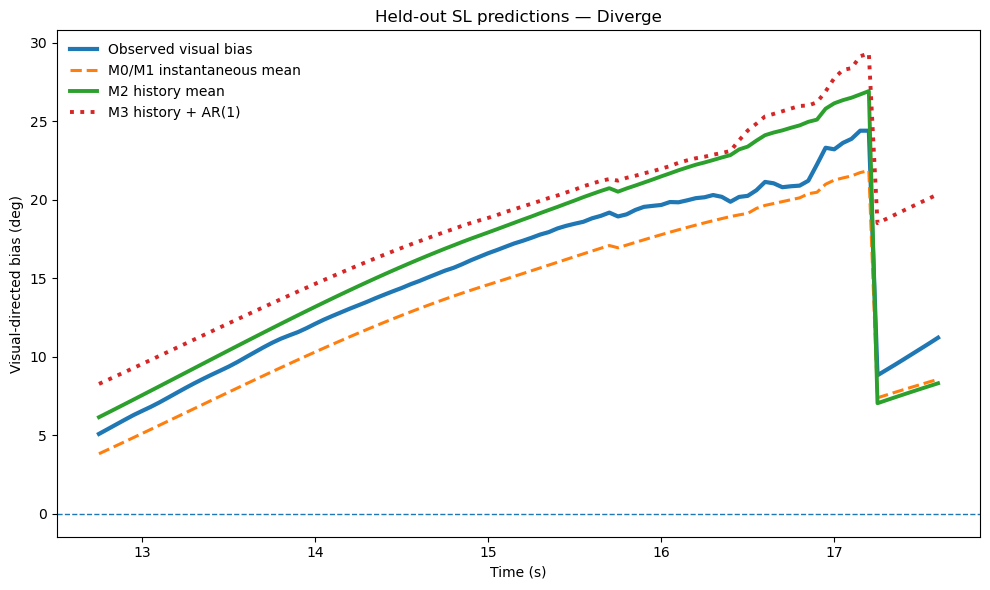

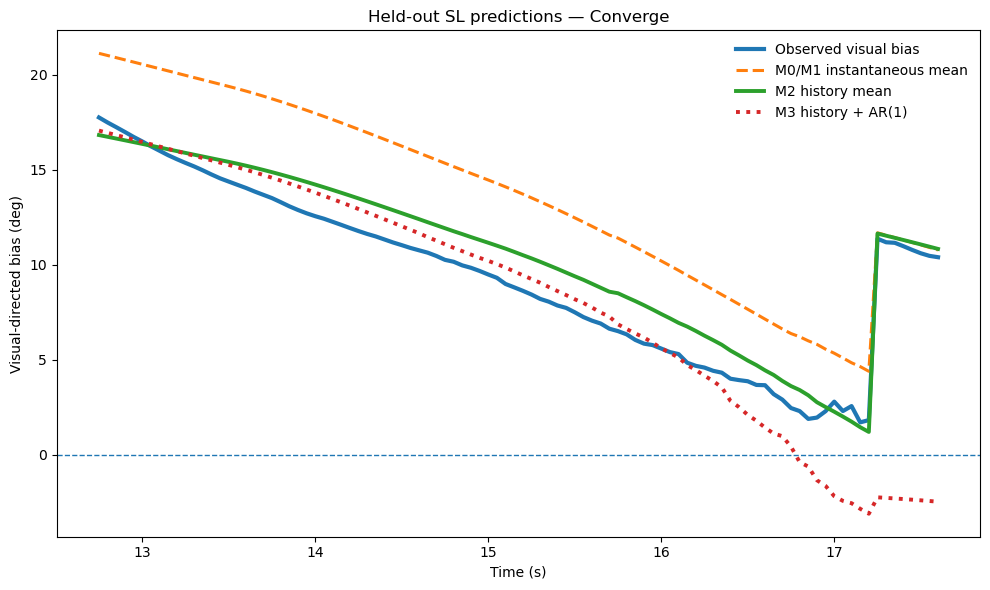

Saved: group_heldout_predictions_by_disparity.csv


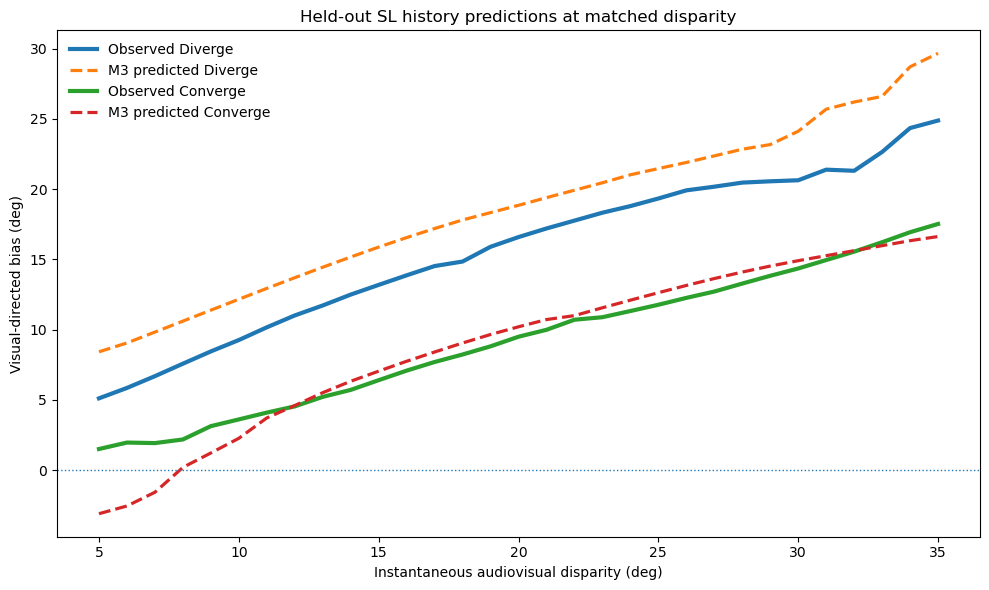

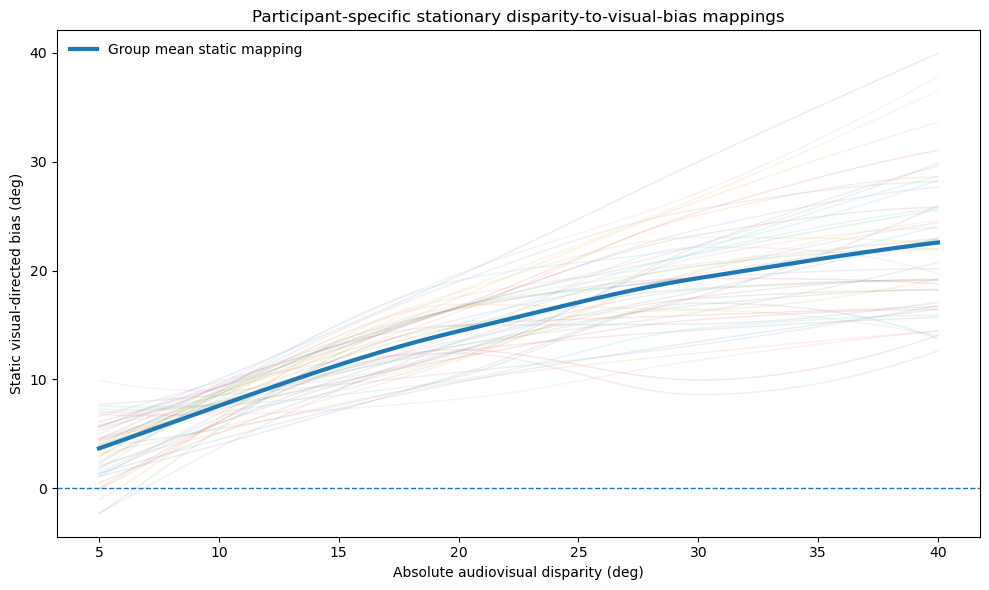

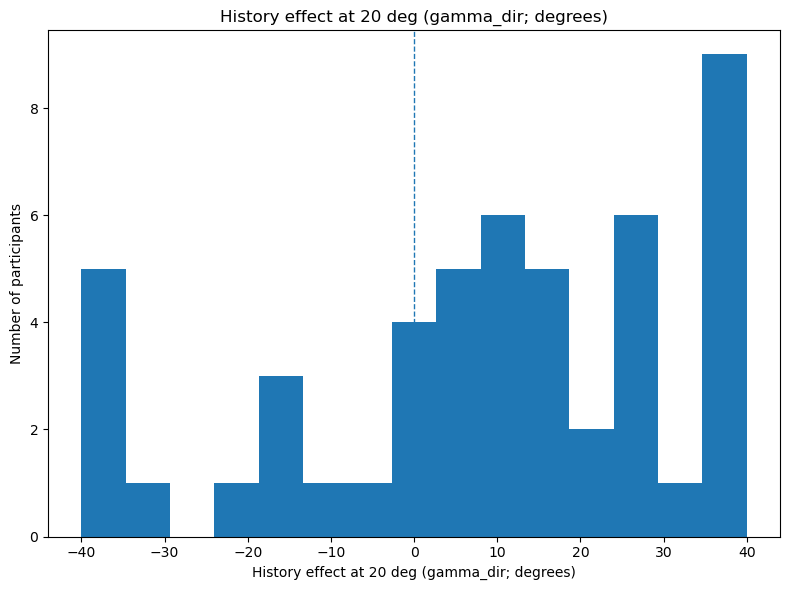

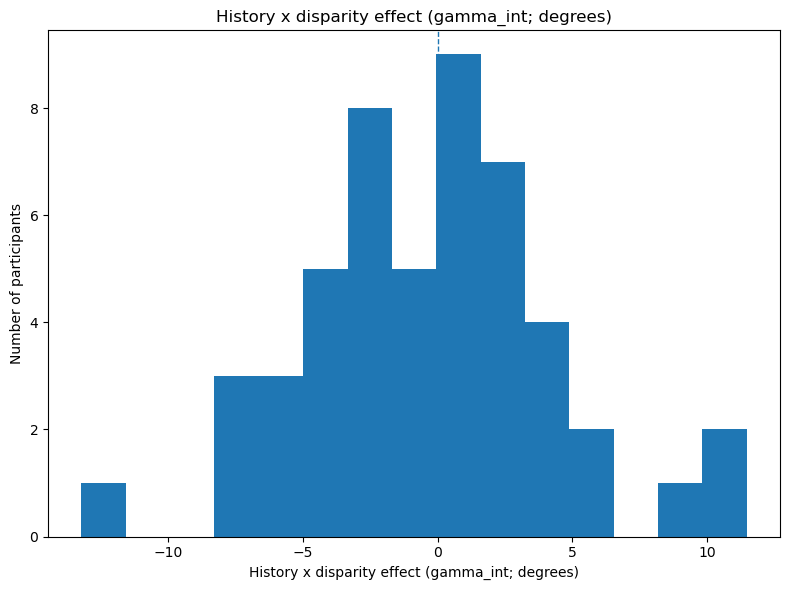

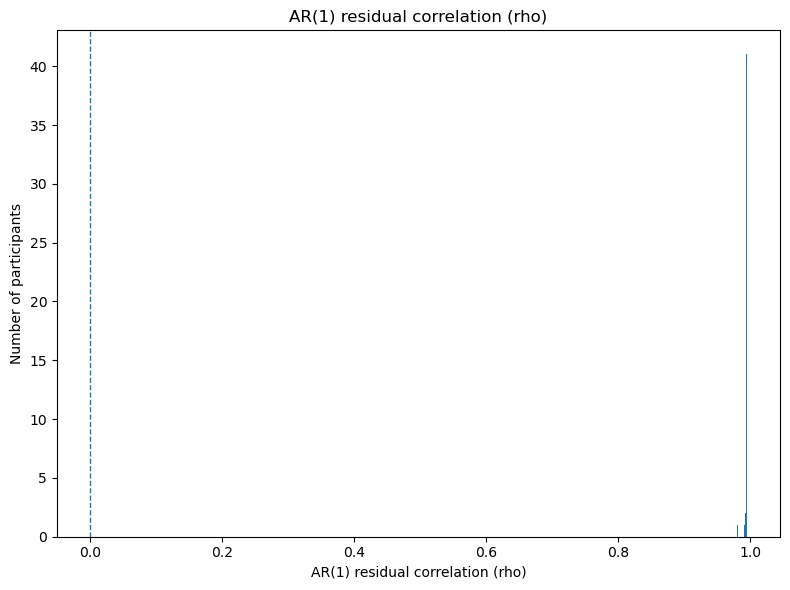

Saved: analysis_settings.csv

All primary expected output files were successfully created.

HISTORY-DEPENDENT SPATIAL-LOCALIZATION MODEL

Participants modeled: 50
Whole-trial CV folds: 5
Model sampling frequency: 20.0 Hz
Baseline lag correction: True
Primary outcome: visual-directed localization bias in degrees.

M0: static disparity-to-bias mean + IID residuals.
M1: static disparity-to-bias mean + conditional AR(1) residuals.
M2: history-dependent disparity-to-bias mean + IID residuals.
M3: history-dependent disparity-to-bias mean + conditional AR(1) residuals.

PRIMARY PREDICTIVE TEST: M3 VS M1
Both models accommodate residual temporal dependence; only M3 allows sweep history to alter expected visual bias.
Held-out RMSE improvement (deg): M=-3.993477, median=-2.810543, 95% bootstrap CI [-5.195164, -2.895078], permutation p=0.000200, participants favoring M3=5/50.
Relative held-out predictive R2 improvement: M=-1.958578, median=-0.740943, 95% bootstrap CI [-3.119312, -1.107128], permu

In [23]:
# %% ==========================================================================
# HISTORY-DEPENDENT SPATIAL-LOCALIZATION MODEL WITH AR(1) RESIDUALS
# =============================================================================
#
# PURPOSE
# -------
# Apply the same model-comparison logic used in the continuous CI analysis
# to continuous spatial localization.
#
# Main question:
#
#   Is visual-directed localization bias determined only by CURRENT
#   audiovisual disparity, or does recent audiovisual HISTORY improve
#   prediction of unseen sweep trials?
#
#
# PRIMARY OUTCOME
# ---------------
# Continuous visual-directed bias in degrees:
#
#   bias_deg(t) =
#       [response(t) - audio(t)] * sign[visual(t) - audio(t)]
#
# Positive values = response displaced toward vision.
#
#
# IMPORTANT DIFFERENCE FROM THE CI MODEL
# --------------------------------------
# CI:
#   behavioral P(common) is bounded, so history was modeled on the logit scale.
#
# SL:
#   visual-directed bias is continuous in degrees, so the mean model is Gaussian:
#
#   mu_t = f_i(D_t)
#          + gamma_dir * H
#          + gamma_int * H * X_t
#
# where:
#   f_i(D_t) = participant-specific STATIC disparity -> visual-bias mapping
#   H = +0.5 for Diverge, -0.5 for Converge
#   X_t = (D_t - 20) / 20
#
#
# MODEL HIERARCHY
# ---------------
# M0: instantaneous static mean + IID residuals
# M1: instantaneous static mean + conditional AR(1) residual covariance
# M2: history-dependent mean + IID residuals
# M3: history-dependent mean + conditional AR(1) residual covariance
#
#
# PRIMARY TEST
# ------------
# M3 vs M1 on WHOLE held-out sweep trials.
#
# Both models account for serial temporal dependence.
# Only M3 lets audiovisual history change expected localization bias.
#
#
# RAW-DATA PIPELINE
# -----------------
# 1. Read *master_trials*.csv files directly.
# 2. Resample each trial to 10 Hz, matching the CI model analysis.
# 3. Estimate a participant-level baseline response lag using ONLY:
#       audio-only
#       visual-only
#       congruent AV
#    trials.
# 4. Apply this fixed participant-level lag correction to all AV trials.
# 5. Compute continuous visual-directed bias in degrees.
# 6. Learn each participant's STATIC disparity -> visual-bias mapping from
#    fixed 10/20/30/40-degree trials.
# 7. Predict diverging/converging sweep trials.
# 8. Fit M0-M3 with 5-fold whole-trial CV within participant.
# 9. Quantify held-out RMSE, predictive R2, correlation, log score.
# 10. Ask whether models reproduce matched-disparity localization hysteresis.
#
#
# HYSTERESIS SIGN
# ---------------
# The manuscript SL hysteresis is:
#
#     Converge - Diverge
#
# Negative = stronger visual bias during Diverge.
#
# =============================================================================


# =============================================================================
# IMPORTS
# =============================================================================

from pathlib import Path
import re
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.optimize import minimize, minimize_scalar
from scipy.interpolate import PchipInterpolator

warnings.filterwarnings("ignore", category=RuntimeWarning)


# =============================================================================
# USER SETTINGS
# =============================================================================

RANDOM_SEED = 20260825

DATA_DIR = Path(
    r"C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab"
    r"\Continuous AVT v1\individual_data_SL"
)

FILE_PATTERN = "*master_trials*.csv"


# -----------------------------------------------------------------------------
# UPDATED OUTPUT LOCATION
# -----------------------------------------------------------------------------
#
# ALL analysis output now goes directly to:
#
# C:\Users\pkell\OneDrive\Documents\Grad School\Shams Lab\
# Continuous AVT v1\individual_data_SL\analysis_models
#
# This deliberately removes the much longer intermediate directory from the
# previous version.
# -----------------------------------------------------------------------------

OUT_DIR = DATA_DIR / "analysis_models"
CSV_DIR = OUT_DIR / "csv_outputs"
FIG_DIR = OUT_DIR / "figures"


# Explicitly create and verify output directories before doing any analysis.
for directory in [
    OUT_DIR,
    CSV_DIR,
    FIG_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# Fail immediately if Windows/OneDrive was unable to create them.
for directory in [
    OUT_DIR,
    CSV_DIR,
    FIG_DIR,
]:
    if not directory.exists():
        raise FileNotFoundError(
            f"Could not create output directory:\n{directory}"
        )


print("=" * 90)
print("OUTPUT DIRECTORIES")
print("=" * 90)
print(f"Main output folder:\n{OUT_DIR}")
print(f"\nCSV output folder:\n{CSV_DIR}")
print(f"\nFigure output folder:\n{FIG_DIR}")
print()


# =============================================================================
# SAMPLING / TRIAL SETTINGS
# =============================================================================

TRIAL_DURATION_S = 18.0

MODEL_HZ = 20.0
MODEL_DT_S = 1.0 / MODEL_HZ

TIME_GRID = np.arange(
    0.0,
    TRIAL_DURATION_S + MODEL_DT_S / 2.0,
    MODEL_DT_S,
)

EXCLUDE_PRACTICE = True

TRIAL_TYPES_TO_KEEP = [
    "audio_only",
    "visual_only",
    "congruent",
    "incongruent_spatial",
    "incongruent_sweep",
]


# =============================================================================
# STATIC / DYNAMIC WINDOWS
# =============================================================================

STATIC_MAPPING_START_S = 0.5
STATIC_MAPPING_END_S = 17.5

DYNAMIC_START_S = 12.0
DYNAMIC_END_S = 18.0

HYSTERESIS_MIN_DEG = 5.0
HYSTERESIS_MAX_DEG = 35.0
HYSTERESIS_BIN_WIDTH_DEG = 2.0


# =============================================================================
# RESPONSE-LAG SETTINGS
# =============================================================================

USE_BASELINE_LAG_CORRECTION = True

MAX_LAG_SEC = 2.0
MIN_VALID_SAMPLES = 8

FALLBACK_TO_RAW_IF_LAG_MISSING = True


# =============================================================================
# MODEL SETTINGS
# =============================================================================

N_FOLDS = 5
MIN_SWEEP_TRIALS = 10
MIN_TRAIN_TRIALS = 6

N_BOOT = 5000
N_PERM = 5000

NUMERIC_VAR_FLOOR = 1e-12

RHO_LOWER = -0.995
RHO_UPPER = 0.995

GAMMA_ABS_MAIN = 40.0

RHO_BOUNDARY_TOL = 0.002
GAMMA_BOUNDARY_TOL = 0.25

SIGMA_DIAGNOSTIC_THRESHOLD = 0.05

INCLUDE_HISTORY_X_DISPARITY = True


# =============================================================================
# OPTIONAL PARAMETER-BOUND SENSITIVITY
# =============================================================================

RUN_FULL_CV_SENSITIVITY = True

SENSITIVITY_SETTINGS = [
    {
        "label": "rho_0p980_gamma40",
        "rho_upper": 0.980,
        "gamma_abs": 40.0,
    },
    {
        "label": "rho_0p995_gamma20",
        "rho_upper": 0.995,
        "gamma_abs": 20.0,
    },
    {
        "label": "rho_0p995_gamma80",
        "rho_upper": 0.995,
        "gamma_abs": 80.0,
    },
    {
        "label": "rho_0p999_gamma40",
        "rho_upper": 0.999,
        "gamma_abs": 40.0,
    },
]


# =============================================================================
# BASIC HELPERS
# =============================================================================

def normalize_subject_id(value):

    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    match = re.search(
        r"pid\s*0*(\d+)",
        text,
    )

    if match:
        return f"pid{int(match.group(1)):03d}"

    match = re.search(
        r"(\d+)",
        text,
    )

    if match:
        return f"pid{int(match.group(1)):03d}"

    return text


def extract_subject_id(filepath):

    name = Path(filepath).name

    match = re.search(
        r"(pid\d+)",
        name,
        flags=re.IGNORECASE,
    )

    if match:
        return normalize_subject_id(
            match.group(1)
        )

    return normalize_subject_id(
        Path(filepath).stem
    )


def safe_numeric(series):

    return pd.to_numeric(
        series,
        errors="coerce",
    )


def bootstrap_mean_ci(
    values,
    n_boot=N_BOOT,
    seed=RANDOM_SEED,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) < 2:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)

    boot = np.empty(
        n_boot,
        dtype=float,
    )

    for index in range(n_boot):

        boot[index] = np.mean(
            rng.choice(
                values,
                size=len(values),
                replace=True,
            )
        )

    return (
        float(np.percentile(boot, 2.5)),
        float(np.percentile(boot, 97.5)),
    )


def bootstrap_median_ci(
    values,
    n_boot=N_BOOT,
    seed=RANDOM_SEED,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) < 2:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)

    boot = np.empty(
        n_boot,
        dtype=float,
    )

    for index in range(n_boot):

        boot[index] = np.median(
            rng.choice(
                values,
                size=len(values),
                replace=True,
            )
        )

    return (
        float(np.percentile(boot, 2.5)),
        float(np.percentile(boot, 97.5)),
    )


def sign_flip_test(
    values,
    n_perm=N_PERM,
    seed=RANDOM_SEED,
    alternative="two-sided",
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) < 2:
        return np.nan

    observed = float(
        np.mean(values)
    )

    rng = np.random.default_rng(seed)

    null_means = np.empty(
        n_perm,
        dtype=float,
    )

    for index in range(n_perm):

        signs = rng.choice(
            [-1.0, 1.0],
            size=len(values),
        )

        null_means[index] = np.mean(
            values * signs
        )

    if alternative == "greater":

        return float(
            (
                np.sum(
                    null_means >= observed
                )
                + 1
            )
            / (n_perm + 1)
        )

    if alternative == "less":

        return float(
            (
                np.sum(
                    null_means <= observed
                )
                + 1
            )
            / (n_perm + 1)
        )

    return float(
        (
            np.sum(
                np.abs(null_means)
                >= abs(observed)
            )
            + 1
        )
        / (n_perm + 1)
    )


# =============================================================================
# RESAMPLING
# =============================================================================

def resample_trial(
    df_trial,
    time_grid,
):

    needed = [
        "t",
        "mouse_x",
        "blob_x",
        "audio_x",
    ]

    for column in needed:

        if column not in df_trial.columns:

            raise ValueError(
                f"Missing required column: {column}"
            )

    data = (
        df_trial
        .copy()
        .sort_values("t")
    )

    data["t"] = safe_numeric(
        data["t"]
    )

    for column in [
        "mouse_x",
        "blob_x",
        "audio_x",
    ]:

        data[column] = safe_numeric(
            data[column]
        )

    data = data[
        np.isfinite(data["t"])
    ].copy()

    data = data.drop_duplicates(
        subset="t",
        keep="first",
    )

    if len(data) < 5:
        return None

    original_time = (
        data["t"]
        .to_numpy(dtype=float)
    )

    original_time = (
        original_time
        - np.nanmin(original_time)
    )

    if np.nanmax(original_time) < 1.0:
        return None

    def interpolate_column(column):

        values = (
            data[column]
            .to_numpy(dtype=float)
        )

        valid = (
            np.isfinite(original_time)
            & np.isfinite(values)
        )

        if valid.sum() < 3:

            return np.full_like(
                time_grid,
                np.nan,
                dtype=float,
            )

        return np.interp(
            time_grid,
            original_time[valid],
            values[valid],
            left=np.nan,
            right=np.nan,
        )

    return {
        "time_s":
            time_grid.copy(),
        "mouse_x":
            interpolate_column("mouse_x"),
        "visual_x":
            interpolate_column("blob_x"),
        "audio_x":
            interpolate_column("audio_x"),
    }


# =============================================================================
# CROSS-CORRELATION / BASELINE LAG
# =============================================================================

def corr_1d(
    x,
    y,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    if valid.sum() < MIN_VALID_SAMPLES:
        return np.nan

    if (
        np.nanstd(x[valid]) < 1e-12
        or
        np.nanstd(y[valid]) < 1e-12
    ):
        return np.nan

    return float(
        np.corrcoef(
            x[valid],
            y[valid],
        )[0, 1]
    )


def lag_scanned_corr(
    response,
    stimulus,
    fs=MODEL_HZ,
    max_lag_sec=MAX_LAG_SEC,
):

    response = np.asarray(
        response,
        dtype=float,
    )

    stimulus = np.asarray(
        stimulus,
        dtype=float,
    )

    max_lag_samples = int(
        round(
            max_lag_sec * fs
        )
    )

    lag_samples_grid = np.arange(
        -max_lag_samples,
        max_lag_samples + 1,
    )

    best_corr = np.nan
    best_lag_samples = np.nan

    for lag_samples in lag_samples_grid:

        if lag_samples > 0:

            response_segment = response[
                lag_samples:
            ]

            stimulus_segment = stimulus[
                :-lag_samples
            ]

        elif lag_samples < 0:

            response_segment = response[
                :lag_samples
            ]

            stimulus_segment = stimulus[
                -lag_samples:
            ]

        else:

            response_segment = response
            stimulus_segment = stimulus

        correlation = corr_1d(
            response_segment,
            stimulus_segment,
        )

        if (
            np.isfinite(correlation)
            and (
                not np.isfinite(best_corr)
                or correlation > best_corr
            )
        ):

            best_corr = correlation
            best_lag_samples = lag_samples

    return {
        "peak_corr":
            best_corr,
        "lag_samples":
            best_lag_samples,
        "lag_sec": (
            best_lag_samples / fs
            if np.isfinite(best_lag_samples)
            else np.nan
        ),
    }


def lag_correct_response(
    response,
    time_s,
    lag_sec,
):

    response = np.asarray(
        response,
        dtype=float,
    )

    time_s = np.asarray(
        time_s,
        dtype=float,
    )

    if not np.isfinite(lag_sec):
        return response.copy()

    return np.interp(
        time_s + lag_sec,
        time_s,
        response,
        left=np.nan,
        right=np.nan,
    )


# =============================================================================
# CONDITION HELPERS
# =============================================================================

def get_fixed_offset(row):

    value = row.get(
        "offsetDeg",
        np.nan,
    )

    try:

        value = abs(
            float(value)
        )

        if np.isfinite(value):
            return value

    except Exception:
        pass

    condition = str(
        row.get(
            "condLabel",
            "",
        )
    ).lower()

    match = re.search(
        r"(10|20|30|40)",
        condition,
    )

    if match:

        return float(
            match.group(1)
        )

    return np.nan


def classify_condition(row):

    trial_type = str(
        row.get(
            "trialType",
            "",
        )
    ).strip().lower()

    condition = str(
        row.get(
            "condLabel",
            "",
        )
    ).strip().lower()

    ramp_type = str(
        row.get(
            "rampType",
            "",
        )
    ).strip().lower()

    if trial_type == "audio_only":
        return "audio_only"

    if trial_type == "visual_only":
        return "visual_only"

    if trial_type == "congruent":
        return "congruent"

    if trial_type == "incongruent_spatial":

        offset = get_fixed_offset(
            row
        )

        if np.isfinite(offset):

            return (
                f"fixed_"
                f"{int(round(offset))}"
            )

    if trial_type == "incongruent_sweep":

        combined = (
            condition
            + " "
            + ramp_type
        )

        if "diverge" in combined:
            return "sweep_diverge"

        if "converge" in combined:
            return "sweep_converge"

    return np.nan


# =============================================================================
# LOAD RAW FILES
# =============================================================================

raw_files = sorted(
    glob.glob(
        str(
            DATA_DIR
            / FILE_PATTERN
        )
    )
)

if len(raw_files) == 0:

    raise FileNotFoundError(
        f"No files matching {FILE_PATTERN} found in:\n"
        f"{DATA_DIR}"
    )


print("=" * 90)
print("LOADING RAW SPATIAL-LOCALIZATION FILES")
print("=" * 90)

print(
    f"Files found: "
    f"{len(raw_files)}"
)


trial_rows = []


for filepath in raw_files:

    participant_id = extract_subject_id(
        filepath
    )

    print(
        f"Loading "
        f"{participant_id}: "
        f"{Path(filepath).name}"
    )

    raw = pd.read_csv(
        filepath
    )

    required_columns = [
        "trialIndex",
        "trialType",
        "condLabel",
        "isPractice",
        "t",
        "mouse_x",
        "blob_x",
        "audio_x",
    ]

    missing_columns = [
        column
        for column
        in required_columns
        if column not in raw.columns
    ]

    if missing_columns:

        print(
            f"  SKIPPED: "
            f"missing {missing_columns}"
        )

        continue

    if EXCLUDE_PRACTICE:

        raw = raw[
            safe_numeric(
                raw["isPractice"]
            )
            == 0
        ].copy()

    raw["trialType"] = (
        raw["trialType"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    raw = raw[
        raw["trialType"]
        .isin(TRIAL_TYPES_TO_KEEP)
    ].copy()

    if len(raw) == 0:
        continue

    grouping_columns = [
        "trialIndex",
        "trialType",
        "condLabel",
    ]

    for (
        trial_index,
        trial_type,
        condition_label,
    ), trial_data in raw.groupby(
        grouping_columns,
        sort=False,
    ):

        resampled = resample_trial(
            trial_data,
            TIME_GRID,
        )

        if resampled is None:
            continue

        first_row = trial_data.iloc[0]

        row = {
            "participant_id":
                participant_id,
            "source_file":
                Path(filepath).name,
            "trial_id":
                str(trial_index),
            "trialType":
                str(trial_type).strip().lower(),
            "condLabel":
                str(condition_label),
            "time_s":
                resampled["time_s"],
            "mouse_x_raw":
                resampled["mouse_x"],
            "visual_x":
                resampled["visual_x"],
            "audio_x":
                resampled["audio_x"],
            "offsetDeg":
                first_row.get(
                    "offsetDeg",
                    np.nan,
                ),
            "sideSign":
                first_row.get(
                    "sideSign",
                    np.nan,
                ),
            "rampType":
                first_row.get(
                    "rampType",
                    np.nan,
                ),
        }

        row["analysis_group"] = (
            classify_condition(row)
        )

        if pd.isna(
            row["analysis_group"]
        ):
            continue

        trial_rows.append(row)


trial_df = pd.DataFrame(
    trial_rows
)


if len(trial_df) == 0:

    raise RuntimeError(
        "No usable spatial-localization trials were loaded."
    )


trial_df["participant_id"] = (
    trial_df["participant_id"]
    .apply(normalize_subject_id)
)


print(
    "\n"
    + "=" * 90
)

print(
    "RAW DATA LOADED / RESAMPLED"
)

print(
    "=" * 90
)

print(
    f"Participants: "
    f"{trial_df['participant_id'].nunique()}"
)

print(
    f"Trials: "
    f"{len(trial_df)}"
)

print(
    trial_df[
        "analysis_group"
    ].value_counts()
)


# =============================================================================
# ESTIMATE SUBJECT-LEVEL BASELINE RESPONSE LAGS
# =============================================================================

baseline_lag_trial_rows = []


for _, row in trial_df.iterrows():

    condition = row[
        "analysis_group"
    ]

    if condition not in [
        "audio_only",
        "visual_only",
        "congruent",
    ]:
        continue

    response = np.asarray(
        row["mouse_x_raw"],
        dtype=float,
    )

    audio = np.asarray(
        row["audio_x"],
        dtype=float,
    )

    visual = np.asarray(
        row["visual_x"],
        dtype=float,
    )

    if condition == "audio_only":

        target = audio
        target_name = "audio"

    elif condition == "visual_only":

        target = visual
        target_name = "visual"

    else:

        target = (
            audio
            + visual
        ) / 2.0

        target_name = "congruent_av"

    lag_result = lag_scanned_corr(
        response=response,
        stimulus=target,
        fs=MODEL_HZ,
        max_lag_sec=MAX_LAG_SEC,
    )

    baseline_lag_trial_rows.append(
        {
            "participant_id":
                row["participant_id"],
            "trial_id":
                row["trial_id"],
            "condition":
                condition,
            "target":
                target_name,
            "lag_sec":
                lag_result["lag_sec"],
            "peak_corr":
                lag_result["peak_corr"],
        }
    )


baseline_lag_trial_df = pd.DataFrame(
    baseline_lag_trial_rows
)


# Explicit path variable + parent verification
BASELINE_LAG_TRIAL_PATH = (
    CSV_DIR / "baseline_lag_trial_level.csv"
)

BASELINE_LAG_TRIAL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

baseline_lag_trial_df.to_csv(
    BASELINE_LAG_TRIAL_PATH,
    index=False,
)


subject_lag_df = (
    baseline_lag_trial_df
    .replace(
        [
            np.inf,
            -np.inf,
        ],
        np.nan,
    )
    .dropna(
        subset=["lag_sec"]
    )
    .groupby(
        "participant_id",
        as_index=False,
    )
    .agg(
        subject_baseline_lag_sec=(
            "lag_sec",
            "median",
        ),
        subject_baseline_lag_mean_sec=(
            "lag_sec",
            "mean",
        ),
        n_baseline_trials=(
            "lag_sec",
            "count",
        ),
        baseline_peak_corr_mean=(
            "peak_corr",
            "mean",
        ),
    )
)


subject_lag_df.to_csv(
    CSV_DIR
    / "subject_baseline_lag.csv",
    index=False,
)


subject_lag_lookup = dict(
    zip(
        subject_lag_df[
            "participant_id"
        ],
        subject_lag_df[
            "subject_baseline_lag_sec"
        ],
    )
)


print(
    "\n"
    + "=" * 90
)

print(
    "BASELINE LAG SUMMARY"
)

print(
    "=" * 90
)

print(
    subject_lag_df[
        "subject_baseline_lag_sec"
    ].describe()
)


# =============================================================================
# APPLY BASELINE LAG CORRECTION
# =============================================================================

response_arrays = []


for _, row in trial_df.iterrows():

    raw_response = np.asarray(
        row["mouse_x_raw"],
        dtype=float,
    )

    if not USE_BASELINE_LAG_CORRECTION:

        corrected = (
            raw_response.copy()
        )

    else:

        participant_lag = (
            subject_lag_lookup.get(
                row["participant_id"],
                np.nan,
            )
        )

        if np.isfinite(
            participant_lag
        ):

            corrected = lag_correct_response(
                response=
                    raw_response,
                time_s=
                    row["time_s"],
                lag_sec=
                    participant_lag,
            )

        elif FALLBACK_TO_RAW_IF_LAG_MISSING:

            corrected = (
                raw_response.copy()
            )

        else:

            corrected = np.full_like(
                raw_response,
                np.nan,
            )

    response_arrays.append(
        corrected
    )


trial_df[
    "response_x"
] = response_arrays


# =============================================================================
# CONTINUOUS VISUAL-DIRECTED BIAS
# =============================================================================

def continuous_visual_directed_bias_deg(
    response,
    visual,
    audio,
    minimum_disparity=1e-6,
):

    response = np.asarray(
        response,
        dtype=float,
    )

    visual = np.asarray(
        visual,
        dtype=float,
    )

    audio = np.asarray(
        audio,
        dtype=float,
    )

    signed_disparity = (
        visual
        - audio
    )

    absolute_disparity = np.abs(
        signed_disparity
    )

    visual_direction = np.sign(
        signed_disparity
    )

    bias = (
        response
        - audio
    ) * visual_direction

    invalid = (
        ~np.isfinite(response)
        | ~np.isfinite(visual)
        | ~np.isfinite(audio)
        | (
            absolute_disparity
            < minimum_disparity
        )
    )

    bias[invalid] = np.nan

    return (
        bias,
        absolute_disparity,
    )


continuous_bias_arrays = []
continuous_disparity_arrays = []


for _, row in trial_df.iterrows():

    bias, disparity = (
        continuous_visual_directed_bias_deg(
            response=
                row["response_x"],
            visual=
                row["visual_x"],
            audio=
                row["audio_x"],
        )
    )

    continuous_bias_arrays.append(
        bias
    )

    continuous_disparity_arrays.append(
        disparity
    )


trial_df[
    "visual_bias_deg"
] = continuous_bias_arrays

trial_df[
    "abs_disparity_deg"
] = continuous_disparity_arrays


# =============================================================================
# SAVE LONG MODEL INPUT FOR QC
# =============================================================================

long_rows = []


for _, row in trial_df.iterrows():

    for sample_index in range(
        len(row["time_s"])
    ):

        long_rows.append(
            {
                "participant_id":
                    row["participant_id"],
                "trial_id":
                    row["trial_id"],
                "analysis_group":
                    row["analysis_group"],
                "time_s":
                    row["time_s"][
                        sample_index
                    ],
                "response_x":
                    row["response_x"][
                        sample_index
                    ],
                "visual_x":
                    row["visual_x"][
                        sample_index
                    ],
                "audio_x":
                    row["audio_x"][
                        sample_index
                    ],
                "abs_disparity_deg":
                    row["abs_disparity_deg"][
                        sample_index
                    ],
                "visual_bias_deg":
                    row["visual_bias_deg"][
                        sample_index
                    ],
            }
        )


model_input_long_df = pd.DataFrame(
    long_rows
)


model_input_long_df.to_csv(
    CSV_DIR
    / "sl_history_model_input_10Hz_long.csv",
    index=False,
)


# =============================================================================
# STATIC DISPARITY -> VISUAL-BIAS MAPPING
# =============================================================================

STATIC_GROUPS = [
    "fixed_10",
    "fixed_20",
    "fixed_30",
    "fixed_40",
]


static_rows = []


for _, row in trial_df.iterrows():

    if row[
        "analysis_group"
    ] not in STATIC_GROUPS:

        continue

    time_s = np.asarray(
        row["time_s"],
        dtype=float,
    )

    disparity = np.asarray(
        row["abs_disparity_deg"],
        dtype=float,
    )

    bias = np.asarray(
        row["visual_bias_deg"],
        dtype=float,
    )

    stable_mask = (
        np.isfinite(time_s)
        & np.isfinite(disparity)
        & np.isfinite(bias)
        & (
            time_s
            >= STATIC_MAPPING_START_S
        )
        & (
            time_s
            <= STATIC_MAPPING_END_S
        )
    )

    if stable_mask.sum() < MIN_VALID_SAMPLES:
        continue

    nominal_offset = get_fixed_offset(
        row
    )

    if not np.isfinite(
        nominal_offset
    ):
        continue

    static_rows.append(
        {
            "participant_id":
                row["participant_id"],
            "trial_id":
                row["trial_id"],
            "offset_deg":
                float(nominal_offset),
            "mean_actual_disparity_deg":
                float(
                    np.nanmean(
                        disparity[
                            stable_mask
                        ]
                    )
                ),
            "mean_visual_bias_deg":
                float(
                    np.nanmean(
                        bias[
                            stable_mask
                        ]
                    )
                ),
        }
    )


static_trial_df = pd.DataFrame(
    static_rows
)


static_trial_df.to_csv(
    CSV_DIR
    / "static_fixed_trial_visual_bias.csv",
    index=False,
)


static_subject_curve = (
    static_trial_df
    .groupby(
        [
            "participant_id",
            "offset_deg",
        ],
        as_index=False,
    )
    .agg(
        mean_visual_bias_deg=(
            "mean_visual_bias_deg",
            "mean",
        ),
        sd_visual_bias_deg=(
            "mean_visual_bias_deg",
            "std",
        ),
        n_trials=(
            "trial_id",
            "nunique",
        ),
        mean_actual_disparity_deg=(
            "mean_actual_disparity_deg",
            "mean",
        ),
    )
)


static_subject_curve.to_csv(
    CSV_DIR
    / "static_visual_bias_subject_curve.csv",
    index=False,
)


# =============================================================================
# FIT PARTICIPANT-SPECIFIC PCHIP STATIC FUNCTIONS
# =============================================================================

static_model_lookup = {}
static_fit_rows = []


for participant_id, group in static_subject_curve.groupby(
    "participant_id"
):

    group = (
        group
        .dropna(
            subset=[
                "offset_deg",
                "mean_visual_bias_deg",
            ]
        )
        .sort_values(
            "offset_deg"
        )
    )

    x = group[
        "offset_deg"
    ].to_numpy(
        dtype=float
    )

    y = group[
        "mean_visual_bias_deg"
    ].to_numpy(
        dtype=float
    )

    if (
        len(x) < 4
        or np.unique(x).size < 4
    ):

        static_fit_rows.append(
            {
                "participant_id":
                    participant_id,
                "static_fit_success":
                    False,
                "static_curve_r2":
                    np.nan,
                "n_offsets":
                    len(
                        np.unique(x)
                    ),
            }
        )

        continue

    try:

        interpolator = (
            PchipInterpolator(
                x,
                y,
                extrapolate=True,
            )
        )

        fitted_y = interpolator(x)

        sse = float(
            np.sum(
                (
                    y - fitted_y
                ) ** 2
            )
        )

        sst = float(
            np.sum(
                (
                    y
                    - np.mean(y)
                ) ** 2
            )
        )

        r2 = (
            1.0
            - sse / sst
            if sst > 0
            else np.nan
        )

        static_model_lookup[
            participant_id
        ] = interpolator

        static_fit_rows.append(
            {
                "participant_id":
                    participant_id,
                "static_fit_success":
                    True,
                "static_curve_r2":
                    r2,
                "n_offsets":
                    len(
                        np.unique(x)
                    ),
                "bias_10":
                    float(
                        interpolator(10.0)
                    ),
                "bias_20":
                    float(
                        interpolator(20.0)
                    ),
                "bias_30":
                    float(
                        interpolator(30.0)
                    ),
                "bias_40":
                    float(
                        interpolator(40.0)
                    ),
            }
        )

    except Exception:

        static_fit_rows.append(
            {
                "participant_id":
                    participant_id,
                "static_fit_success":
                    False,
                "static_curve_r2":
                    np.nan,
                "n_offsets":
                    len(
                        np.unique(x)
                    ),
            }
        )


static_fit_df = pd.DataFrame(
    static_fit_rows
)


static_fit_df.to_csv(
    CSV_DIR
    / "static_visual_bias_model_parameters.csv",
    index=False,
)


def f_static(
    participant_id,
    disparity_deg,
):

    disparity_deg = np.asarray(
        disparity_deg,
        dtype=float,
    )

    interpolator = (
        static_model_lookup.get(
            participant_id
        )
    )

    if interpolator is None:

        return np.full_like(
            disparity_deg,
            np.nan,
            dtype=float,
        )

    predicted = np.asarray(
        interpolator(
            disparity_deg
        ),
        dtype=float,
    )

    return predicted


print(
    "\n"
    + "=" * 90
)

print(
    "STATIC VISUAL-BIAS MAPPING"
)

print(
    "=" * 90
)


static_summary_columns = [
    column
    for column in [
        "static_curve_r2",
        "bias_10",
        "bias_20",
        "bias_30",
        "bias_40",
    ]
    if column
    in static_fit_df.columns
]


print(
    static_fit_df[
        static_summary_columns
    ].describe()
)


# =============================================================================
# PREPARE DYNAMIC SWEEP TRIALS
# =============================================================================

SWEEP_GROUPS = [
    "sweep_diverge",
    "sweep_converge",
]

prepared_trials = []


for _, row in trial_df.iterrows():

    analysis_group = row[
        "analysis_group"
    ]

    if analysis_group not in SWEEP_GROUPS:
        continue

    participant_id = row[
        "participant_id"
    ]

    if participant_id not in static_model_lookup:
        continue

    time_s = np.asarray(
        row["time_s"],
        dtype=float,
    )

    disparity = np.asarray(
        row["abs_disparity_deg"],
        dtype=float,
    )

    observed = np.asarray(
        row["visual_bias_deg"],
        dtype=float,
    )

    dynamic_mask = (
        np.isfinite(time_s)
        & np.isfinite(disparity)
        & np.isfinite(observed)
        & (
            time_s
            >= DYNAMIC_START_S
        )
        & (
            time_s
            <= DYNAMIC_END_S
        )
        & (
            disparity
            >= HYSTERESIS_MIN_DEG
        )
        & (
            disparity
            <= HYSTERESIS_MAX_DEG
        )
    )

    if (
        dynamic_mask.sum()
        < MIN_VALID_SAMPLES
    ):
        continue

    time_dynamic = (
        time_s[
            dynamic_mask
        ]
    )

    disparity_dynamic = (
        disparity[
            dynamic_mask
        ]
    )

    observed_dynamic = (
        observed[
            dynamic_mask
        ]
    )

    equilibrium = f_static(
        participant_id,
        disparity_dynamic,
    )

    if not np.all(
        np.isfinite(equilibrium)
    ):
        continue

    if (
        analysis_group
        == "sweep_diverge"
    ):

        direction = "Diverge"
        history_code = 0.5

    else:

        direction = "Converge"
        history_code = -0.5

    disparity_scaled = (
        disparity_dynamic
        - 20.0
    ) / 20.0

    prepared_trials.append(
        {
            "participant_id":
                participant_id,
            "trial_id":
                row["trial_id"],
            "analysis_group":
                analysis_group,
            "direction":
                direction,
            "history_code":
                history_code,
            "time_s":
                time_dynamic,
            "disparity_deg":
                disparity_dynamic,
            "disparity_scaled":
                disparity_scaled,
            "observed":
                observed_dynamic,
            "equilibrium":
                equilibrium,
        }
    )


print(
    "\n"
    + "=" * 90
)

print(
    "PREPARED SWEEP MODEL DATA"
)

print(
    "=" * 90
)

print(
    f"Prepared sweep trials: "
    f"{len(prepared_trials)}"
)

print(
    f"Participants: "
    f"{len(set(t['participant_id'] for t in prepared_trials))}"
)


if len(prepared_trials) == 0:

    raise RuntimeError(
        "No sweep trials were prepared for modeling. "
        "Check condition labels, disparity values, and lag correction."
    )


# =============================================================================
# MEAN MODELS
# =============================================================================

def predict_instantaneous(
    trial,
):

    return np.asarray(
        trial["equilibrium"],
        dtype=float,
    ).copy()


def predict_history_mean(
    trial,
    gamma_dir,
    gamma_int=0.0,
):

    baseline = np.asarray(
        trial["equilibrium"],
        dtype=float,
    )

    history_code = float(
        trial["history_code"]
    )

    predicted = (
        baseline
        + gamma_dir
        * history_code
    )

    if INCLUDE_HISTORY_X_DISPARITY:

        predicted = (
            predicted
            + gamma_int
            * history_code
            * np.asarray(
                trial[
                    "disparity_scaled"
                ],
                dtype=float,
            )
        )

    return predicted


def get_trial_residuals(
    trials,
    model_name,
    gamma_dir=0.0,
    gamma_int=0.0,
):

    residual_sequences = []

    for trial in trials:

        observed = np.asarray(
            trial["observed"],
            dtype=float,
        )

        if model_name == "instantaneous":

            predicted = (
                predict_instantaneous(
                    trial
                )
            )

        elif model_name == "history":

            predicted = (
                predict_history_mean(
                    trial,
                    gamma_dir,
                    gamma_int,
                )
            )

        else:

            raise ValueError(
                f"Unknown model: "
                f"{model_name}"
            )

        valid = (
            np.isfinite(observed)
            & np.isfinite(predicted)
        )

        residual = (
            observed[valid]
            - predicted[valid]
        )

        if len(residual) >= 2:

            residual_sequences.append(
                residual
            )

    return residual_sequences


# =============================================================================
# IID GAUSSIAN RESIDUAL MODEL
# =============================================================================

def fit_iid_error(
    residual_sequences,
):

    if not residual_sequences:

        return {
            "sigma":
                np.nan,
            "loglik":
                -np.inf,
            "n_obs":
                0,
        }

    residual = np.concatenate(
        residual_sequences
    )

    residual = residual[
        np.isfinite(residual)
    ]

    if len(residual) < 2:

        return {
            "sigma":
                np.nan,
            "loglik":
                -np.inf,
            "n_obs":
                len(residual),
        }

    sigma2 = max(
        float(
            np.mean(
                residual ** 2
            )
        ),
        NUMERIC_VAR_FLOOR,
    )

    sigma = float(
        np.sqrt(sigma2)
    )

    n = len(residual)

    loglik = (
        -0.5
        * n
        * (
            np.log(
                2.0
                * np.pi
                * sigma2
            )
            + 1.0
        )
    )

    return {
        "sigma":
            sigma,
        "loglik":
            float(loglik),
        "n_obs":
            int(n),
    }


def iid_loglik_test(
    residual_sequences,
    sigma,
):

    sigma2 = max(
        float(sigma) ** 2,
        NUMERIC_VAR_FLOOR,
    )

    total_loglik = 0.0
    total_n = 0

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(residual)
        ]

        if len(residual) == 0:
            continue

        total_loglik += (
            -0.5
            * (
                len(residual)
                * np.log(
                    2.0
                    * np.pi
                    * sigma2
                )
                + np.sum(
                    residual ** 2
                )
                / sigma2
            )
        )

        total_n += len(residual)

    mean_score = (
        total_loglik / total_n
        if total_n > 0
        else np.nan
    )

    return (
        float(total_loglik),
        int(total_n),
        float(mean_score),
    )


# =============================================================================
# CONDITIONAL AR(1)
# =============================================================================

def ar1_profile_nll_given_rho(
    residual_sequences,
    rho,
    rho_lower,
    rho_upper,
):

    rho = float(
        np.clip(
            rho,
            rho_lower,
            rho_upper,
        )
    )

    innovation_ss = 0.0
    n_innovations = 0

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(residual)
        ]

        if len(residual) < 2:
            continue

        innovations = (
            residual[1:]
            - rho
            * residual[:-1]
        )

        innovation_ss += float(
            np.sum(
                innovations ** 2
            )
        )

        n_innovations += len(
            innovations
        )

    if n_innovations <= 0:
        return np.inf

    sigma2 = max(
        innovation_ss
        / n_innovations,
        NUMERIC_VAR_FLOOR,
    )

    return float(
        0.5
        * n_innovations
        * (
            np.log(
                2.0
                * np.pi
                * sigma2
            )
            + 1.0
        )
    )


def fit_ar1_error(
    residual_sequences,
    rho_lower=RHO_LOWER,
    rho_upper=RHO_UPPER,
):

    if not residual_sequences:

        return {
            "rho":
                np.nan,
            "sigma":
                np.nan,
            "loglik":
                -np.inf,
            "mean_logscore":
                np.nan,
            "n_innovations":
                0,
            "success":
                False,
            "rho_at_lower_bound":
                False,
            "rho_at_upper_bound":
                False,
            "sigma_below_diagnostic_threshold":
                False,
        }

    result = minimize_scalar(
        lambda rho:
            ar1_profile_nll_given_rho(
                residual_sequences,
                rho,
                rho_lower,
                rho_upper,
            ),
        bounds=(
            rho_lower,
            rho_upper,
        ),
        method="bounded",
        options={
            "xatol":
                1e-7,
        },
    )

    rho = float(
        result.x
    )

    innovation_ss = 0.0
    n_innovations = 0

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(residual)
        ]

        if len(residual) < 2:
            continue

        innovations = (
            residual[1:]
            - rho
            * residual[:-1]
        )

        innovation_ss += float(
            np.sum(
                innovations ** 2
            )
        )

        n_innovations += len(
            innovations
        )

    sigma2 = (
        max(
            innovation_ss
            / n_innovations,
            NUMERIC_VAR_FLOOR,
        )
        if n_innovations > 0
        else np.nan
    )

    sigma = (
        float(
            np.sqrt(sigma2)
        )
        if np.isfinite(sigma2)
        else np.nan
    )

    loglik = float(
        -result.fun
    )

    mean_logscore = (
        loglik
        / n_innovations
        if n_innovations > 0
        else np.nan
    )

    return {
        "rho":
            rho,
        "sigma":
            sigma,
        "loglik":
            loglik,
        "mean_logscore":
            mean_logscore,
        "n_innovations":
            int(n_innovations),
        "success":
            bool(result.success),
        "rho_at_lower_bound":
            bool(
                abs(
                    rho
                    - rho_lower
                )
                <= RHO_BOUNDARY_TOL
            ),
        "rho_at_upper_bound":
            bool(
                abs(
                    rho_upper
                    - rho
                )
                <= RHO_BOUNDARY_TOL
            ),
        "sigma_below_diagnostic_threshold":
            bool(
                np.isfinite(sigma)
                and sigma
                < SIGMA_DIAGNOSTIC_THRESHOLD
            ),
    }


def ar1_loglik_test(
    residual_sequences,
    rho,
    sigma,
    rho_lower=RHO_LOWER,
    rho_upper=RHO_UPPER,
):

    rho = float(
        np.clip(
            rho,
            rho_lower,
            rho_upper,
        )
    )

    sigma2 = max(
        float(sigma) ** 2,
        NUMERIC_VAR_FLOOR,
    )

    total_loglik = 0.0
    total_n = 0
    trial_scores = []

    for residual in residual_sequences:

        residual = np.asarray(
            residual,
            dtype=float,
        )

        residual = residual[
            np.isfinite(residual)
        ]

        if len(residual) < 2:
            continue

        innovations = (
            residual[1:]
            - rho
            * residual[:-1]
        )

        trial_loglik = (
            -0.5
            * (
                len(innovations)
                * np.log(
                    2.0
                    * np.pi
                    * sigma2
                )
                + np.sum(
                    innovations ** 2
                )
                / sigma2
            )
        )

        total_loglik += float(
            trial_loglik
        )

        total_n += len(
            innovations
        )

        trial_scores.append(
            float(
                trial_loglik
                / len(innovations)
            )
        )

    mean_score = (
        total_loglik
        / total_n
        if total_n > 0
        else np.nan
    )

    median_trial_score = (
        float(
            np.median(
                trial_scores
            )
        )
        if trial_scores
        else np.nan
    )

    return (
        float(total_loglik),
        int(total_n),
        float(mean_score),
        median_trial_score,
    )


# =============================================================================
# HISTORY PARAMETER FITTING
# =============================================================================

def gamma_bounds(
    gamma_abs,
):

    if INCLUDE_HISTORY_X_DISPARITY:

        return [
            (
                -gamma_abs,
                gamma_abs,
            ),
            (
                -gamma_abs,
                gamma_abs,
            ),
        ]

    return [
        (
            -gamma_abs,
            gamma_abs,
        )
    ]


def history_objective_iid(
    parameters,
    trials,
):

    gamma_dir = float(
        parameters[0]
    )

    gamma_int = (
        float(
            parameters[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    return -fit_iid_error(
        residuals
    )["loglik"]


def history_objective_ar1(
    parameters,
    trials,
    rho_lower,
    rho_upper,
):

    gamma_dir = float(
        parameters[0]
    )

    gamma_int = (
        float(
            parameters[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    return -fit_ar1_error(
        residuals,
        rho_lower,
        rho_upper,
    )["loglik"]


def fit_history_iid(
    trials,
    gamma_abs=GAMMA_ABS_MAIN,
):

    initial = np.zeros(
        2
        if INCLUDE_HISTORY_X_DISPARITY
        else 1
    )

    result = minimize(
        history_objective_iid,
        x0=initial,
        args=(trials,),
        method="L-BFGS-B",
        bounds=gamma_bounds(
            gamma_abs
        ),
    )

    gamma_dir = float(
        result.x[0]
    )

    gamma_int = (
        float(
            result.x[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    error_fit = fit_iid_error(
        residuals
    )

    return {
        "gamma_dir":
            gamma_dir,
        "gamma_int":
            gamma_int,
        "sigma":
            error_fit["sigma"],
        "train_loglik":
            error_fit["loglik"],
        "success":
            bool(result.success),
        "gamma_dir_at_bound":
            bool(
                abs(
                    abs(gamma_dir)
                    - gamma_abs
                )
                <= GAMMA_BOUNDARY_TOL
            ),
        "gamma_int_at_bound":
            bool(
                INCLUDE_HISTORY_X_DISPARITY
                and abs(
                    abs(gamma_int)
                    - gamma_abs
                )
                <= GAMMA_BOUNDARY_TOL
            ),
    }


def fit_history_ar1(
    trials,
    rho_lower=RHO_LOWER,
    rho_upper=RHO_UPPER,
    gamma_abs=GAMMA_ABS_MAIN,
):

    initial = np.zeros(
        2
        if INCLUDE_HISTORY_X_DISPARITY
        else 1
    )

    result = minimize(
        history_objective_ar1,
        x0=initial,
        args=(
            trials,
            rho_lower,
            rho_upper,
        ),
        method="L-BFGS-B",
        bounds=gamma_bounds(
            gamma_abs
        ),
    )

    gamma_dir = float(
        result.x[0]
    )

    gamma_int = (
        float(
            result.x[1]
        )
        if INCLUDE_HISTORY_X_DISPARITY
        else 0.0
    )

    residuals = get_trial_residuals(
        trials,
        "history",
        gamma_dir,
        gamma_int,
    )

    error_fit = fit_ar1_error(
        residuals,
        rho_lower,
        rho_upper,
    )

    return {
        "gamma_dir":
            gamma_dir,
        "gamma_int":
            gamma_int,
        "rho":
            error_fit["rho"],
        "sigma":
            error_fit["sigma"],
        "train_loglik":
            error_fit["loglik"],
        "mean_train_logscore":
            error_fit[
                "mean_logscore"
            ],
        "n_innovations":
            error_fit[
                "n_innovations"
            ],
        "success":
            bool(
                result.success
                and error_fit[
                    "success"
                ]
            ),
        "gamma_dir_at_bound":
            bool(
                abs(
                    abs(gamma_dir)
                    - gamma_abs
                )
                <= GAMMA_BOUNDARY_TOL
            ),
        "gamma_int_at_bound":
            bool(
                INCLUDE_HISTORY_X_DISPARITY
                and abs(
                    abs(gamma_int)
                    - gamma_abs
                )
                <= GAMMA_BOUNDARY_TOL
            ),
        "rho_at_lower_bound":
            error_fit[
                "rho_at_lower_bound"
            ],
        "rho_at_upper_bound":
            error_fit[
                "rho_at_upper_bound"
            ],
        "sigma_below_diagnostic_threshold":
            error_fit[
                "sigma_below_diagnostic_threshold"
            ],
    }


# =============================================================================
# CROSS-VALIDATION HELPERS
# =============================================================================

def make_trial_folds(
    trials,
    n_folds,
    seed,
):

    rng = np.random.default_rng(
        seed
    )

    folds = [
        []
        for _
        in range(n_folds)
    ]

    for direction in [
        "Diverge",
        "Converge",
    ]:

        direction_trials = [
            trial
            for trial
            in trials
            if trial["direction"]
            == direction
        ]

        indices = np.arange(
            len(direction_trials)
        )

        rng.shuffle(indices)

        for j, index in enumerate(
            indices
        ):

            folds[
                j % n_folds
            ].append(
                direction_trials[
                    index
                ]
            )

    return folds


def compute_prediction_metrics(
    observed,
    predicted,
):

    observed = np.asarray(
        observed,
        dtype=float,
    )

    predicted = np.asarray(
        predicted,
        dtype=float,
    )

    valid = (
        np.isfinite(observed)
        & np.isfinite(predicted)
    )

    observed = observed[
        valid
    ]

    predicted = predicted[
        valid
    ]

    n = len(observed)

    if n < 2:

        return {
            "n":
                n,
            "sse":
                np.nan,
            "rmse":
                np.nan,
            "mae":
                np.nan,
            "predictive_r2":
                np.nan,
            "pearson_r":
                np.nan,
        }

    residual = (
        observed
        - predicted
    )

    sse = float(
        np.sum(
            residual ** 2
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                residual ** 2
            )
        )
    )

    mae = float(
        np.mean(
            np.abs(residual)
        )
    )

    sst = float(
        np.sum(
            (
                observed
                - np.mean(observed)
            ) ** 2
        )
    )

    predictive_r2 = (
        1.0
        - sse / sst
        if sst > 0
        else np.nan
    )

    pearson_r = (
        float(
            np.corrcoef(
                observed,
                predicted,
            )[0, 1]
        )
        if (
            np.std(observed) > 1e-12
            and
            np.std(predicted) > 1e-12
        )
        else np.nan
    )

    return {
        "n":
            n,
        "sse":
            sse,
        "rmse":
            rmse,
        "mae":
            mae,
        "predictive_r2":
            predictive_r2,
        "pearson_r":
            pearson_r,
    }


# =============================================================================
# MAIN WHOLE-TRIAL CROSS-VALIDATION
# =============================================================================

participants = sorted(
    {
        trial["participant_id"]
        for trial
        in prepared_trials
    }
)


cv_fold_rows = []
heldout_rows = []
subject_rows = []
full_fit_rows = []


for subject_index, participant_id in enumerate(
    participants
):

    subject_trials = [
        trial
        for trial
        in prepared_trials
        if trial["participant_id"]
        == participant_id
    ]

    if len(subject_trials) < MIN_SWEEP_TRIALS:

        print(
            f"Skipping "
            f"{participant_id}: "
            f"only "
            f"{len(subject_trials)} "
            f"sweep trials."
        )

        continue

    effective_folds = min(
        N_FOLDS,
        len(subject_trials),
    )

    folds = make_trial_folds(
        subject_trials,
        effective_folds,
        RANDOM_SEED
        + subject_index,
    )


    pooled_observed = []

    pooled_predictions = {
        model_name: []
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    pooled_loglik = {
        model_name: 0.0
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    pooled_score_n = {
        model_name: 0
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }

    fold_gamma_dir_M2 = []
    fold_gamma_int_M2 = []

    fold_gamma_dir_M3 = []
    fold_gamma_int_M3 = []

    fold_rho_M1 = []
    fold_rho_M3 = []


    for fold_index in range(
        effective_folds
    ):

        test_trials = folds[
            fold_index
        ]

        train_trials = [
            trial
            for other_fold_index
            in range(
                effective_folds
            )
            if other_fold_index
            != fold_index
            for trial
            in folds[
                other_fold_index
            ]
        ]

        if (
            len(test_trials) == 0
            or
            len(train_trials)
            < MIN_TRAIN_TRIALS
        ):
            continue


        # ---------------------------------------------------------------------
        # M0 / M1
        # ---------------------------------------------------------------------

        train_residual_M0 = (
            get_trial_residuals(
                train_trials,
                "instantaneous",
            )
        )

        fit_M0_error = (
            fit_iid_error(
                train_residual_M0
            )
        )

        fit_M1_error = (
            fit_ar1_error(
                train_residual_M0,
                RHO_LOWER,
                RHO_UPPER,
            )
        )


        # ---------------------------------------------------------------------
        # M2 / M3
        # ---------------------------------------------------------------------

        fit_M2 = fit_history_iid(
            train_trials,
            gamma_abs=
                GAMMA_ABS_MAIN,
        )

        fit_M3 = fit_history_ar1(
            train_trials,
            rho_lower=
                RHO_LOWER,
            rho_upper=
                RHO_UPPER,
            gamma_abs=
                GAMMA_ABS_MAIN,
        )


        fold_gamma_dir_M2.append(
            fit_M2["gamma_dir"]
        )

        fold_gamma_int_M2.append(
            fit_M2["gamma_int"]
        )

        fold_gamma_dir_M3.append(
            fit_M3["gamma_dir"]
        )

        fold_gamma_int_M3.append(
            fit_M3["gamma_int"]
        )

        fold_rho_M1.append(
            fit_M1_error["rho"]
        )

        fold_rho_M3.append(
            fit_M3["rho"]
        )


        fold_observed = []

        fold_predictions = {
            model_name: []
            for model_name
            in [
                "M0",
                "M1",
                "M2",
                "M3",
            ]
        }

        fold_residuals = {
            model_name: []
            for model_name
            in [
                "M0",
                "M1",
                "M2",
                "M3",
            ]
        }


        for trial in test_trials:

            observed = np.asarray(
                trial["observed"],
                dtype=float,
            )

            pred_instantaneous = (
                predict_instantaneous(
                    trial
                )
            )

            pred_history_M2 = (
                predict_history_mean(
                    trial,
                    fit_M2[
                        "gamma_dir"
                    ],
                    fit_M2[
                        "gamma_int"
                    ],
                )
            )

            pred_history_M3 = (
                predict_history_mean(
                    trial,
                    fit_M3[
                        "gamma_dir"
                    ],
                    fit_M3[
                        "gamma_int"
                    ],
                )
            )

            predictions = {
                "M0":
                    pred_instantaneous.copy(),
                "M1":
                    pred_instantaneous.copy(),
                "M2":
                    pred_history_M2.copy(),
                "M3":
                    pred_history_M3.copy(),
            }

            fold_observed.extend(
                observed
            )

            pooled_observed.extend(
                observed
            )

            for (
                model_name,
                prediction,
            ) in predictions.items():

                fold_predictions[
                    model_name
                ].extend(
                    prediction
                )

                pooled_predictions[
                    model_name
                ].extend(
                    prediction
                )

                fold_residuals[
                    model_name
                ].append(
                    observed
                    - prediction
                )


            for sample_index in range(
                len(trial["time_s"])
            ):

                heldout_rows.append(
                    {
                        "participant_id":
                            participant_id,
                        "fold":
                            fold_index
                            + 1,
                        "trial_id":
                            trial[
                                "trial_id"
                            ],
                        "direction":
                            trial[
                                "direction"
                            ],
                        "time_s":
                            trial[
                                "time_s"
                            ][
                                sample_index
                            ],
                        "disparity_deg":
                            trial[
                                "disparity_deg"
                            ][
                                sample_index
                            ],
                        "observed_visual_bias_deg":
                            observed[
                                sample_index
                            ],
                        "static_visual_bias_deg":
                            pred_instantaneous[
                                sample_index
                            ],
                        "pred_M0":
                            predictions[
                                "M0"
                            ][
                                sample_index
                            ],
                        "pred_M1":
                            predictions[
                                "M1"
                            ][
                                sample_index
                            ],
                        "pred_M2":
                            predictions[
                                "M2"
                            ][
                                sample_index
                            ],
                        "pred_M3":
                            predictions[
                                "M3"
                            ][
                                sample_index
                            ],
                        "gamma_dir_M2_train":
                            fit_M2[
                                "gamma_dir"
                            ],
                        "gamma_int_M2_train":
                            fit_M2[
                                "gamma_int"
                            ],
                        "gamma_dir_M3_train":
                            fit_M3[
                                "gamma_dir"
                            ],
                        "gamma_int_M3_train":
                            fit_M3[
                                "gamma_int"
                            ],
                        "rho_M1_train":
                            fit_M1_error[
                                "rho"
                            ],
                        "rho_M3_train":
                            fit_M3[
                                "rho"
                            ],
                        "sigma_M1_train":
                            fit_M1_error[
                                "sigma"
                            ],
                        "sigma_M3_train":
                            fit_M3[
                                "sigma"
                            ],
                    }
                )


        (
            ll_M0,
            n_M0,
            score_M0,
        ) = iid_loglik_test(
            fold_residuals[
                "M0"
            ],
            fit_M0_error[
                "sigma"
            ],
        )

        (
            ll_M1,
            n_M1,
            score_M1,
            median_score_M1,
        ) = ar1_loglik_test(
            fold_residuals[
                "M1"
            ],
            fit_M1_error[
                "rho"
            ],
            fit_M1_error[
                "sigma"
            ],
            RHO_LOWER,
            RHO_UPPER,
        )

        (
            ll_M2,
            n_M2,
            score_M2,
        ) = iid_loglik_test(
            fold_residuals[
                "M2"
            ],
            fit_M2[
                "sigma"
            ],
        )

        (
            ll_M3,
            n_M3,
            score_M3,
            median_score_M3,
        ) = ar1_loglik_test(
            fold_residuals[
                "M3"
            ],
            fit_M3[
                "rho"
            ],
            fit_M3[
                "sigma"
            ],
            RHO_LOWER,
            RHO_UPPER,
        )


        fold_loglik = {
            "M0":
                ll_M0,
            "M1":
                ll_M1,
            "M2":
                ll_M2,
            "M3":
                ll_M3,
        }

        fold_nscore = {
            "M0":
                n_M0,
            "M1":
                n_M1,
            "M2":
                n_M2,
            "M3":
                n_M3,
        }

        fold_meanscore = {
            "M0":
                score_M0,
            "M1":
                score_M1,
            "M2":
                score_M2,
            "M3":
                score_M3,
        }


        for model_name in pooled_loglik:

            pooled_loglik[
                model_name
            ] += fold_loglik[
                model_name
            ]

            pooled_score_n[
                model_name
            ] += fold_nscore[
                model_name
            ]


        fold_observed_array = np.asarray(
            fold_observed,
            dtype=float,
        )


        for model_name in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]:

            metrics = (
                compute_prediction_metrics(
                    fold_observed_array,
                    np.asarray(
                        fold_predictions[
                            model_name
                        ],
                        dtype=float,
                    ),
                )
            )

            cv_fold_rows.append(
                {
                    "participant_id":
                        participant_id,
                    "fold":
                        fold_index
                        + 1,
                    "model":
                        model_name,
                    "n_train_trials":
                        len(
                            train_trials
                        ),
                    "n_test_trials":
                        len(
                            test_trials
                        ),
                    "gamma_dir_M2_train":
                        fit_M2[
                            "gamma_dir"
                        ],
                    "gamma_int_M2_train":
                        fit_M2[
                            "gamma_int"
                        ],
                    "gamma_dir_M3_train":
                        fit_M3[
                            "gamma_dir"
                        ],
                    "gamma_int_M3_train":
                        fit_M3[
                            "gamma_int"
                        ],
                    "rho_M1_train":
                        fit_M1_error[
                            "rho"
                        ],
                    "rho_M3_train":
                        fit_M3[
                            "rho"
                        ],
                    "sigma_M1_train":
                        fit_M1_error[
                            "sigma"
                        ],
                    "sigma_M3_train":
                        fit_M3[
                            "sigma"
                        ],
                    "rho_M1_at_upper_bound":
                        fit_M1_error[
                            "rho_at_upper_bound"
                        ],
                    "rho_M3_at_upper_bound":
                        fit_M3[
                            "rho_at_upper_bound"
                        ],
                    "gamma_dir_M3_at_bound":
                        fit_M3[
                            "gamma_dir_at_bound"
                        ],
                    "gamma_int_M3_at_bound":
                        fit_M3[
                            "gamma_int_at_bound"
                        ],
                    "heldout_conditional_loglik":
                        fold_loglik[
                            model_name
                        ],
                    "heldout_mean_logscore":
                        fold_meanscore[
                            model_name
                        ],
                    "heldout_n_score_terms":
                        fold_nscore[
                            model_name
                        ],
                    **metrics,
                }
            )


    # =========================================================================
    # PARTICIPANT-LEVEL POOLED HELD-OUT PERFORMANCE
    # =========================================================================

    pooled_observed_array = np.asarray(
        pooled_observed,
        dtype=float,
    )


    participant_metrics = {
        model_name:
            compute_prediction_metrics(
                pooled_observed_array,
                np.asarray(
                    pooled_predictions[
                        model_name
                    ],
                    dtype=float,
                ),
            )
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }


    mean_logscore = {
        model_name: (
            pooled_loglik[
                model_name
            ]
            / pooled_score_n[
                model_name
            ]
            if pooled_score_n[
                model_name
            ] > 0
            else np.nan
        )
        for model_name
        in [
            "M0",
            "M1",
            "M2",
            "M3",
        ]
    }


    sse_M0 = participant_metrics[
        "M0"
    ]["sse"]

    sse_M1 = participant_metrics[
        "M1"
    ]["sse"]

    sse_M2 = participant_metrics[
        "M2"
    ]["sse"]

    sse_M3 = participant_metrics[
        "M3"
    ]["sse"]


    rmse_M0 = participant_metrics[
        "M0"
    ]["rmse"]

    rmse_M1 = participant_metrics[
        "M1"
    ]["rmse"]

    rmse_M2 = participant_metrics[
        "M2"
    ]["rmse"]

    rmse_M3 = participant_metrics[
        "M3"
    ]["rmse"]


    delta_relative_r2_M2_vs_M0 = (
        1.0
        - sse_M2 / sse_M0
        if sse_M0 > 0
        else np.nan
    )

    delta_relative_r2_M3_vs_M1 = (
        1.0
        - sse_M3 / sse_M1
        if sse_M1 > 0
        else np.nan
    )


    subject_rows.append(
        {
            "participant_id":
                participant_id,
            "n_sweep_trials":
                len(subject_trials),
            "n_cv_folds":
                effective_folds,

            "mean_cv_gamma_dir_M2":
                np.nanmean(
                    fold_gamma_dir_M2
                ),

            "mean_cv_gamma_int_M2":
                np.nanmean(
                    fold_gamma_int_M2
                ),

            "mean_cv_gamma_dir_M3":
                np.nanmean(
                    fold_gamma_dir_M3
                ),

            "mean_cv_gamma_int_M3":
                np.nanmean(
                    fold_gamma_int_M3
                ),

            "mean_cv_rho_M1":
                np.nanmean(
                    fold_rho_M1
                ),

            "mean_cv_rho_M3":
                np.nanmean(
                    fold_rho_M3
                ),

            **{
                f"{model_name}_rmse":
                    participant_metrics[
                        model_name
                    ]["rmse"]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },

            **{
                f"{model_name}_predictive_r2":
                    participant_metrics[
                        model_name
                    ][
                        "predictive_r2"
                    ]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },

            **{
                f"{model_name}_pearson_r":
                    participant_metrics[
                        model_name
                    ][
                        "pearson_r"
                    ]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },

            **{
                f"{model_name}_conditional_loglik":
                    pooled_loglik[
                        model_name
                    ]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },

            **{
                f"{model_name}_mean_logscore":
                    mean_logscore[
                        model_name
                    ]
                for model_name
                in [
                    "M0",
                    "M1",
                    "M2",
                    "M3",
                ]
            },

            "delta_rmse_M2_vs_M0":
                rmse_M0
                - rmse_M2,

            "delta_rmse_M3_vs_M1":
                rmse_M1
                - rmse_M3,

            "delta_predictive_r2_M2_vs_M0":
                delta_relative_r2_M2_vs_M0,

            "delta_predictive_r2_M3_vs_M1":
                delta_relative_r2_M3_vs_M1,

            "delta_mean_logscore_M2_vs_M0":
                mean_logscore["M2"]
                - mean_logscore["M0"],

            "delta_mean_logscore_M3_vs_M1":
                mean_logscore["M3"]
                - mean_logscore["M1"],

            "delta_mean_logscore_M1_vs_M0":
                mean_logscore["M1"]
                - mean_logscore["M0"],

            "delta_mean_logscore_M3_vs_M2":
                mean_logscore["M3"]
                - mean_logscore["M2"],
        }
    )


    # =========================================================================
    # FULL-DATA DESCRIPTIVE PARAMETER FITS
    # =========================================================================

    full_M2 = fit_history_iid(
        subject_trials,
        gamma_abs=
            GAMMA_ABS_MAIN,
    )

    full_M3 = fit_history_ar1(
        subject_trials,
        rho_lower=
            RHO_LOWER,
        rho_upper=
            RHO_UPPER,
        gamma_abs=
            GAMMA_ABS_MAIN,
    )

    instantaneous_residuals = (
        get_trial_residuals(
            subject_trials,
            "instantaneous",
        )
    )

    full_M1 = fit_ar1_error(
        instantaneous_residuals,
        RHO_LOWER,
        RHO_UPPER,
    )


    full_fit_rows.append(
        {
            "participant_id":
                participant_id,

            "gamma_dir_M2_full":
                full_M2[
                    "gamma_dir"
                ],

            "gamma_int_M2_full":
                full_M2[
                    "gamma_int"
                ],

            "gamma_dir_M3_full":
                full_M3[
                    "gamma_dir"
                ],

            "gamma_int_M3_full":
                full_M3[
                    "gamma_int"
                ],

            "rho_M1_full":
                full_M1[
                    "rho"
                ],

            "rho_M3_full":
                full_M3[
                    "rho"
                ],

            "sigma_M1_full":
                full_M1[
                    "sigma"
                ],

            "sigma_M3_full":
                full_M3[
                    "sigma"
                ],

            "M2_fit_success":
                full_M2[
                    "success"
                ],

            "M3_fit_success":
                full_M3[
                    "success"
                ],

            "gamma_dir_M3_at_bound":
                full_M3[
                    "gamma_dir_at_bound"
                ],

            "gamma_int_M3_at_bound":
                full_M3[
                    "gamma_int_at_bound"
                ],

            "rho_M1_at_upper_bound":
                full_M1[
                    "rho_at_upper_bound"
                ],

            "rho_M3_at_upper_bound":
                full_M3[
                    "rho_at_upper_bound"
                ],

            "sigma_M1_small":
                full_M1[
                    "sigma_below_diagnostic_threshold"
                ],

            "sigma_M3_small":
                full_M3[
                    "sigma_below_diagnostic_threshold"
                ],
        }
    )


    print(
        f"Finished "
        f"{participant_id}: "
        f"DeltaRMSE(M3-M1)="
        f"{rmse_M1-rmse_M3:.4f} deg, "
        f"gamma_dir="
        f"{full_M3['gamma_dir']:.3f}, "
        f"gamma_int="
        f"{full_M3['gamma_int']:.3f}, "
        f"rho="
        f"{full_M3['rho']:.4f}"
    )


# =============================================================================
# CONVERT RESULTS TO DATAFRAMES
# =============================================================================

cv_fold_df = pd.DataFrame(
    cv_fold_rows
)

heldout_prediction_df = pd.DataFrame(
    heldout_rows
)

subject_cv_df = pd.DataFrame(
    subject_rows
)

full_fit_df = pd.DataFrame(
    full_fit_rows
)


# Safety checks before save
if len(subject_cv_df) == 0:

    raise RuntimeError(
        "No participant-level cross-validation results were produced. "
        "The model therefore cannot proceed to group inference."
    )


if len(full_fit_df) == 0:

    raise RuntimeError(
        "No full-data participant fits were produced. "
        "Check the prepared sweep trials and model-fitting output."
    )


# =============================================================================
# ROBUST SAVE HELPER
# =============================================================================

def save_csv_checked(
    dataframe,
    filename,
):

    path = (
        CSV_DIR
        / filename
    )

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    dataframe.to_csv(
        path,
        index=False,
    )

    if not path.exists():

        raise FileNotFoundError(
            f"CSV save failed:\n{path}"
        )

    print(
        f"Saved: {path.name}"
    )

    return path


# =============================================================================
# SAVE MAIN CV OUTPUTS
# =============================================================================

save_csv_checked(
    cv_fold_df,
    "whole_trial_cv_fold_metrics.csv",
)

save_csv_checked(
    heldout_prediction_df,
    "whole_trial_heldout_predictions.csv",
)

save_csv_checked(
    subject_cv_df,
    "subject_level_cv_model_comparison.csv",
)

save_csv_checked(
    full_fit_df,
    "subject_level_history_ar1_parameters_full_fit.csv",
)


# =============================================================================
# GROUP MODEL COMPARISONS
# =============================================================================

comparison_definitions = [
    (
        "M2_vs_M0_RMSE",
        "delta_rmse_M2_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M1_RMSE_PRIMARY",
        "delta_rmse_M3_vs_M1",
        "greater",
    ),
    (
        "M2_vs_M0_relative_predictive_R2",
        "delta_predictive_r2_M2_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M1_relative_predictive_R2_PRIMARY",
        "delta_predictive_r2_M3_vs_M1",
        "greater",
    ),
    (
        "M2_vs_M0_mean_logscore_SECONDARY",
        "delta_mean_logscore_M2_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M1_mean_logscore_SECONDARY",
        "delta_mean_logscore_M3_vs_M1",
        "greater",
    ),
    (
        "M1_vs_M0_AR1_mean_logscore",
        "delta_mean_logscore_M1_vs_M0",
        "greater",
    ),
    (
        "M3_vs_M2_AR1_mean_logscore",
        "delta_mean_logscore_M3_vs_M2",
        "greater",
    ),
]


group_test_rows = []


for comparison_index, (
    label,
    column,
    direction,
) in enumerate(
    comparison_definitions
):

    values = (
        subject_cv_df[
            column
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .dropna()
        .to_numpy(
            dtype=float
        )
    )

    if len(values) < 2:
        continue

    mean_value = float(
        np.mean(values)
    )

    median_value = float(
        np.median(values)
    )

    sd_value = float(
        np.std(
            values,
            ddof=1,
        )
    )

    t_value, parametric_p = (
        stats.ttest_1samp(
            values,
            0.0,
        )
    )

    ci_low, ci_high = (
        bootstrap_mean_ci(
            values,
            seed=
                RANDOM_SEED
                + comparison_index,
        )
    )

    median_ci_low, median_ci_high = (
        bootstrap_median_ci(
            values,
            seed=
                RANDOM_SEED
                + 1000
                + comparison_index,
        )
    )

    permutation_p_two_sided = (
        sign_flip_test(
            values,
            alternative=
                "two-sided",
            seed=
                RANDOM_SEED
                + 100
                + comparison_index,
        )
    )

    permutation_p_directional = (
        sign_flip_test(
            values,
            alternative=
                direction,
            seed=
                RANDOM_SEED
                + 200
                + comparison_index,
        )
    )

    try:

        wilcoxon = stats.wilcoxon(
            values,
            zero_method=
                "wilcox",
            alternative=
                "two-sided",
        )

        wilcoxon_stat = float(
            wilcoxon.statistic
        )

        wilcoxon_p = float(
            wilcoxon.pvalue
        )

    except Exception:

        wilcoxon_stat = np.nan
        wilcoxon_p = np.nan


    group_test_rows.append(
        {
            "comparison":
                label,
            "metric":
                column,
            "n":
                len(values),
            "mean":
                mean_value,
            "sd":
                sd_value,
            "median":
                median_value,
            "bootstrap_mean_ci_low":
                ci_low,
            "bootstrap_mean_ci_high":
                ci_high,
            "bootstrap_median_ci_low":
                median_ci_low,
            "bootstrap_median_ci_high":
                median_ci_high,
            "t":
                float(t_value),
            "parametric_p_two_sided":
                float(parametric_p),
            "permutation_p_two_sided":
                permutation_p_two_sided,
            "permutation_p_directional":
                permutation_p_directional,
            "wilcoxon_statistic":
                wilcoxon_stat,
            "wilcoxon_p_two_sided":
                wilcoxon_p,
            "n_positive":
                int(
                    np.sum(
                        values > 0
                    )
                ),
            "n_negative":
                int(
                    np.sum(
                        values < 0
                    )
                ),
            "n_zero":
                int(
                    np.sum(
                        values == 0
                    )
                ),
        }
    )


group_test_df = pd.DataFrame(
    group_test_rows
)


save_csv_checked(
    group_test_df,
    "group_model_comparison_tests.csv",
)


print(
    "\n"
    + "=" * 90
)

print(
    "GROUP MODEL COMPARISONS"
)

print(
    "=" * 90
)

print(
    group_test_df.to_string(
        index=False
    )
)


# =============================================================================
# GROUP MODEL PERFORMANCE
# =============================================================================

performance_rows = []


for model_index, model_name in enumerate(
    [
        "M0",
        "M1",
        "M2",
        "M3",
    ]
):

    rmse = subject_cv_df[
        f"{model_name}_rmse"
    ].to_numpy(
        dtype=float
    )

    r2 = subject_cv_df[
        f"{model_name}_predictive_r2"
    ].to_numpy(
        dtype=float
    )

    correlation = subject_cv_df[
        f"{model_name}_pearson_r"
    ].to_numpy(
        dtype=float
    )

    logscore = subject_cv_df[
        f"{model_name}_mean_logscore"
    ].to_numpy(
        dtype=float
    )

    rmse_ci = bootstrap_mean_ci(
        rmse,
        seed=
            RANDOM_SEED
            + 3000
            + model_index,
    )

    r2_ci = bootstrap_mean_ci(
        r2,
        seed=
            RANDOM_SEED
            + 3100
            + model_index,
    )

    score_ci = bootstrap_mean_ci(
        logscore,
        seed=
            RANDOM_SEED
            + 3200
            + model_index,
    )


    performance_rows.append(
        {
            "model":
                model_name,
            "n":
                int(
                    np.sum(
                        np.isfinite(
                            rmse
                        )
                    )
                ),
            "mean_rmse_deg":
                float(
                    np.nanmean(
                        rmse
                    )
                ),
            "rmse_ci_low":
                rmse_ci[0],
            "rmse_ci_high":
                rmse_ci[1],
            "mean_predictive_r2":
                float(
                    np.nanmean(
                        r2
                    )
                ),
            "predictive_r2_ci_low":
                r2_ci[0],
            "predictive_r2_ci_high":
                r2_ci[1],
            "mean_prediction_r":
                float(
                    np.nanmean(
                        correlation
                    )
                ),
            "mean_conditional_logscore":
                float(
                    np.nanmean(
                        logscore
                    )
                ),
            "conditional_logscore_ci_low":
                score_ci[0],
            "conditional_logscore_ci_high":
                score_ci[1],
        }
    )


model_performance_df = pd.DataFrame(
    performance_rows
)


save_csv_checked(
    model_performance_df,
    "group_model_performance_summary.csv",
)


# =============================================================================
# HELD-OUT MODEL-PREDICTED SPATIAL HYSTERESIS
# =============================================================================

hysteresis_rows = []


if len(
    heldout_prediction_df
) > 0:

    hysteresis_data = (
        heldout_prediction_df
        .copy()
    )

    bins = np.arange(
        HYSTERESIS_MIN_DEG,
        HYSTERESIS_MAX_DEG
        + HYSTERESIS_BIN_WIDTH_DEG,
        HYSTERESIS_BIN_WIDTH_DEG,
    )

    hysteresis_data[
        "disparity_bin"
    ] = pd.cut(
        hysteresis_data[
            "disparity_deg"
        ],
        bins=bins,
        include_lowest=True,
    )

    hysteresis_data[
        "disparity_bin_center"
    ] = (
        hysteresis_data[
            "disparity_bin"
        ]
        .apply(
            lambda interval:
                interval.mid
                if pd.notna(
                    interval
                )
                else np.nan
        )
        .astype(float)
    )


    measures = [
        "observed_visual_bias_deg",
        "pred_M0",
        "pred_M1",
        "pred_M2",
        "pred_M3",
    ]


    for participant_id, participant_group in hysteresis_data.groupby(
        "participant_id"
    ):

        for measure in measures:

            summary = (
                participant_group
                .groupby(
                    [
                        "direction",
                        "disparity_bin_center",
                    ],
                    as_index=False,
                    observed=True,
                )[
                    measure
                ]
                .mean()
            )

            pivot = summary.pivot(
                index=
                    "disparity_bin_center",
                columns=
                    "direction",
                values=
                    measure,
            )

            if (
                "Diverge"
                not in pivot.columns
                or
                "Converge"
                not in pivot.columns
            ):
                continue

            matched = pivot[
                [
                    "Diverge",
                    "Converge",
                ]
            ].dropna()

            if len(matched) < 3:
                continue

            hysteresis_index = float(
                np.mean(
                    matched[
                        "Converge"
                    ]
                    - matched[
                        "Diverge"
                    ]
                )
            )

            hysteresis_rows.append(
                {
                    "participant_id":
                        participant_id,
                    "measure":
                        measure,
                    "hysteresis_converge_minus_diverge_deg":
                        hysteresis_index,
                    "n_matched_bins":
                        len(matched),
                }
            )


model_hysteresis_df = pd.DataFrame(
    hysteresis_rows
)


save_csv_checked(
    model_hysteresis_df,
    "heldout_model_predicted_hysteresis_indices.csv",
)


hysteresis_summary_rows = []


if len(
    model_hysteresis_df
) > 0:

    for measure_index, (
        measure,
        group,
    ) in enumerate(
        model_hysteresis_df.groupby(
            "measure"
        )
    ):

        values = (
            group[
                "hysteresis_converge_minus_diverge_deg"
            ]
            .dropna()
            .to_numpy(
                dtype=float
            )
        )

        if len(values) < 2:
            continue

        ci_low, ci_high = (
            bootstrap_mean_ci(
                values,
                seed=
                    RANDOM_SEED
                    + 5000
                    + measure_index,
            )
        )

        t_value, p_value = (
            stats.ttest_1samp(
                values,
                0.0,
            )
        )

        permutation_p = (
            sign_flip_test(
                values,
                alternative=
                    "two-sided",
                seed=
                    RANDOM_SEED
                    + 6000
                    + measure_index,
            )
        )

        hysteresis_summary_rows.append(
            {
                "measure":
                    measure,
                "n":
                    len(values),
                "mean_hysteresis_deg":
                    float(
                        np.mean(values)
                    ),
                "sd_hysteresis_deg":
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    ),
                "bootstrap_ci_low":
                    ci_low,
                "bootstrap_ci_high":
                    ci_high,
                "t":
                    float(t_value),
                "parametric_p":
                    float(p_value),
                "permutation_p":
                    permutation_p,
            }
        )


model_hysteresis_summary_df = pd.DataFrame(
    hysteresis_summary_rows
)


save_csv_checked(
    model_hysteresis_summary_df,
    "heldout_model_predicted_hysteresis_summary.csv",
)


print(
    "\n"
    + "=" * 90
)

print(
    "HELD-OUT MODEL-PREDICTED SPATIAL HYSTERESIS"
)

print(
    "=" * 90
)


if len(
    model_hysteresis_summary_df
) > 0:

    print(
        model_hysteresis_summary_df.to_string(
            index=False
        )
    )


# =============================================================================
# PARAMETER SUMMARY
# =============================================================================

parameter_columns = [
    "gamma_dir_M2_full",
    "gamma_int_M2_full",
    "gamma_dir_M3_full",
    "gamma_int_M3_full",
    "rho_M1_full",
    "rho_M3_full",
]


parameter_summary_rows = []


for parameter_index, column in enumerate(
    parameter_columns
):

    values = (
        full_fit_df[
            column
        ]
        .replace(
            [
                np.inf,
                -np.inf,
            ],
            np.nan,
        )
        .dropna()
        .to_numpy(
            dtype=float
        )
    )

    if len(values) == 0:
        continue

    ci_low, ci_high = (
        bootstrap_mean_ci(
            values,
            seed=
                RANDOM_SEED
                + 7000
                + parameter_index,
        )
    )


    parameter_summary_rows.append(
        {
            "parameter":
                column,
            "n":
                len(values),
            "mean":
                float(
                    np.mean(values)
                ),
            "sd":
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                )
                if len(values) > 1
                else np.nan,
            "median":
                float(
                    np.median(values)
                ),
            "minimum":
                float(
                    np.min(values)
                ),
            "maximum":
                float(
                    np.max(values)
                ),
            "bootstrap_ci_low":
                ci_low,
            "bootstrap_ci_high":
                ci_high,
        }
    )


parameter_summary_df = pd.DataFrame(
    parameter_summary_rows
)


save_csv_checked(
    parameter_summary_df,
    "group_history_ar1_parameter_summary.csv",
)


# =============================================================================
# BOUNDARY DIAGNOSTICS
# =============================================================================

boundary_summary = pd.DataFrame(
    [
        {
            "diagnostic":
                "gamma_dir_M3_at_bound",
            "count":
                int(
                    full_fit_df[
                        "gamma_dir_M3_at_bound"
                    ].sum()
                ),
            "n":
                len(full_fit_df),
        },
        {
            "diagnostic":
                "gamma_int_M3_at_bound",
            "count":
                int(
                    full_fit_df[
                        "gamma_int_M3_at_bound"
                    ].sum()
                ),
            "n":
                len(full_fit_df),
        },
        {
            "diagnostic":
                "rho_M1_at_upper_bound",
            "count":
                int(
                    full_fit_df[
                        "rho_M1_at_upper_bound"
                    ].sum()
                ),
            "n":
                len(full_fit_df),
        },
        {
            "diagnostic":
                "rho_M3_at_upper_bound",
            "count":
                int(
                    full_fit_df[
                        "rho_M3_at_upper_bound"
                    ].sum()
                ),
            "n":
                len(full_fit_df),
        },
        {
            "diagnostic":
                "sigma_M3_below_threshold",
            "count":
                int(
                    full_fit_df[
                        "sigma_M3_small"
                    ].sum()
                ),
            "n":
                len(full_fit_df),
        },
    ]
)


save_csv_checked(
    boundary_summary,
    "parameter_boundary_diagnostics.csv",
)


# =============================================================================
# OPTIONAL BOUND SENSITIVITY
# =============================================================================

def run_primary_bound_sensitivity_cv(
    rho_upper,
    gamma_abs,
    label,
):

    rho_lower = -float(
        rho_upper
    )

    rows = []


    for subject_index, participant_id in enumerate(
        participants
    ):

        subject_trials = [
            trial
            for trial
            in prepared_trials
            if trial[
                "participant_id"
            ]
            == participant_id
        ]

        if len(
            subject_trials
        ) < MIN_SWEEP_TRIALS:
            continue

        effective_folds = min(
            N_FOLDS,
            len(subject_trials),
        )

        folds = make_trial_folds(
            subject_trials,
            effective_folds,
            RANDOM_SEED
            + 100000
            + subject_index,
        )

        observed_all = []
        pred_M1_all = []
        pred_M3_all = []


        for fold_index in range(
            effective_folds
        ):

            test_trials = folds[
                fold_index
            ]

            train_trials = [
                trial
                for other_index
                in range(
                    effective_folds
                )
                if other_index
                != fold_index
                for trial
                in folds[
                    other_index
                ]
            ]

            if (
                not test_trials
                or
                len(train_trials)
                < MIN_TRAIN_TRIALS
            ):
                continue


            fit_M3 = fit_history_ar1(
                train_trials,
                rho_lower=
                    rho_lower,
                rho_upper=
                    rho_upper,
                gamma_abs=
                    gamma_abs,
            )


            for trial in test_trials:

                observed = np.asarray(
                    trial["observed"],
                    dtype=float,
                )

                pred_M1 = (
                    predict_instantaneous(
                        trial
                    )
                )

                pred_M3 = (
                    predict_history_mean(
                        trial,
                        fit_M3[
                            "gamma_dir"
                        ],
                        fit_M3[
                            "gamma_int"
                        ],
                    )
                )

                observed_all.extend(
                    observed
                )

                pred_M1_all.extend(
                    pred_M1
                )

                pred_M3_all.extend(
                    pred_M3
                )


        observed_array = np.asarray(
            observed_all,
            dtype=float,
        )

        metrics_M1 = (
            compute_prediction_metrics(
                observed_array,
                np.asarray(
                    pred_M1_all,
                    dtype=float,
                ),
            )
        )

        metrics_M3 = (
            compute_prediction_metrics(
                observed_array,
                np.asarray(
                    pred_M3_all,
                    dtype=float,
                ),
            )
        )

        relative_r2 = (
            1.0
            - metrics_M3["sse"]
            / metrics_M1["sse"]
            if metrics_M1["sse"] > 0
            else np.nan
        )


        rows.append(
            {
                "setting":
                    label,
                "participant_id":
                    participant_id,
                "rho_upper":
                    rho_upper,
                "gamma_abs":
                    gamma_abs,
                "M1_rmse":
                    metrics_M1[
                        "rmse"
                    ],
                "M3_rmse":
                    metrics_M3[
                        "rmse"
                    ],
                "delta_rmse_M3_vs_M1":
                    metrics_M1[
                        "rmse"
                    ]
                    - metrics_M3[
                        "rmse"
                    ],
                "delta_relative_predictive_r2_M3_vs_M1":
                    relative_r2,
            }
        )


    return pd.DataFrame(
        rows
    )


sensitivity_summary_df = pd.DataFrame()


if RUN_FULL_CV_SENSITIVITY:

    sensitivity_frames = []


    for setting in SENSITIVITY_SETTINGS:

        print(
            f"\nRunning sensitivity: "
            f"{setting['label']}"
        )

        sensitivity_frames.append(
            run_primary_bound_sensitivity_cv(
                rho_upper=
                    setting[
                        "rho_upper"
                    ],
                gamma_abs=
                    setting[
                        "gamma_abs"
                    ],
                label=
                    setting[
                        "label"
                    ],
            )
        )


    nonempty_sensitivity_frames = [
        frame
        for frame
        in sensitivity_frames
        if len(frame) > 0
    ]


    if nonempty_sensitivity_frames:

        sensitivity_cv_df = pd.concat(
            nonempty_sensitivity_frames,
            ignore_index=True,
        )


        save_csv_checked(
            sensitivity_cv_df,
            "bound_sensitivity_primary_cv_subjects.csv",
        )


        sensitivity_summary_rows = []


        for (
            setting_label,
            group,
        ) in sensitivity_cv_df.groupby(
            "setting"
        ):

            for metric in [
                "delta_rmse_M3_vs_M1",
                "delta_relative_predictive_r2_M3_vs_M1",
            ]:

                values = (
                    group[
                        metric
                    ]
                    .dropna()
                    .to_numpy(
                        dtype=float
                    )
                )

                if len(values) < 2:
                    continue

                ci_low, ci_high = (
                    bootstrap_mean_ci(
                        values,
                        seed=
                            RANDOM_SEED
                            + 9000
                            + len(
                                sensitivity_summary_rows
                            ),
                    )
                )


                sensitivity_summary_rows.append(
                    {
                        "setting":
                            setting_label,
                        "metric":
                            metric,
                        "n":
                            len(values),
                        "mean":
                            float(
                                np.mean(values)
                            ),
                        "median":
                            float(
                                np.median(values)
                            ),
                        "bootstrap_ci_low":
                            ci_low,
                        "bootstrap_ci_high":
                            ci_high,
                        "permutation_p_two_sided":
                            sign_flip_test(
                                values,
                                alternative=
                                    "two-sided",
                                seed=
                                    RANDOM_SEED
                                    + 10000
                                    + len(
                                        sensitivity_summary_rows
                                    ),
                            ),
                        "n_positive":
                            int(
                                np.sum(
                                    values > 0
                                )
                            ),
                        "n_negative":
                            int(
                                np.sum(
                                    values < 0
                                )
                            ),
                    }
                )


        sensitivity_summary_df = pd.DataFrame(
            sensitivity_summary_rows
        )


        save_csv_checked(
            sensitivity_summary_df,
            "bound_sensitivity_primary_cv_summary.csv",
        )


# =============================================================================
# GROUP HELD-OUT TRAJECTORIES
# =============================================================================

if len(
    heldout_prediction_df
) > 0:

    participant_prediction_df = (
        heldout_prediction_df
        .groupby(
            [
                "participant_id",
                "direction",
                "time_s",
            ],
            as_index=False,
        )
        .agg(
            observed_visual_bias_deg=(
                "observed_visual_bias_deg",
                "mean",
            ),
            pred_M0=(
                "pred_M0",
                "mean",
            ),
            pred_M1=(
                "pred_M1",
                "mean",
            ),
            pred_M2=(
                "pred_M2",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
        )
    )


    group_prediction_df = (
        participant_prediction_df
        .groupby(
            [
                "direction",
                "time_s",
            ],
            as_index=False,
        )
        .agg(
            observed_visual_bias_deg=(
                "observed_visual_bias_deg",
                "mean",
            ),
            pred_M0=(
                "pred_M0",
                "mean",
            ),
            pred_M1=(
                "pred_M1",
                "mean",
            ),
            pred_M2=(
                "pred_M2",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
            n_participants=(
                "participant_id",
                "nunique",
            ),
        )
    )


    save_csv_checked(
        group_prediction_df,
        "group_heldout_prediction_trajectories.csv",
    )


    for direction in [
        "Diverge",
        "Converge",
    ]:

        plot_data = (
            group_prediction_df[
                group_prediction_df[
                    "direction"
                ]
                == direction
            ]
            .sort_values(
                "time_s"
            )
        )

        if len(plot_data) == 0:
            continue

        plt.figure(
            figsize=(
                10,
                6,
            )
        )

        plt.plot(
            plot_data[
                "time_s"
            ],
            plot_data[
                "observed_visual_bias_deg"
            ],
            linewidth=3.0,
            label=
                "Observed visual bias",
        )

        plt.plot(
            plot_data[
                "time_s"
            ],
            plot_data[
                "pred_M0"
            ],
            linestyle="--",
            linewidth=2.2,
            label=
                "M0/M1 instantaneous mean",
        )

        plt.plot(
            plot_data[
                "time_s"
            ],
            plot_data[
                "pred_M2"
            ],
            linewidth=2.8,
            label=
                "M2 history mean",
        )

        plt.plot(
            plot_data[
                "time_s"
            ],
            plot_data[
                "pred_M3"
            ],
            linestyle=":",
            linewidth=2.8,
            label=
                "M3 history + AR(1)",
        )

        plt.axhline(
            0.0,
            linestyle="--",
            linewidth=1.0,
        )

        plt.xlabel(
            "Time (s)"
        )

        plt.ylabel(
            "Visual-directed bias (deg)"
        )

        plt.title(
            f"Held-out SL predictions — "
            f"{direction}"
        )

        plt.legend(
            frameon=False
        )

        plt.tight_layout()

        figure_path = (
            FIG_DIR
            / (
                "heldout_group_prediction_"
                f"{direction.lower()}.png"
            )
        )

        figure_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        plt.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


# =============================================================================
# HELD-OUT MATCHED-DISPARITY PLOT
# =============================================================================

if len(
    heldout_prediction_df
) > 0:

    matched_plot_df = (
        heldout_prediction_df
        .copy()
    )

    matched_plot_df[
        "disparity_bin_round"
    ] = np.round(
        matched_plot_df[
            "disparity_deg"
        ]
    )


    participant_disparity_df = (
        matched_plot_df
        .groupby(
            [
                "participant_id",
                "direction",
                "disparity_bin_round",
            ],
            as_index=False,
        )
        .agg(
            observed_visual_bias_deg=(
                "observed_visual_bias_deg",
                "mean",
            ),
            pred_M1=(
                "pred_M1",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
        )
    )


    group_disparity_df = (
        participant_disparity_df
        .groupby(
            [
                "direction",
                "disparity_bin_round",
            ],
            as_index=False,
        )
        .agg(
            observed_visual_bias_deg=(
                "observed_visual_bias_deg",
                "mean",
            ),
            pred_M1=(
                "pred_M1",
                "mean",
            ),
            pred_M3=(
                "pred_M3",
                "mean",
            ),
            n_participants=(
                "participant_id",
                "nunique",
            ),
        )
    )


    save_csv_checked(
        group_disparity_df,
        "group_heldout_predictions_by_disparity.csv",
    )


    plt.figure(
        figsize=(
            10,
            6,
        )
    )


    for direction in [
        "Diverge",
        "Converge",
    ]:

        plot_data = (
            group_disparity_df[
                group_disparity_df[
                    "direction"
                ]
                == direction
            ]
            .sort_values(
                "disparity_bin_round"
            )
        )

        plt.plot(
            plot_data[
                "disparity_bin_round"
            ],
            plot_data[
                "observed_visual_bias_deg"
            ],
            linewidth=3.0,
            label=
                f"Observed "
                f"{direction}",
        )

        plt.plot(
            plot_data[
                "disparity_bin_round"
            ],
            plot_data[
                "pred_M3"
            ],
            linestyle="--",
            linewidth=2.3,
            label=
                f"M3 predicted "
                f"{direction}",
        )


    plt.axhline(
        0.0,
        linestyle=":",
        linewidth=1.0,
    )

    plt.xlabel(
        "Instantaneous audiovisual disparity (deg)"
    )

    plt.ylabel(
        "Visual-directed bias (deg)"
    )

    plt.title(
        "Held-out SL history predictions at matched disparity"
    )

    plt.legend(
        frameon=False
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR
        / "observed_vs_M3_by_matched_disparity.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


# =============================================================================
# STATIC MAPPING FIGURE
# =============================================================================

disparity_plot_grid = np.linspace(
    5.0,
    40.0,
    141,
)

plt.figure(
    figsize=(
        10,
        6,
    )
)

individual_static_predictions = []


for (
    participant_id,
    interpolator,
) in static_model_lookup.items():

    prediction = np.asarray(
        interpolator(
            disparity_plot_grid
        ),
        dtype=float,
    )

    individual_static_predictions.append(
        prediction
    )

    plt.plot(
        disparity_plot_grid,
        prediction,
        alpha=0.12,
        linewidth=1.0,
    )


if individual_static_predictions:

    group_static_prediction = np.nanmean(
        np.vstack(
            individual_static_predictions
        ),
        axis=0,
    )

    plt.plot(
        disparity_plot_grid,
        group_static_prediction,
        linewidth=3.0,
        label=
            "Group mean static mapping",
    )


plt.axhline(
    0.0,
    linestyle="--",
    linewidth=1.0,
)

plt.xlabel(
    "Absolute audiovisual disparity (deg)"
)

plt.ylabel(
    "Static visual-directed bias (deg)"
)

plt.title(
    "Participant-specific stationary disparity-to-visual-bias mappings"
)

plt.legend(
    frameon=False
)

plt.tight_layout()

plt.savefig(
    FIG_DIR
    / "static_visual_bias_mapping.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# =============================================================================
# PARAMETER HISTOGRAMS
# =============================================================================

parameter_plots = [
    (
        "gamma_dir_M3_full",
        "History effect at 20 deg (gamma_dir; degrees)",
        "gamma_direction_distribution.png",
    ),
    (
        "gamma_int_M3_full",
        "History x disparity effect (gamma_int; degrees)",
        "gamma_direction_x_disparity_distribution.png",
    ),
    (
        "rho_M3_full",
        "AR(1) residual correlation (rho)",
        "rho_M3_distribution.png",
    ),
]


for (
    parameter,
    label,
    filename,
) in parameter_plots:

    if (
        parameter
        not in full_fit_df.columns
    ):
        continue

    plt.figure(
        figsize=(
            8,
            6,
        )
    )

    plt.hist(
        full_fit_df[
            parameter
        ].dropna(),
        bins=15,
    )

    plt.axvline(
        0.0,
        linestyle="--",
        linewidth=1.0,
    )

    plt.xlabel(label)

    plt.ylabel(
        "Number of participants"
    )

    plt.title(label)

    plt.tight_layout()

    plt.savefig(
        FIG_DIR
        / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


# =============================================================================
# MANUSCRIPT-FRIENDLY SUMMARY
# =============================================================================

def get_group_row(label):

    match = group_test_df[
        group_test_df[
            "comparison"
        ]
        == label
    ]

    if len(match) == 1:

        return match.iloc[0]

    return None


primary_rmse = get_group_row(
    "M3_vs_M1_RMSE_PRIMARY"
)

primary_r2 = get_group_row(
    "M3_vs_M1_relative_predictive_R2_PRIMARY"
)

secondary_logscore = get_group_row(
    "M3_vs_M1_mean_logscore_SECONDARY"
)


report_lines = [
    "=" * 90,
    "HISTORY-DEPENDENT SPATIAL-LOCALIZATION MODEL",
    "=" * 90,
    "",
    (
        f"Participants modeled: "
        f"{subject_cv_df['participant_id'].nunique()}"
    ),
    (
        f"Whole-trial CV folds: "
        f"{N_FOLDS}"
    ),
    (
        f"Model sampling frequency: "
        f"{MODEL_HZ:.1f} Hz"
    ),
    (
        f"Baseline lag correction: "
        f"{USE_BASELINE_LAG_CORRECTION}"
    ),
    (
        "Primary outcome: visual-directed localization bias in degrees."
    ),
    "",
    (
        "M0: static disparity-to-bias mean + IID residuals."
    ),
    (
        "M1: static disparity-to-bias mean + conditional AR(1) residuals."
    ),
    (
        "M2: history-dependent disparity-to-bias mean + IID residuals."
    ),
    (
        "M3: history-dependent disparity-to-bias mean + conditional AR(1) residuals."
    ),
    "",
    "PRIMARY PREDICTIVE TEST: M3 VS M1",
    (
        "Both models accommodate residual temporal dependence; "
        "only M3 allows sweep history to alter expected visual bias."
    ),
]


for name, row in [
    (
        "Held-out RMSE improvement (deg)",
        primary_rmse,
    ),
    (
        "Relative held-out predictive R2 improvement",
        primary_r2,
    ),
    (
        "Conditional mean log-score improvement (secondary)",
        secondary_logscore,
    ),
]:

    if row is None:
        continue

    report_lines.append(
        (
            f"{name}: "
            f"M={row['mean']:.6f}, "
            f"median={row['median']:.6f}, "
            f"95% bootstrap CI "
            f"[{row['bootstrap_mean_ci_low']:.6f}, "
            f"{row['bootstrap_mean_ci_high']:.6f}], "
            f"permutation p="
            f"{row['permutation_p_two_sided']:.6f}, "
            f"participants favoring M3="
            f"{int(row['n_positive'])}/"
            f"{int(row['n'])}."
        )
    )


if len(
    model_hysteresis_summary_df
) > 0:

    report_lines += [
        "",
        "HELD-OUT HYSTERESIS",
    ]

    for _, row in (
        model_hysteresis_summary_df.iterrows()
    ):

        report_lines.append(
            (
                f"{row['measure']}: "
                f"Converge-Diverge="
                f"{row['mean_hysteresis_deg']:.4f} deg, "
                f"95% CI "
                f"[{row['bootstrap_ci_low']:.4f}, "
                f"{row['bootstrap_ci_high']:.4f}], "
                f"permutation p="
                f"{row['permutation_p']:.6f}."
            )
        )


report_lines += [
    "",
    "PARAMETER INTERPRETATION",
    (
        "gamma_dir is the Diverge-versus-Converge history effect at "
        "the centered 20-degree disparity. Because H is coded +0.5 "
        "for Diverge and -0.5 for Converge, a positive gamma_dir means "
        "greater visually directed localization during Diverge."
    ),
    (
        "gamma_int indicates how that history effect changes as current "
        "disparity moves away from 20 degrees."
    ),
    (
        "rho describes residual temporal autocorrelation only; it does not "
        "generate the predicted history-dependent mean."
    ),
    "",
    "INTERPRETIVE LIMIT",
    (
        "A superior M3 demonstrates that recent audiovisual history improves "
        "prediction of spatial localization beyond the participant's static "
        "disparity-to-bias mapping while serial residual dependence is modeled. "
        "It does not uniquely identify the perceptual or neural mechanism "
        "producing that history dependence."
    ),
]


report_text = "\n".join(
    report_lines
)


report_path = (
    OUT_DIR
    / "manuscript_friendly_sl_history_model_results.txt"
)


report_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)


report_path.write_text(
    report_text,
    encoding="utf-8",
)


# =============================================================================
# ANALYSIS SETTINGS
# =============================================================================

settings_df = pd.DataFrame(
    [
        {
            "setting":
                "random_seed",
            "value":
                RANDOM_SEED,
        },
        {
            "setting":
                "model_hz",
            "value":
                MODEL_HZ,
        },
        {
            "setting":
                "n_cv_folds",
            "value":
                N_FOLDS,
        },
        {
            "setting":
                "primary_outcome",
            "value":
                "visual_directed_bias_deg",
        },
        {
            "setting":
                "history_coding",
            "value":
                "Diverge=+0.5; Converge=-0.5",
        },
        {
            "setting":
                "disparity_scaling",
            "value":
                "(D-20)/20",
        },
        {
            "setting":
                "static_mapping",
            "value":
                (
                    "participant-specific PCHIP over "
                    "fixed 10/20/30/40 deg"
                ),
        },
        {
            "setting":
                "baseline_lag_correction",
            "value":
                USE_BASELINE_LAG_CORRECTION,
        },
        {
            "setting":
                "lag_source",
            "value":
                (
                    "median participant lag from "
                    "audio-only, visual-only, congruent trials"
                ),
        },
        {
            "setting":
                "dynamic_disparity_range_deg",
            "value":
                (
                    f"{HYSTERESIS_MIN_DEG}-"
                    f"{HYSTERESIS_MAX_DEG}"
                ),
        },
        {
            "setting":
                "rho_bounds",
            "value":
                f"[{RHO_LOWER}, {RHO_UPPER}]",
        },
        {
            "setting":
                "gamma_bounds",
            "value":
                (
                    f"[-{GAMMA_ABS_MAIN}, "
                    f"{GAMMA_ABS_MAIN}] degrees"
                ),
        },
        {
            "setting":
                "ar1_likelihood",
            "value":
                "conditional_on_first_residual",
        },
        {
            "setting":
                "primary_inference",
            "value":
                (
                    "M3_vs_M1 held-out RMSE and "
                    "relative predictive R2"
                ),
        },
        {
            "setting":
                "output_root",
            "value":
                str(
                    OUT_DIR
                ),
        },
    ]
)


save_csv_checked(
    settings_df,
    "analysis_settings.csv",
)


# =============================================================================
# FINAL OUTPUT VALIDATION
# =============================================================================

required_output_files = [
    CSV_DIR
    / "whole_trial_cv_fold_metrics.csv",

    CSV_DIR
    / "whole_trial_heldout_predictions.csv",

    CSV_DIR
    / "subject_level_cv_model_comparison.csv",

    CSV_DIR
    / "subject_level_history_ar1_parameters_full_fit.csv",

    CSV_DIR
    / "group_model_comparison_tests.csv",

    CSV_DIR
    / "group_model_performance_summary.csv",

    CSV_DIR
    / "group_history_ar1_parameter_summary.csv",

    CSV_DIR
    / "heldout_model_predicted_hysteresis_summary.csv",

    CSV_DIR
    / "analysis_settings.csv",

    report_path,
]


missing_outputs = [
    path
    for path
    in required_output_files
    if not path.exists()
]


if missing_outputs:

    print(
        "\nWARNING: The following expected outputs "
        "were not found:"
    )

    for path in missing_outputs:
        print(
            f"  {path}"
        )

else:

    print(
        "\nAll primary expected output files "
        "were successfully created."
    )


# =============================================================================
# FINAL PRINT
# =============================================================================

print(
    "\n"
    + report_text
)

print(
    "\n"
    + "=" * 90
)

print(
    "SPATIAL HISTORY MODEL ANALYSIS COMPLETE"
)

print(
    "=" * 90
)

print(
    f"\nALL OUTPUTS SAVED UNDER:\n"
    f"{OUT_DIR}"
)

print(
    f"\nCSV FILES:\n"
    f"{CSV_DIR}"
)

print(
    f"\nFIGURES:\n"
    f"{FIG_DIR}"
)

print(
    "\nPrimary files to inspect first:"
)


for path in [
    CSV_DIR
    / "group_model_comparison_tests.csv",

    CSV_DIR
    / "group_model_performance_summary.csv",

    CSV_DIR
    / "subject_level_cv_model_comparison.csv",

    CSV_DIR
    / "subject_level_history_ar1_parameters_full_fit.csv",

    CSV_DIR
    / "group_history_ar1_parameter_summary.csv",

    CSV_DIR
    / "heldout_model_predicted_hysteresis_summary.csv",

    CSV_DIR
    / "whole_trial_heldout_predictions.csv",

    CSV_DIR
    / "static_visual_bias_subject_curve.csv",

    CSV_DIR
    / "parameter_boundary_diagnostics.csv",

    CSV_DIR
    / "bound_sensitivity_primary_cv_summary.csv",

    report_path,
]:

    if Path(path).exists():

        print(
            path
        )